# 21 · Réseaux convolutifs (CNN) — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch21_cnn/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 21.Q1 à 21.Q12, 21.R1 à 21.R3, 21.1 à 21.6, 21.8 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★★ | |
| A | 21.12 | conv_output_size et pad2d | 🔨 | ★ | 15 |
|  | 21.13 | Prédire où une image CIFAR-10 « jaunit » | 🔮 | ★ | 10 |
|  | 21.14 | im2col : la vue « œil de mouche » | 🔨 | ★★ | 30 |
|  | 21.15 | conv2d : stride, padding, dilatation et groupes | 🔨 | ★★★ | 90 |
|  | 21.16 | Tests pytest paramétrés pour conv2d | 🛠️ | ★★ | 20 |
|  | 21.17 | Reproduire la chasse aux rayures verticales (Fig. 21.14) | 🎨 | ★★ | 20 |
|  | 21.18 | max_pool2d et avg_pool2d | 🔨 | ★★ | 25 |
| B | 21.19 | Flou, Sobel, netteté : des filtres faits main avec F.conv2d | 📦 | ★★ | 20 |
|  | 21.20 | Conv1d, noyau pleine largeur et 1×1 : prédire formes et paramètres | 🔮 | ★★ | 15 |
|  | 21.21 | Le détecteur de visage hiérarchique (Fig. 21.18 à 21.23) | 🎨 | ★★★ | 45 |
| C | 21.22 | Le convnet MNIST du livre en PyTorch, sur Fashion-MNIST | 📦 | ★★★ | 45 |
|  | 21.23 | Diagnostiquer les courbes et la matrice de confusion du CNN | 📈 | ★★ | 15 |
|  | 21.24 | Le CNN dont les formes ne passent pas | 🐛 | ★★ | 20 |
|  | 21.25 | Briser la symétrie : filtres identiques, aléatoires ou He | 🔬 | ★★ | 25 |
|  | 21.26 | Stride ou pooling : accuracy et temps sur CIFAR-10 | 🔬 | ★★★ | 40 |
| D | 21.27 | Filtres et cartes d'activation d'un ResNet-18 pré-entraîné | 📦 | ★★ | 30 |
|  | 21.28 | Ce qu'un filtre cherche : montée de gradient sur l'entrée | 📦 | ★★★ | 45 |
|  | 21.29 | Attaque FGSM contre ton CNN Fashion-MNIST | 📦 | ★★★ | 40 |
|  | 21.30 | conv_transpose2d par insertion de zéros | 🔨 | ★★★ | 50 |
|  | 21.31 | conv2d_backward : rétropropager à travers une convolution | 🔨 | ★★★★ | 100 |
|  | 21.32 | Défi Fashion-MNIST : au moins 92 % avec moins de 100 000 paramètres | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main la taille de sortie, le nombre de paramètres et le champ récepteur d'une pile de convolutions et de poolings.
- Programmer en NumPy, dans `mylearn.conv`, la convolution, `im2col`, le pooling, la convolution transposée et la rétropropagation, et les comparer à `torch.nn.functional`.
- Entraîner des CNN PyTorch, regarder leurs filtres et les tromper par une attaque adversariale.

**Rappel express.** Une couche de convolution calcule une corrélation croisée : $y_{n,o,i,j} = b_o + \sum_{c,u,v} W_{o,c,u,v}\,x_{n,c,\,s i + u,\,s j + v}$, poids de forme $(C_{out}, C_{in}, k_h, k_w)$, $C_{out}(C_{in}k_hk_w + 1)$ paramètres. Taille de sortie : $\lfloor (H + 2p - d(k-1) - 1)/s \rfloor + 1$ ; convolution transposée : $(H - 1)s - 2p + k$. Champ récepteur : $r_\ell = r_{\ell-1} + (k_\ell - 1)\prod_{i<\ell} s_i$. FGSM : $\mathbf{x} + \varepsilon\,\mathrm{sign}(\nabla_{\mathbf{x}}L)$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 21.1 à 21.6 et 🧮 21.8)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme ou une position : entre guillemets (`"(3, 5)"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la preuve ∂ 21.7, la réflexion (🗣️ 21.9, ⚖️ 21.10, 📄 21.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np


def out_size(size, k, s=1, p=0, d=1):
    """Output length of a convolution or pooling window (the formula of the sheet)."""
    return (size + 2 * p - d * (k - 1) - 1) // s + 1


def correlate(x, w):
    """Cross-correlation without padding, stride 1 (what nn.Conv2d computes), with plain loops."""
    kh, kw = w.shape
    out = np.zeros((x.shape[0] - kh + 1, x.shape[1] - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(x[i:i + kh, j:j + kw] * w)
    return out


def receptive_field(layers):
    """Side of the receptive field of one output, for a stack of (kernel, stride) layers."""
    r, jump = 1, 1
    for k, s in layers:
        r += (k - 1) * jump
        jump *= s
    return r


# Ex 21.1: the yellow detector R + G - B
YELLOW = np.array([1.0, 1.0, -1.0])

# Ex 21.2: a 5 x 5 image and a Sobel kernel
X_212 = np.array([[3, 1, 0, 0, 1], [2, 0, 1, 2, 0], [4, 1, 0, 1, 3], [1, 2, 2, 0, 1], [0, 3, 1, 2, 2]], float)
K_212 = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
Y_212 = correlate(X_212, K_212)
Y_PAD_212 = correlate(np.pad(X_212, 1), K_212)
CONV_212 = correlate(X_212, K_212[::-1, ::-1])                        # the kernel flipped in both directions
MIN_212 = tuple(int(v) for v in np.unravel_index(np.argmin(Y_212), Y_212.shape))

# Ex 21.4: the MNIST convnet of the book
P_CONV1_214 = 32 * (1 * 9 + 1)
P_CONV2_214 = 64 * (32 * 9 + 1)
P_FC1_214 = 12 * 12 * 64 * 128 + 128
P_FC2_214 = 128 * 10 + 10
P_TOTAL_214 = P_CONV1_214 + P_CONV2_214 + P_FC1_214 + P_FC2_214

# Ex 21.6: transposed convolution, stride 2, as stamps x[i, j] * w with their corner at (2i, 2j)
X_216 = np.array([[2.0, -1.0], [1.0, 3.0]])
W_216 = np.array([[1.0, 0.0, 2.0], [-1.0, 3.0, 0.0], [2.0, 1.0, -1.0]])
Y_216 = np.zeros((5, 5))
for _i in range(2):
    for _j in range(2):
        Y_216[2 * _i:2 * _i + 3, 2 * _j:2 * _j + 3] += X_216[_i, _j] * W_216
Y_PAD_216 = Y_216[1:-1, 1:-1]                                           # padding=1 removes one row/column per border

# Ex 21.8: the compute and the activations of VGG16
VGG_BLOCKS = [[64, 64], [128, 128], [256, 256, 256], [512, 512, 512], [512, 512, 512]]
MACS_208, ACTS_208 = [], 0
_c_in, _side = 3, 224
for _block in VGG_BLOCKS:
    for _c_out in _block:
        MACS_208.append(_side * _side * _c_out * _c_in * 9)
        ACTS_208 += _c_out * _side * _side
        _c_in = _c_out
    _side //= 2
FC_208 = 25088 * 4096 + 4096 * 4096 + 4096 * 1000

**21.Q1 — Les deux sens de « profondeur »**

In [3]:
wb.record("21.Q1a", 3, mistakes={"la profondeur d'une image, ce sont ses canaux, pas sa taille": 224,
          "une photo en couleur a plus d'un canal": 1})
wb.record("21.Q1b", 64, mistakes={"la profondeur d'un tenseur, ce sont ses canaux, pas sa hauteur ni sa largeur": 112})
wb.record("21.Q1c", "B", mistakes={"c'est la profondeur d'un réseau : de quoi est-il fait ?": "A",
          "le nombre de bits par pixel est un autre sens, rare ici": "C",
          "les filtres de VGG16 font 3 × 3": "D"})
wb.record("21.Q1d", 3 * 32 * 32, mistakes={"trois valeurs PAR PIXEL, pas trois features par image : relis l'encadré « Le livre, corrigé » du §21.2": 3,
          "n'oublie pas les trois canaux": 32 * 32,
          "tu as additionné les dimensions : chaque pixel porte ses propres valeurs": 32 + 32 + 3})
wb.record("21.Q1e", False, mistakes={"le convnet MNIST du livre a aussi un pooling, un dropout et des couches denses : est-ce un CNN ?": True})

WB_ANSWER {"hash": "b8637e54a4dd0e50394eddda0b4d1240a92810cc1cfb076879a45fd6b3d1df33", "id": "21.Q1a", "kind": "int", "magnitude": 0, "mistakes": {"45227156ce53797ec550be076c83382aacc9c33c56cbab373d4417dc901d3fe5": "la profondeur d'une image, ce sont ses canaux, pas sa taille", "467f12570cb7e17fb6f07af3beb09dca67df54644ccb207d9d6ef25b8df20534": "une photo en couleur a plus d'un canal"}, "sign": 1}
📝 Ex 21.Q1a : réponse enregistrée (int).
WB_ANSWER {"hash": "b956dcbd5624ee84e852908e50288a2c67daf5878a2589cc114c1d3db3e3fcf8", "id": "21.Q1b", "kind": "int", "magnitude": 1, "mistakes": {"8dfaf6ce62726160d079c7a8396e4380886aa83ce64b948482472ce1b757e584": "la profondeur d'un tenseur, ce sont ses canaux, pas sa hauteur ni sa largeur"}, "sign": 1}
📝 Ex 21.Q1b : réponse enregistrée (int).
WB_ANSWER {"hash": "ce8df49002acf45a04a219594224b49656ad65c62bd2186878ebf11a21542ea2", "id": "21.Q1c", "kind": "str", "mistakes": {"17e99f0a38c35fcadca3584122cd715f190fce7aecfdbd307e591291baa67b54": "c'est la p

**21.Q2 — Un seul neurone promené sur toute l'image**

In [4]:
wb.record("21.Q2a", True, mistakes={"relis le §21.2.3 : le neurone emporte-t-il ses poids avec lui ?": False})
wb.record("21.Q2b", 25, mistakes={"tu as additionné les deux côtés du filtre : il a un poids par case": 10, "le biais n'est pas demandé": 26})
wb.record("21.Q2c", False, mistakes={"les poids d'un filtre dépendent-ils de la taille de l'image qu'il parcourt ?": True})
wb.record("21.Q2d", "B", mistakes={"le noyau, ce sont les poids du filtre": "A",
          "le champ récepteur est tout le carré de pixels lu par le filtre": "C",
          "la carte de caractéristiques est la sortie de la couche": "D"})
wb.record("21.Q2e", "B", mistakes={"un filtre 3 × 3 a plus de poids qu'un 2 × 2 : ce n'est pas la raison": "A",
          "la parité du côté ne change pas la vitesse d'apprentissage": "C",
          "les bibliothèques acceptent des noyaux pairs (padding \"same\" compris)": "D"})

WB_ANSWER {"hash": "3cb2f4d2807cf56879330465285213d128192a46a05204b85b5b094ffcdf4e16", "id": "21.Q2a", "kind": "bool", "mistakes": {"7bc984156e75f7dbd641a80f4f315bcd5165cb3d958b9d5998bad29af6db9f28": "relis le §21.2.3 : le neurone emporte-t-il ses poids avec lui ?"}}
📝 Ex 21.Q2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "e4027ee51d68a9924ee2a3ef188bcbe10fe1b4cfdb921f4e91502657f2278e2d", "id": "21.Q2b", "kind": "int", "magnitude": 1, "mistakes": {"5f2b89d525672fc878a975b5d1c30fb94a2adabb0c235b7ed7e2f42d3d1ae1a5": "tu as additionné les deux côtés du filtre : il a un poids par case", "82df72c6ed227f081a9d88ab8136d62443d16136a5a77eed3db89971b4c08e20": "le biais n'est pas demandé"}, "sign": 1}
📝 Ex 21.Q2b : réponse enregistrée (int).
WB_ANSWER {"hash": "945321951c2295430a9c30f905cd7d0af2f9481a5829100930266f52faaf71c5", "id": "21.Q2c", "kind": "bool", "mistakes": {"13a6a1bc073b03463b3791a20e3959cc05f9451d6a7d67299b5a4783ff502a72": "les poids d'un filtre dépendent-ils de la taille de l

**21.Q3 — Convolution ou corrélation croisée ?**

In [5]:
wb.record("21.Q3a", False, mistakes={"relis l'encadré 🕰️ du §21.3 : que dit la documentation de PyTorch ?": True})
wb.record("21.Q3b", int(np.dot([1, 2, 3], [1, 0, -1])), mistakes={"c'est la convolution (noyau retourné) : la corrélation croisée ne retourne pas le noyau": 2,
          "il manque un des trois produits de la première fenêtre": -3})
wb.record("21.Q3c", int(np.dot([1, 2, 3], [-1, 0, 1])), mistakes={"c'est la corrélation croisée : la convolution retourne d'abord le noyau": -2})
wb.record("21.Q3d", True, mistakes={"retourner (1, 2, 1) donne… (1, 2, 1)": False})
wb.record("21.Q3e", (6 - 3 + 1) ** 2, mistakes={"c'est le nombre de positions sur une seule ligne : le filtre descend aussi": 4,
          "une image 6 × 6 n'a pas 36 morceaux 3 × 3 entiers : le filtre doit tenir dans l'image": 36,
          "ça, c'est pour une image 5 × 5": 9})
wb.record("21.Q3f", 3 * 3 * 3, mistakes={"tu as oublié les canaux : un morceau prend sa fenêtre dans chacun": 9,
          "tu as additionné les canaux au lieu de compter les valeurs de chacun": 9 + 3})

WB_ANSWER {"hash": "0df088e482ed54d4fc7c2fd81ad8ce8c04e2e354dd8920c006396bca3b656978", "id": "21.Q3a", "kind": "bool", "mistakes": {"428c0de4f64f987b7557e92592b1066885c3f883b7d93edba3a6fb33b8b11bb0": "relis l'encadré 🕰️ du §21.3 : que dit la documentation de PyTorch ?"}}
📝 Ex 21.Q3a : réponse enregistrée (bool).
WB_ANSWER {"hash": "a1946501ab7c463b97de8fe6e0ff8253f5c6e466401fed336a91ffdfb03bbe33", "id": "21.Q3b", "kind": "int", "magnitude": 0, "mistakes": {"1de0d8e056694c77c1a657a236dc988e478d458831ba385eb6d595e9b37e3f4c": "il manque un des trois produits de la première fenêtre", "e1925df9593bbc74d3eb602add5ee6b67741ecf9abc9433c589a9a17404416fb": "c'est la convolution (noyau retourné) : la corrélation croisée ne retourne pas le noyau"}, "sign": -1}
📝 Ex 21.Q3b : réponse enregistrée (int).
WB_ANSWER {"hash": "e882bb30b2fc39e45b08e2f4b7fc7dda56593d51100cd69c74e36adb78db74dc", "id": "21.Q3c", "kind": "int", "magnitude": 0, "mistakes": {"b3cddce79a4038049a32ea1cef534faa18df16af21f545280fd7

**21.Q4 — Détecteurs de motifs et hiérarchie de filtres**

In [6]:
wb.record("21.Q4a", 3, mistakes={"les pixels noirs (0) ne retirent rien : seuls les blancs sous un −1 font baisser le score": 9,
          "le meilleur morceau met du blanc sous tous les +1, pas sous un seul": 1})
wb.record("21.Q4b", 3 - 1, mistakes={"le pixel du centre est blanc aussi : sous quel poids est-il ?": 3,
          "recompte les pixels blancs de la colonne de gauche": 1})
wb.record("21.Q4c", False, mistakes={"relis la fin du §21.3.1 : qui règle les poids des filtres ?": True})
wb.record("21.Q4d", "B", mistakes={"un filtre 3 × 3 a 9 poids par canal, en haut comme en bas du réseau": "A",
          "le learning rate ne change pas ce que voit un filtre": "C",
          "seule la première couche reçoit les canaux de l'image": "D"})
wb.record("21.Q4e", "B", mistakes={"c'est le sens du ch. 1 ; ici, le livre emploie le mot autrement": "A",
          "un hyperparamètre se règle avant l'entraînement, ce n'est pas ce que cherche un filtre": "C",
          "un filtre cherche une structure faite de plusieurs pixels": "D"})

WB_ANSWER {"hash": "79308843f267d3c32dfb543d38dd4ca9888f490d9da389b61cdd89d877d2aa16", "id": "21.Q4a", "kind": "int", "magnitude": 0, "mistakes": {"a8f6015e4c7e77cdb3c8c35be3146a933340808bb1ebb7eca165b6ff0d13f4e9": "le meilleur morceau met du blanc sous tous les +1, pas sous un seul", "f89b9eac011629d1ff26614a96675ef361315419f683dd25f80251cb3206bc59": "les pixels noirs (0) ne retirent rien : seuls les blancs sous un −1 font baisser le score"}, "sign": 1}
📝 Ex 21.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "25b6dba932ebdfb307b9fc0070c9bb8c6b039b653dc414ee7aba53c78d06ab13", "id": "21.Q4b", "kind": "int", "magnitude": 0, "mistakes": {"6c1732f21005fd41d1694c6e0791743599f3537457abbffcbd90500c60abec8b": "le pixel du centre est blanc aussi : sous quel poids est-il ?", "fd8b3cd0283bcdbdf857f97cd16b68842a433607eb7075874bc586292364f373": "recompte les pixels blancs de la colonne de gauche"}, "sign": 1}
📝 Ex 21.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "5fba711da18caa5cc40982642

**21.Q5 — Padding et stride : que devient la taille ?**

In [7]:
wb.record("21.Q5a", out_size(12, 5), mistakes={"tu as retiré tout le côté du filtre : à sa dernière position, il tient encore dans l'image": 7,
          "sans padding, la sortie est plus petite que l'entrée": 12})
wb.record("21.Q5b", (7 - 1) // 2, mistakes={"c'est la bordure totale : on demande le padding de chaque côté": 6,
          "un filtre 7 × 7 déborde de plus d'un pixel autour de son centre": 1})
wb.record("21.Q5c", out_size(7, 3, s=2), mistakes={"n'oublie pas le + 1 de la formule, et prends le stride vertical pour la hauteur": 2})
wb.record("21.Q5d", out_size(12, 3, s=3), mistakes={"pour la largeur, prends le stride horizontal": 5, "tu as oublié le + 1 de la formule": 3})
wb.record("21.Q5e", True, mistakes={"avec un stride égal au côté du filtre, les fenêtres se recouvrent-elles ?": False})

WB_ANSWER {"hash": "7bdccf6d966e40ee477938ee830e57d7093e14fdbf777747c15901828bcc0e1e", "id": "21.Q5a", "kind": "int", "magnitude": 0, "mistakes": {"164a6e7812e2ca08fc90f8e022e5feb57d433841bb3cac2e86687a6dc7e9c0ee": "sans padding, la sortie est plus petite que l'entrée", "b51d25d83a2aff110b564f2c1e2e413b2c2f27db373d1ba51d6ee7d2b6820016": "tu as retiré tout le côté du filtre : à sa dernière position, il tient encore dans l'image"}, "sign": 1}
📝 Ex 21.Q5a : réponse enregistrée (int).
WB_ANSWER {"hash": "22285dc3e8ccc1ab45055a21e379bb133526a3e3a0294c76cc02b62ce8942920", "id": "21.Q5b", "kind": "int", "magnitude": 0, "mistakes": {"4880b6361c4c739481c68870919e0287f7188812c21eab7cb7af11efa7f48f38": "un filtre 7 × 7 déborde de plus d'un pixel autour de son centre", "4bd91edc9af4b9c3321bf86b8d3683b509c6c4d37bed7a00a357dac37390013a": "c'est la bordure totale : on demande le padding de chaque côté"}, "sign": 1}
📝 Ex 21.Q5b : réponse enregistrée (int).
WB_ANSWER {"hash": "ee74ad1cfd5f87cdeb4ef692f

**21.Q6 — Canaux d'entrée, nombre de filtres, canaux de sortie**

In [8]:
wb.record("21.Q6a", 6, mistakes={"la profondeur d'un filtre est celle de son ENTRÉE": 4, "un filtre 3 × 3 a une profondeur, en plus": 3})
wb.record("21.Q6b", 4, mistakes={"un canal de sortie par filtre": 6})
wb.record("21.Q6c", 4 * 6 * 3 * 3, mistakes={"tu as oublié les canaux d'entrée : un filtre a la profondeur de son entrée": 4 * 9,
          "tu as compté un seul filtre": 6 * 9})
wb.record("21.Q6d", 4 * (6 * 3 * 3 + 1), mistakes={"un biais par filtre, pas par poids": 4 * 6 * 9 * 2, "tu as oublié les biais": 216})
wb.record("21.Q6e", 6 * 3 * 3, mistakes={"en convolution par canal, chaque filtre ne lit qu'un canal de l'entrée": 6 * 6 * 9,
          "tu as compté un seul filtre : il y en a un par canal": 9})

WB_ANSWER {"hash": "955ff411eb306d30d371a8471b7753958ee2a4d26a0653752a561d6675718731", "id": "21.Q6a", "kind": "int", "magnitude": 0, "mistakes": {"12fc49c93cf83c0d4e44bb1cadc5df5211d4650bf04df7fd8b1b7a6ede86d91f": "un filtre 3 × 3 a une profondeur, en plus", "d8048fe77f37f35c0d1b6b4ec0598cbe9b0f469835a803a0f8c3434bacea03c7": "la profondeur d'un filtre est celle de son ENTRÉE"}, "sign": 1}
📝 Ex 21.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "9c6ec6f9a9cd9572b194ac321a0edd5febb9719a725e9b80c4e8f7fd0c0c4964", "id": "21.Q6b", "kind": "int", "magnitude": 0, "mistakes": {"56ed6d6380cafb3283603803b660332f9c362954197c9073c3ad45c9ad4a1639": "un canal de sortie par filtre"}, "sign": 1}
📝 Ex 21.Q6b : réponse enregistrée (int).
WB_ANSWER {"hash": "e4fd0fa9ee2ff89f81ad61c2c79479a76177008ef96a95f60205fe35b5248b94", "id": "21.Q6c", "kind": "int", "magnitude": 2, "mistakes": {"58ee39dfb8f13107a963be56efe73dcb6f2d88d921de909bf3540f6d1e04d9f7": "tu as oublié les canaux d'entrée : un filtre a la

**21.Q7 — Convolution 1D ou convolution 1×1 ?**

In [9]:
wb.record("21.Q7a", 3 * 50, mistakes={"le filtre couvre toute la largeur de chaque mot, pas un nombre par mot": 3,
          "tu as additionné : chaque mot apporte tous ses nombres au filtre": 53})
wb.record("21.Q7b", 20 - 3 + 1, mistakes={"sans padding, le filtre doit tenir entier dans la phrase": 20, "tu as oublié le + 1 de la formule": 17})
wb.record("21.Q7c", 300 * 175, mistakes={"tu as additionné les deux nombres de canaux : chaque filtre a un poids par canal d'entrée": 300 + 175,
          "le biais n'est pas demandé": 300 * 175 + 175})
wb.record("21.Q7d", True, mistakes={"un filtre 1 × 1 lit-il les pixels voisins ?": False})
wb.record("21.Q7e", 28, mistakes={"une convolution 1 × 1 garde la taille de l'image": 175, "la hauteur, pas le nombre de canaux": 300})

WB_ANSWER {"hash": "e749df56b2ad36fba9a2ead3814ba7d88bfe2b8649441b84d575114c197aeb04", "id": "21.Q7a", "kind": "int", "magnitude": 2, "mistakes": {"0ab7a18fda894c366ea5e978affb4fce014ddaebae2ea97138fba93e510292a9": "le filtre couvre toute la largeur de chaque mot, pas un nombre par mot", "dfe81f08ab213342807150afb149be53d11e8a38477a55bf07f6250cf7bcb7d1": "tu as additionné : chaque mot apporte tous ses nombres au filtre"}, "sign": 1}
📝 Ex 21.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "37aabb04a3142975b3a9e08100ac6e8690578cceee9cd7e9ae72cbc65255028f", "id": "21.Q7b", "kind": "int", "magnitude": 1, "mistakes": {"e20b58ed14963faaa91e0e8a01189ed3f99083e83a58c276232b5a731036fe00": "tu as oublié le + 1 de la formule", "eabcc818027f2bf771d48530b6b68875316e9c634145d10241e2593e1b544e28": "sans padding, le filtre doit tenir entier dans la phrase"}, "sign": 1}
📝 Ex 21.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash": "bf58beb7ca2bf6795472f398d593852a571ff1cbef5c3006cfa4123c03806bd1", "i

**21.Q8 — Couche de convolution et initialisation des filtres**

In [10]:
wb.record("21.Q8a", True, mistakes={"si tout est symétrique au départ, les gradients des filtres sont-ils différents ?": False})
wb.record("21.Q8b", 64 * 3 * 3, mistakes={"tu as oublié les canaux : le fan-in compte toutes les valeurs reçues": 9,
          "chaque canal apporte toute une fenêtre de valeurs, pas une seule": 64})
wb.record("21.Q8c", math.sqrt(2 / 576), decimals=3, mistakes={"l'écart-type, pas la variance": 2 / 576,
          "avec un fan-in de 9 seulement, tu as oublié les 64 canaux": math.sqrt(2 / 9),
          "c'est Glorot avec fan-in = fan-out ; He prend √(2/fan-in)": math.sqrt(1 / 576),
          "c'est l'exemple de la fiche, à 32 canaux ; ici, l'entrée en a 64": math.sqrt(2 / 288)})
wb.record("21.Q8d", "B", mistakes={"le noyau, ce sont les poids": "A", "le champ récepteur est ce que lit une sortie": "C",
          "le padding est une bordure ajoutée à l'entrée": "D"})
wb.record("21.Q8e", False, mistakes={"par défaut, padding=0 : que devient une image de 32 avec un noyau 3 ?": True})

WB_ANSWER {"hash": "e7278ed1c6a48ccf9650cfece24b1158d06463e8321610962fbb482b243cd679", "id": "21.Q8a", "kind": "bool", "mistakes": {"d0ea47554d3ef0c63204f662aa573751bfafaace54c95ba017b3da782d42754b": "si tout est symétrique au départ, les gradients des filtres sont-ils différents ?"}}
📝 Ex 21.Q8a : réponse enregistrée (bool).
WB_ANSWER {"hash": "5c37c779e931a1fd26685d1f19e5a1f66df23aef7465863119c4b7da0df861ee", "id": "21.Q8b", "kind": "int", "magnitude": 2, "mistakes": {"872906123432f4155da19f4725fb222db547b5a07e165a55202c1f1956154576": "chaque canal apporte toute une fenêtre de valeurs, pas une seule", "9407dc72b4d37d1ffc08d1bf9482402b7be65db6494699987915cc933f590399": "tu as oublié les canaux : le fan-in compte toutes les valeurs reçues"}, "sign": 1}
📝 Ex 21.Q8b : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "2d08018d6cce300205ee4f898b8b0ef0ba091853a7028c82267d56505163efd8", "hash_coarse": "96a5699a432e904e4ff5b8f903118cad0b938cb1026774d8da69eac506b61b79", "id": "21.Q

**21.Q9 — Convolution transposée : les mots piégés**

In [11]:
wb.record("21.Q9a", False, mistakes={"relis l'encadré « Le livre, corrigé » du §21.8 : que espace la dilatation ?": True})
wb.record("21.Q9b", (4 - 1) * 2 + 3, mistakes={"tu as compté H × s : relis la formule de la convolution transposée (§21.8)": 8,
          "la convolution transposée AGRANDIT son entrée : relis sa formule (§21.8)": 1})
wb.record("21.Q9c", (4 - 1) * 2 - 2 + 3, mistakes={"le padding retire p cases de CHAQUE côté": 8, "relis la question : la couche a maintenant padding=1": 9})
wb.record("21.Q9d", 3 - 1, mistakes={"tu as pris le stride lui-même : un pixel occupe déjà une des cases de l'écart": 3})
wb.record("21.Q9e", True, mistakes={"relis la fin du §21.8 et sa figure : les tampons se recouvrent-ils de façon égale ?": False})
wb.record("21.Q9f", 3 * (3 - 1) + 1, mistakes={"la dilatation espace les cases du noyau : elle ne multiplie pas son côté": 9,
          "tu as oublié le + 1 : compte les pixels couverts, pas les intervalles entre eux": 6})

WB_ANSWER {"hash": "0f6c1a84fb80452adc2ed82db6bd69b5ed36e0c024a86f93017350b0cc89d339", "id": "21.Q9a", "kind": "bool", "mistakes": {"07461db1c8cddb7be403a6ed85d091c689876c6033a28ae8eafe8ce991b9280f": "relis l'encadré « Le livre, corrigé » du §21.8 : que espace la dilatation ?"}}
📝 Ex 21.Q9a : réponse enregistrée (bool).
WB_ANSWER {"hash": "509e165c9a764064cdc7413e21f87185679ca0223f585b9c23fe372769b81690", "id": "21.Q9b", "kind": "int", "magnitude": 0, "mistakes": {"7376d34961ab91fd79c1b7be2438bb8569d6980183324de03d24528044eededb": "tu as compté H × s : relis la formule de la convolution transposée (§21.8)", "a84ab402a7c2c63f2895059c6978a1d454df5f1428a6bbe815097b335518118d": "la convolution transposée AGRANDIT son entrée : relis sa formule (§21.8)"}, "sign": 1}
📝 Ex 21.Q9b : réponse enregistrée (int).
WB_ANSWER {"hash": "5bd857fa0b60c111472543b7dd7133e172a77cb800bff290b0884a69ea281899", "id": "21.Q9c", "kind": "int", "magnitude": 0, "mistakes": {"a695e353d023aa038ffd332d74b09bc0f82e439e

**21.Q10 — VGG16 et ce que voient ses filtres**

In [12]:
wb.record("21.Q10a", "(256, 28, 28)", mistakes={"recompte les poolings jusqu'à la sortie du troisième bloc, le sien compris": "(256, 56, 56)",
          "le format (C, H, W) : les canaux d'abord": "(28, 28, 256)",
          "le troisième bloc a 256 filtres": "(128, 28, 28)"})
wb.record("21.Q10b", 5, mistakes={"un pooling par bloc, et VGG16 a cinq blocs": 4})
wb.record("21.Q10c", 224 // 2 ** 4, mistakes={"le pooling du cinquième bloc vient après ses convolutions, pas avant block5_conv1": 7,
          "as-tu compté le pooling du quatrième bloc ?": 28})
wb.record("21.Q10d", "B", mistakes={"on ne touche pas aux poids : le réseau n'apprend rien ici": "A",
          "le dropout n'agit pas sur l'image": "C",
          "la méthode part d'une image de bruit, pas des images d'entraînement": "D"})
wb.record("21.Q10e", True, mistakes={"relis le §21.9.2 : que cherchent les filtres de block1, puis ceux de block4 ?": False})

WB_ANSWER {"hash": "24db67087447bc26b8f395a3e29213ee8135dfceaec9e90193c2559da2719322", "id": "21.Q10a", "kind": "str", "mistakes": {"363e81073033aff3b7a833e4ee03ef2f7cb44c8d90ea3ff7bb07f02ad4b9034d": "le format (C, H, W) : les canaux d'abord", "5113b6e76a6eee493bb0fadfcac6e5c4bdf61114ec3b5afb46b8b74879cd31a5": "le troisième bloc a 256 filtres", "c71aa6fc3d6290a129795750fff78ca3d9cf2a7b79be6a3e2078e8205cd2cb5c": "recompte les poolings jusqu'à la sortie du troisième bloc, le sien compris"}}
📝 Ex 21.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "065a7b2116ae22b35c5473193eb2340caba04c28ed1ff2fec9bc5fa696c58dfe", "id": "21.Q10b", "kind": "int", "magnitude": 0, "mistakes": {"ce36d3184185ad08732f9a28cca7d355f1541672b3dfb4371f7f727e90c0294a": "un pooling par bloc, et VGG16 a cinq blocs"}, "sign": 1}
📝 Ex 21.Q10b : réponse enregistrée (int).
WB_ANSWER {"hash": "166e85ba89713d9d03ee89c47d7635b920f2b09da2d76a7250ab3700c74d2929", "id": "21.Q10c", "kind": "int", "magnitude": 1, "mistakes": {

**21.Q11 — Exemples adversariaux : vrai ou faux ?**

In [13]:
wb.record("21.Q11a", False, mistakes={"relis le §21.10 : le tigre attaqué ressemble-t-il au tigre d'origine ?": True})
wb.record("21.Q11b", True, mistakes={"relis la définition d'une perturbation universelle au §21.10": False})
wb.record("21.Q11c", False, mistakes={"VGG16, très bien entraîné, est-il trompé par le tigre attaqué ?": True})
wb.record("21.Q11d", 0.03 * 28 * 28, decimals=2, mistakes={"c'est la variation d'un seul pixel : on demande la somme sur toute l'image": 0.03,
          "la somme des valeurs absolues des variations, pas leur racine": 0.03 * 28})
wb.record("21.Q11e", "B", mistakes={"une attaque non ciblée cherche n'importe quelle erreur": "A",
          "« universelle » parle d'une perturbation valable pour beaucoup d'images": "C",
          "« physique » parle d'une attaque dans le monde réel (un autocollant)": "D"})

WB_ANSWER {"hash": "66968cd3daa5e60e14edb42d5714aac2b10ac9103e9fe0555f1eed6d089845ed", "id": "21.Q11a", "kind": "bool", "mistakes": {"61966d474ec76def0b5c1091a1dba3a3f62520f58f4318a6656da84259a7fa88": "relis le §21.10 : le tigre attaqué ressemble-t-il au tigre d'origine ?"}}
📝 Ex 21.Q11a : réponse enregistrée (bool).
WB_ANSWER {"hash": "36550db6cbbb0123f3a9ffe2b005db42bb4824b292ef71669bb16c7a17d41a9d", "id": "21.Q11b", "kind": "bool", "mistakes": {"d89fdf2dff312eeca4b065bc95421397880eebb301c23d29d8ae10352137cb0a": "relis la définition d'une perturbation universelle au §21.10"}}
📝 Ex 21.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "22b4e5b0326e69d51ae1980288d98845f0fef6c4b5ba3adaf993a3c5efb41d5f", "id": "21.Q11c", "kind": "bool", "mistakes": {"b06b439937a033782f415d451649fdbf7f0616155f0a371b7c84b6283881abf1": "VGG16, très bien entraîné, est-il trompé par le tigre attaqué ?"}}
📝 Ex 21.Q11c : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "552523c3e6803120ef227dc3f

**21.Q12 — 🕰️ Après VGG16 : ResNet, ViT et modèles pré-entraînés**

In [14]:
wb.record("21.Q12a", "B", mistakes={"ResNet utilise surtout des filtres 3 × 3": "A", "ResNet s'entraîne par rétropropagation": "C",
          "c'est la tête de VGG16 que ResNet a abandonnée": "D"})
wb.record("21.Q12b", (224 // 16) ** 2, mistakes={"c'est le nombre de patchs le long d'un côté : l'image en a dans les deux directions": 14,
          "16 est le côté d'un patch, pas le nombre de patchs par côté": 256})
wb.record("21.Q12c", 512, mistakes={"tu as gardé les positions : le pooling moyen global en fait la moyenne": 7 * 7,
          "il ne garde pas les 7 × 7 positions de chaque canal": 512 * 49})
wb.record("21.Q12d", True, mistakes={"relis l'encadré 🕰️ du §21.9.1 : que télécharge weights=\"DEFAULT\" ?": False})

WB_ANSWER {"hash": "6fe4ac75e9127d7d9e4835f093250775c782bb075cb35859fe5e9acaaf9e0389", "id": "21.Q12a", "kind": "str", "mistakes": {"7483f0d1e645fe7a13940bd473d0457930a14e5971b43953c6ac11498547c402": "c'est la tête de VGG16 que ResNet a abandonnée", "a3c93479008b3452ccca6b36795a764624b2a87cff33a055d60100a8d8434afe": "ResNet s'entraîne par rétropropagation", "a69ed8b90e8786120ab6817488aa50463f4908a1cbea6d271be8d120ccadf649": "ResNet utilise surtout des filtres 3 × 3"}}
📝 Ex 21.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "8ff39f0de0d17cec3551ac5d1a3276359d7f1785ae4584b62a09775d79801174", "id": "21.Q12b", "kind": "int", "magnitude": 2, "mistakes": {"5f418a023c7f27c1a4bdcb7b46e57d8b3477d390153702325bd5ac8538cca460": "c'est le nombre de patchs le long d'un côté : l'image en a dans les deux directions", "98233c487f9e272530a85168fa359d0c3022119200886507e8524da013fc7da8": "16 est le côté d'un patch, pas le nombre de patchs par côté"}, "sign": 1}
📝 Ex 21.Q12b : réponse enregistrée (int

**21.R1 — Ce que changent model.train() et model.eval() pour le dropout**

In [15]:
wb.record("21.R1a", True, mistakes={"en évaluation, le dropout inversé ne coupe plus rien et ne multiplie rien": False})
wb.record("21.R1b", 1 / (1 - 0.25), decimals=4, mistakes={"c'est la part gardée : le dropout inversé la compense, il ne l'applique pas une seconde fois": 0.75,
          "le facteur compense la part GARDÉE, pas la part coupée": 4.0})
wb.record("21.R1c", 25, fractional="en pourcentage : une proportion de 0,25 vaut 25 %", mistakes={"c'est la part GARDÉE": 75})
wb.record("21.R1d", "A", mistakes={"le dropout actif coupe des neurones : peut-il améliorer la mesure ?": "B",
          "le dropout dépend du mode train ou eval": "C", "PyTorch ne vérifie pas le mode pour toi": "D"})

WB_ANSWER {"hash": "b07bcfc3857053d163080b55d2cf5c24e60a1e9e164619ec5c6a4df332438d21", "id": "21.R1a", "kind": "bool", "mistakes": {"0743f07040248237749a8af5673f1b9a47c4fd9ad70061c74f30fbdf1e3695b9": "en évaluation, le dropout inversé ne coupe plus rien et ne multiplie rien"}}
📝 Ex 21.R1a : réponse enregistrée (bool).
WB_ANSWER {"decimals": 4, "hash": "baefb7a288a88fdd30fc7850b8fa22a0e85305bcd71a8c6ed80881aefdf721f6", "hash_coarse": "f5ecdfd42acf53d0a2c26d4a91714be268d0628060d1612fdd429b900ebfcf93", "id": "21.R1b", "kind": "float", "magnitude": 0, "mistakes": {"2ba9ff806787f4c26c1b3eba151d2df6840e7cf54dc175c6d18352334b61ec64": "c'est la part gardée : le dropout inversé la compense, il ne l'applique pas une seconde fois", "57777c3ff7cec3db600cfb9c0b7464e81ba1a56a323d8479e2e5505b48bcb65c": "le facteur compense la part GARDÉE, pas la part coupée"}, "sign": 1}
📝 Ex 21.R1b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"fractional": "en pourcentage : une proportion de 0,25 vaut 25

**21.R2 — Le gradient d'un poids utilisé à plusieurs endroits**

In [16]:
wb.record("21.R2a", 1 + 2 + 3, mistakes={"tu as additionné les ∂L/∂y_i seuls : chaque contribution passe aussi par ∂y_i/∂w": 3})
wb.record("21.R2b", 1 * 1 + (-1) * 2 + 2 * 3, mistakes={"relis le signe de ∂L/∂y₂": 9,
          "tu as additionné les ∂L/∂y_i sans les pondérer par ∂y_i/∂w": 2})
wb.record("21.R2c", True, mistakes={"relis la fiche du ch. 18 : `+=` ou `=` dans backward ?": False})

WB_ANSWER {"hash": "d962252d1a9c14b5f087e73d39ca643c3becf85c711530aa65d941675027b2ee", "id": "21.R2a", "kind": "int", "magnitude": 0, "mistakes": {"76d39d81c8c33fc8bcaacc2e835cd66f17cb5b7573cdd4a071cec5c219e983b1": "tu as additionné les ∂L/∂y_i seuls : chaque contribution passe aussi par ∂y_i/∂w"}, "sign": 1}
📝 Ex 21.R2a : réponse enregistrée (int).
WB_ANSWER {"hash": "d9d59ae9a1898d4d53d9203dff9da456e61dc303addd24e22e2639baccd05208", "id": "21.R2b", "kind": "int", "magnitude": 0, "mistakes": {"8c868c92dcf2b61326a8853710c2fe4d3eb5c509c3e16869a8207a8571dff060": "tu as additionné les ∂L/∂y_i sans les pondérer par ∂y_i/∂w", "abc46c1cedd6134e134901504acedc704ea3b498a98d4af1b1160550e03e3650": "relis le signe de ∂L/∂y₂"}, "sign": 1}
📝 Ex 21.R2b : réponse enregistrée (int).
WB_ANSWER {"hash": "7a907bfc7fbedc04a9abd9155611541e00a5e67ed21223a9e066f90eaa14c050", "id": "21.R2c", "kind": "bool", "mistakes": {"b965c23da68380201500cfaa671dc216a1f30b321da5ad2e349796adb3faca2d": "relis la fiche du ch.

**21.R3 — Le produit scalaire, ce que calcule un filtre en chaque position**

In [17]:
wb.record("21.R3a", int(np.dot([1, 2, -1], [3, 0, 2])), mistakes={"n'oublie pas le signe de −1 × 2": 5, "la somme des produits terme à terme": 6})
wb.record("21.R3b", 1 * 0 + 2 * 1 + 3 * 1 + 4 * 0, mistakes={"terme à terme, pas un produit matriciel": 10, "les cases hors diagonale comptent aussi : relis la seconde grille": 0})
wb.record("21.R3c", True, mistakes={"w · x = ‖w‖ ‖x‖ cos θ : quand est-il le plus grand ?": False})

WB_ANSWER {"hash": "04eff85be8a91779bc2574afcdf256531c5b47da806ae18079d14176f6c6abf6", "id": "21.R3a", "kind": "int", "magnitude": 0, "mistakes": {"2c4893a12390e817bf651431aa707e5f1b9249383af05c1c5e062bdbb0f9f876": "la somme des produits terme à terme", "494040d4938774fd4c7dee6adbd40c2c8264527a18edf92fd14c23f79508c380": "n'oublie pas le signe de −1 × 2"}, "sign": 1}
📝 Ex 21.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "d67963992a1ce141cd9e25dadce659494a2a13e0a736d9901958eefba56ca003", "id": "21.R3b", "kind": "int", "magnitude": 0, "mistakes": {"a0a3ed4d69c6be3cb6507e8a29d7691ba65fd50f0667a848e47ef3db40b91e2f": "terme à terme, pas un produit matriciel", "d93407c616085630d5ac5a8d7f4e1edd9a699a295594a03685f14c090ae59518": "les cases hors diagonale comptent aussi : relis la seconde grille"}, "sign": 1}
📝 Ex 21.R3b : réponse enregistrée (int).
WB_ANSWER {"hash": "1f0deba1fca8f60c5771055734e990233251f72c87d892fb01c3feb7db0f5b21", "id": "21.R3c", "kind": "bool", "mistakes": {"2d4ddca97

**Ex 21.1 — Le détecteur de jaune à la main**

In [18]:
wb.record("21.1a", float(YELLOW @ [0.9, 0.85, 0.1]), decimals=2, mistakes={"le bleu compte avec le poids −1, pas +1": 1.85})
wb.record("21.1b", float(YELLOW @ [1.0, 0.5, 0.0]), decimals=2, mistakes={"relis le signe du poids du vert": 0.5})
wb.record("21.1c", float(YELLOW @ [1.0, 1.0, 1.0]), decimals=2, mistakes={"le blanc contient aussi du bleu : as-tu compté sa composante B ?": 2,
          "le bleu a le poids −1 : il fait baisser le score, pas monter": 3})
wb.record("21.1d", 0.0, decimals=2, mistakes={"que vaut chacune des trois composantes d'un pixel noir ?": 1})
wb.record("21.1e", "A", mistakes={"compare les scores de a) à d) : lequel est le plus grand ?": "B",
          "le blanc a du bleu, que le neurone retire": "C", "le noir a un score nul": "D"})
wb.record("21.1f", 2.0, decimals=2, mistakes={"le bleu compte en négatif : il ne peut pas augmenter le score": 3,
          "le bleu retire au score : quelle valeur de B le rend le plus grand ?": 1})
wb.record("21.1g", -1, mistakes={"le magenta n'a pas de vert : le vert doit faire baisser le score": 1, "le vert doit compter, en négatif": 0})
wb.record("21.1h", 4 * 6, mistakes={"un score par pixel, pas par valeur (le neurone combine les trois canaux)": 4 * 6 * 3,
          "tu as additionné les deux côtés de l'image : il y a un score par pixel": 10})
wb.record("21.1i", True, mistakes={"un neurone qui lit les 3 canaux d'un seul pixel, avec les mêmes poids partout : relis le §21.6": False})

WB_ANSWER {"alt_coarse": ["b307cbeaefe4abaeba5bcca8d30fb195b211a519c67f324cfb3d9bcd161537c7"], "decimals": 2, "hash": "e9839765d46bd5b1ce8401bda92b839f417df5f7d691121926875c8d7f73ace7", "hash_coarse": "b2fea84afd949742e845daffba29acf8e705f6046fabd48e402c61c1b2c7eea2", "id": "21.1a", "kind": "float", "magnitude": 0, "mistakes": {"e76ec0dddfe74615d9f1637039c0c3b8788a4fa70e8388228e70b52768771783": "le bleu compte avec le poids −1, pas +1"}, "sign": 1}
📝 Ex 21.1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "b6dd5980e0c2ea913e31d547bb78dc3cdf3ec050e1eef3e8f406dbb68a1308ca", "hash_coarse": "6b00045604a600991def8b272b20ca4e71866a94e08bcd11bebf8392598da668", "id": "21.1b", "kind": "float", "magnitude": 0, "mistakes": {"6726af78efabd35701d0d126e9ea88ba583f8b0f84a7081474526e393a29106d": "relis le signe du poids du vert"}, "sign": 1}
📝 Ex 21.1b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "e8570d4051c4624792dc14c255f4496ad4e4a

**Ex 21.2 — Une corrélation 5×5 par 3×3 à la main**

In [19]:
wb.record("21.2a", Y_212.shape[1], mistakes={"tu as retiré tout le côté du filtre : à sa dernière position, il tient encore dans l'image": 2,
          "sans padding, la sortie rétrécit": 5})
wb.record("21.2b", int(Y_212[0, 0]), mistakes={"c'est la valeur avec le noyau retourné (convolution) : nn.Conv2d ne retourne pas le noyau": int(CONV_212[0, 0]),
          "le noyau a des 2 sur sa ligne du milieu": int(np.sum(X_212[:3, :3] * np.array([[1, 0, -1]] * 3)))})
wb.record("21.2c", int(Y_212[1, 1]), mistakes={"le morceau dont le coin en haut à gauche est en (1, 1) : lignes 1 à 3, colonnes 1 à 3": int(Y_212[0, 0])})
wb.record("21.2d", int(Y_212[2, 1]), mistakes={"ligne 2, colonne 1 : vérifie que tu n'as pas pris (1, 2)": int(Y_212[1, 2]),
          "c'est la valeur avec le noyau retourné": int(CONV_212[2, 1])})
wb.record("21.2e", int(Y_212.min()), mistakes={"la plus PETITE valeur, pas la plus grande": int(Y_212.max())})
wb.record("21.2f", "(1, 2)", mistakes={"ligne puis colonne : tu les as inversées": "(2, 1)",
          "c'est la position de la plus grande valeur": "(0, 0)"})
wb.record("21.2g", int(Y_PAD_212[0, 0]), mistakes={"avec le padding, la position (0, 0) est centrée sur le pixel X[0, 0], entouré de zéros": int(Y_212[0, 0])})
wb.record("21.2h", int(Y_PAD_212[4, 0]), mistakes={"la position (4, 0) : la dernière ligne, la première colonne": int(Y_PAD_212[0, 4])})
wb.record("21.2i", int(CONV_212[0, 0]), mistakes={"la convolution retourne le noyau : ce n'est pas la valeur de b)": int(Y_212[0, 0])})
wb.record("21.2j", True, mistakes={"retourne K dans les deux directions : que vaut le noyau retourné, comparé à K ?": False})

WB_ANSWER {"hash": "fbd5d8b28387662cf5e5fcaca57c44ba73e55ece1973d63f1d0d7c5b04e5f52f", "id": "21.2a", "kind": "int", "magnitude": 0, "mistakes": {"d0409ba5412b1725899c67c17c236627a30a7b50423970ddb9417453986a5722": "sans padding, la sortie rétrécit", "e858c96a00a807da12b1cfd13489ed83ed7b54557260320c6ad4970c41379565": "tu as retiré tout le côté du filtre : à sa dernière position, il tient encore dans l'image"}, "sign": 1}
📝 Ex 21.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "ec99a7d2b4d04ad9f6a749fd15af1a48bd7ccb03cc316703b9714a1666ac8ace", "id": "21.2b", "kind": "int", "magnitude": 0, "mistakes": {"b7d82b503c0cf2f67892b760d67d177adecf8be7d5eacece9d84fad6e7258f25": "c'est la valeur avec le noyau retourné (convolution) : nn.Conv2d ne retourne pas le noyau", "f3fd87b72eb9e3d2ba7e5d602022b2238a4683c94328a0babe90d9d332ab1eb4": "le noyau a des 2 sur sa ligne du milieu"}, "sign": 1}
📝 Ex 21.2b : réponse enregistrée (int).
WB_ANSWER {"hash": "becf89185ca6f007bed6b1f79513ff36ecc43e1d39e7e6

**Ex 21.3 — Tailles de sortie : padding, stride et la hiérarchie 600 → 300 → 100**

In [20]:
wb.record("21.3a", out_size(600, 5, s=2, p=2), mistakes={"tu as oublié le + 1 de la formule": 299})
wb.record("21.3b", out_size(300, 3, s=3, p=2), mistakes={"c'est ce qu'annonce le livre : applique la formule": 100,
          "la partie entière ⌊·⌋ arrondit vers le bas, jamais vers le haut": 102})
wb.record("21.3c", 0, mistakes={"as-tu essayé un padding plus petit ?": 1,
          "relis la question : on demande le plus PETIT padding qui donne exactement 100": 2})
wb.record("21.3d", 1, mistakes={"calcule la largeur avec ce padding : vaut-elle encore 100 ?": 2,
          "relis la question : on demande le plus GRAND padding qui donne encore 100": 0})
wb.record("21.3e", 8, mistakes={"c'est ce qu'écrit le livre ; la profondeur d'un filtre est celle de son entrée": 4,
          "le second étage ne lit pas l'image : il lit la sortie du premier": 1})
wb.record("21.3f", out_size(28, 3, d=2), mistakes={"tu as oublié la dilatation : le noyau dilaté couvre plus de pixels que son côté": 26,
          "la dilatation espace les cases du noyau : son étendue n'est pas d × k": 23})
wb.record("21.3g", 2, mistakes={"le noyau dilaté déborde davantage qu'un noyau 3 × 3 ordinaire : relis f)": 1,
          "c'est la bordure totale : on demande le padding de chaque côté": 4})
wb.record("21.3h", (100 - 1) * 3 + 3, mistakes={"tu as compté H × s : relis le premier terme de la formule": 303,
          "c'est la formule d'une convolution ordinaire : une convolution transposée agrandit": 33})
wb.record("21.3i", (7 - 1) * 2 - 2 * 1 + 4, mistakes={"le padding se retire des DEUX côtés": 15, "tu as oublié le padding : la convolution transposée le retire": 16})
wb.record("21.3j", out_size(14, 4, s=2, p=1), mistakes={"tu as oublié le + 1 de la formule": 6, "il manque le padding et le + 1": 5})

WB_ANSWER {"hash": "a3d7380ed3567e54759c5cea32705daaa9098b1dec321f31678b6f3bcf2352fe", "id": "21.3a", "kind": "int", "magnitude": 2, "mistakes": {"2b4ec7af3ab8e07363909501acecbfd37c38f86aaf71d94d5283409de1f3b216": "tu as oublié le + 1 de la formule"}, "sign": 1}
📝 Ex 21.3a : réponse enregistrée (int).
WB_ANSWER {"hash": "3e016e60a7d54835db3af692383db9ebae058fd3ecf2c14273da9199d406a7f1", "id": "21.3b", "kind": "int", "magnitude": 2, "mistakes": {"b73824d16799432b54285fdf9a405407ac91694caab74fc9b38b211123625793": "la partie entière ⌊·⌋ arrondit vers le bas, jamais vers le haut", "e4cc9000b2665a2ae9d1135acca5f0955653b5ef6289a19bd12de484c9110bf4": "c'est ce qu'annonce le livre : applique la formule"}, "sign": 1}
📝 Ex 21.3b : réponse enregistrée (int).
WB_ANSWER {"hash": "ed97b25a927663130f827b65c26aabe7da773e426605aa5bf8d56980c5b5cd1d", "id": "21.3c", "kind": "int", "magnitude": null, "mistakes": {"aed2ce161784bff1dcb994b71a968d94fdf39e19a1ccf38e87a4bdc42f37c63e": "relis la question : on d

**Ex 21.4 — Compter les paramètres : convolution contre couche dense**

In [21]:
wb.record("21.4a", P_CONV1_214, mistakes={"tu as oublié les biais : un par filtre": 32 * 9, "tu as compté un seul filtre": 9 + 1})
wb.record("21.4b", P_CONV2_214, mistakes={"tu as oublié les canaux d'entrée : un filtre a la profondeur de son entrée": 64 * 10,
          "tu as oublié les biais": 64 * 32 * 9})
wb.record("21.4c", P_FC1_214, mistakes={"tu as oublié les biais": 9216 * 128,
          "l'entrée de la couche dense est tout le tenseur aplati, pas ses seuls canaux": 64 * 128 + 128})
wb.record("21.4d", P_FC2_214, mistakes={"tu as oublié les biais": 1280})
wb.record("21.4e", P_TOTAL_214, mistakes={"il manque une couche dans ta somme": P_TOTAL_214 - P_FC2_214,
          "tu as oublié les biais d'une ou de plusieurs couches": P_TOTAL_214 - 32 - 64 - 128 - 10})
wb.record("21.4f", 100 * P_FC1_214 / P_TOTAL_214, decimals=1, mistakes={"la part de la première couche dense, pas celle des convolutions": 100 * (P_CONV1_214 + P_CONV2_214) / P_TOTAL_214})
wb.record("21.4g", 784 * 32 * 26 * 26 + 32 * 26 * 26, mistakes={"tu as oublié les biais : un par sortie": 784 * 32 * 26 * 26,
          "une couche dense relie CHAQUE entrée à chaque sortie": 32 * 26 * 26})
wb.record("21.4h", 26 * 26 * 32 * 9, mistakes={"tu as compté un seul filtre": 26 * 26 * 9,
          "on compte les positions de SORTIE, pas les pixels de l'entrée": 28 * 28 * 32 * 9})

WB_ANSWER {"hash": "684bdc61479757a6b236f85ed065bafda6a8cc3036859c51e979449f4985bf3b", "id": "21.4a", "kind": "int", "magnitude": 2, "mistakes": {"6903b6c5d3dad3104d40c30becde887094ab27a712cf3bd80e3db74163712fbe": "tu as compté un seul filtre", "b3a1dbfe7e5431f41e975d10e37309e50364c414b621c3eb792b131d08ed6544": "tu as oublié les biais : un par filtre"}, "sign": 1}
📝 Ex 21.4a : réponse enregistrée (int).
WB_ANSWER {"hash": "75e539e55988e655a74d5f7272e3bc5976492a9e534e6786f17a1b69e90081a3", "id": "21.4b", "kind": "int", "magnitude": 4, "mistakes": {"1ce0a86de2ecf78ac897e087849ae323986de4df0afcd31f4afcf0f3e3c40da0": "tu as oublié les canaux d'entrée : un filtre a la profondeur de son entrée", "586bf95429eb9fd8ad0683ba042b4da165dfd0bd742345ab5abf4d1a1237467e": "tu as oublié les biais"}, "sign": 1}
📝 Ex 21.4b : réponse enregistrée (int).
WB_ANSWER {"hash": "93965623bfa38468395db64c72878cf425082949831969b17e57fffdc82c3f1f", "id": "21.4c", "kind": "int", "magnitude": 6, "mistakes": {"609bfe6c

**Ex 21.5 — Champ récepteur effectif d'une pile convolution + pooling**

In [22]:
wb.record("21.5a", receptive_field([(3, 1), (3, 1)]), mistakes={"chaque couche ajoute moins que son côté : relis le facteur (k − 1) du rappel": 6, "tu as compté une seule couche": 3})
wb.record("21.5b", receptive_field([(3, 1)] * 3), mistakes={"les champs ne se multiplient pas d'une couche à l'autre : chaque couche ajoute son débord au précédent": 9})
wb.record("21.5c", 3 * 9 * 64 * 64, mistakes={"tu as compté une seule couche": 9 * 64 * 64, "le biais n'est pas demandé": 3 * (9 * 64 + 1) * 64})
wb.record("21.5d", 7 * 7 * 64 * 64, mistakes={"relis la question : le noyau unique doit avoir le champ récepteur de TROIS convolutions": 5 * 5 * 64 * 64})
wb.record("21.5e", receptive_field([(3, 1), (3, 3), (3, 1)]), mistakes={"c'est le compte du livre : il oublie le débord des filtres du niveau 1": 9,
          "après le pooling, deux cases voisines ne sont plus des pixels voisins : relis le produit des strides": 7})
wb.record("21.5f", receptive_field([(3, 1), (3, 3), (3, 1), (3, 3), (3, 1)]), mistakes={"le second pooling multiplie encore l'espacement des cases par son stride": 23,
          "les champs ne se multiplient pas d'un niveau à l'autre : applique la formule du rappel, couche par couche": 27})
wb.record("21.5g", receptive_field([(5, 2), (3, 3)]), mistakes={"c'est l'approximation du livre (6 × 6) : applique la formule du rappel": 6,
          "le débord du second noyau est multiplié par le stride qui le précède": 7})
wb.record("21.5h", receptive_field([(3, 1), (3, 1), (2, 2)]), mistakes={"le pooling compte comme une couche : il ajoute lui aussi son débord": 5,
          "pour le pooling aussi, le débord est k − 1, pas k": 7})

WB_ANSWER {"hash": "3938c5b574070257d3d778dcbb298be6e31f2c529db9f4d4de4f79a5fe825d34", "id": "21.5a", "kind": "int", "magnitude": 0, "mistakes": {"4837323b6319897d2ea014782500832f3f8b9ea7361459f1df15b642447357b2": "chaque couche ajoute moins que son côté : relis le facteur (k − 1) du rappel", "9922fc945fde7575f50a960cb7f00c06d8f174699929610a2d599d6ab634a03c": "tu as compté une seule couche"}, "sign": 1}
📝 Ex 21.5a : réponse enregistrée (int).
WB_ANSWER {"hash": "2d95a2982a1565575c1fb5192b7fd506d14cdad6aebefea74c8c967d23621a87", "id": "21.5b", "kind": "int", "magnitude": 0, "mistakes": {"dcda77efe5eb0bb3855e751a77962f062ff32dc723fd06513538bb9e2ba5ae8c": "les champs ne se multiplient pas d'une couche à l'autre : chaque couche ajoute son débord au précédent"}, "sign": 1}
📝 Ex 21.5b : réponse enregistrée (int).
WB_ANSWER {"hash": "5df01ec6075c994c9fe9051381cc4dea61cdc295aa5157f05542ec8f45b5cc04", "id": "21.5c", "kind": "int", "magnitude": 5, "mistakes": {"90d19384cbb222015c2f58c1e5f1981321

**Ex 21.6 — Convolution transposée à la main : insérer des zéros puis corréler**

In [23]:
wb.record("21.6a", Y_216.shape[1], mistakes={"tu as compté H × s : le dernier tampon déborde de tout le noyau": 4,
          "les tampons se chevauchent : la sortie est plus petite que H × k": 6})
wb.record("21.6b", 2 - 1, mistakes={"tu as pris le stride lui-même : un pixel occupe déjà une des cases de l'écart": 2})
wb.record("21.6c", 3 - 1 - 0, mistakes={"relis la valeur de p : cette convolution transposée n'a pas de padding": 1,
          "tu as pris le côté du noyau : relis la formule de l'énoncé": 3})
wb.record("21.6d", int(Y_216[0, 0]), mistakes={"le tampon déposé est x[0, 0] × w, pas w seul": 1})
wb.record("21.6e", int(Y_216[1, 1]), mistakes={"combien de tampons couvrent vraiment la case (1, 1) ?": int(X_216.sum() * W_216[1, 1])})
wb.record("21.6f", int(Y_216[0, 2]), mistakes={"la case (0, 2) reçoit plusieurs tampons : as-tu compté celui de x[0, 1] ?": 4,
          "la case (0, 2) reçoit plusieurs tampons : as-tu compté celui de x[0, 0] ?": -1})
wb.record("21.6g", int(Y_216[2, 2]), mistakes={"la case (2, 2) reçoit les QUATRE tampons, celui de x[1, 1] compris": int(X_216[0, 0] * W_216[2, 2] + X_216[0, 1] * W_216[2, 0] + X_216[1, 0] * W_216[0, 2])})
wb.record("21.6h", int(Y_216.sum()), mistakes={"tu as oublié les poids du noyau : chaque tampon est x[i, j] × w": int(X_216.sum()),
          "tu as oublié les valeurs de x : chaque tampon est pondéré par son pixel": int(W_216.sum())})
wb.record("21.6i", Y_PAD_216.shape[1], mistakes={"− 2p : on retire une colonne de CHAQUE côté": 4})
wb.record("21.6j", int(Y_PAD_216[1, 1]), mistakes={"le centre de la sortie 3 × 3 est la case (2, 2) de la sortie sans padding": int(Y_216[1, 1])})

WB_ANSWER {"hash": "f3dbae55194954e9950f0371e0883a79dc3c7b55a9e7798e4903197a83d59902", "id": "21.6a", "kind": "int", "magnitude": 0, "mistakes": {"7163e65c74c0e7412cf9e387043282eb972898a3cf3fd406fcf6826d74eac3a3": "tu as compté H × s : le dernier tampon déborde de tout le noyau", "8a4cc85ddf82869d98b8d044f8674654e1ba5f761aea833ae3612d1cb5fa6c47": "les tampons se chevauchent : la sortie est plus petite que H × k"}, "sign": 1}
📝 Ex 21.6a : réponse enregistrée (int).
WB_ANSWER {"hash": "c7d49223c307412be0b5ddc414d0ad27b06ae5745ee24441c1c76331391fa8d1", "id": "21.6b", "kind": "int", "magnitude": 0, "mistakes": {"8b44e595124d662344f8c2241f0c0d276a9e1e32e2954d8c8b2d267dce205c9a": "tu as pris le stride lui-même : un pixel occupe déjà une des cases de l'écart"}, "sign": 1}
📝 Ex 21.6b : réponse enregistrée (int).
WB_ANSWER {"hash": "05e395545cc0638b83ce5b9248174b75e8284d8567564222f7305d59448be401", "id": "21.6c", "kind": "int", "magnitude": 0, "mistakes": {"d331fe7a3f1563094492ef2043a5dd75c8d6a

**Ex 21.8 — Fermi : paramètres, mémoire et calcul de VGG16**

In [24]:
wb.record("21.8a", MACS_208[0] / 1e6, decimals=1, mistakes={"tu as oublié les canaux de l'image d'entrée": 224 * 224 * 64 * 9 / 1e6,
          "en millions": MACS_208[0] / 1e9})
wb.record("21.8b", MACS_208[1] / 1e9, decimals=2, mistakes={"tu as oublié les canaux d'entrée de cette couche": 224 * 224 * 64 * 9 / 1e9,
          "en milliards": MACS_208[1] / 1e6})
wb.record("21.8c", sum(MACS_208) / 1e9, decimals=1, mistakes={"chaque pooling divise par 2 le côté de l'image des blocs suivants": sum(c_in * c_out * 224 * 224 * 9 for c_in, c_out in [(3, 64), (64, 64), (64, 128), (128, 128), (128, 256), (256, 256), (256, 256), (256, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]) / 1e9,
          "chaque filtre a C_in canaux de 3 × 3 poids (et le côté est divisé par 2 à chaque pooling)": sum(c * 224 * 224 * 9 for c in [64, 64, 128, 128, 256, 256, 256, 512, 512, 512, 512, 512, 512]) / 1e9})
wb.record("21.8d", 100 * FC_208 / (FC_208 + sum(MACS_208)), decimals=1, mistakes={"la part des couches denses dans le CALCUL, pas dans les paramètres": 89.4})
wb.record("21.8e", 4 * ACTS_208 / 1e6, decimals=1, mistakes={"tu as compté des valeurs, pas des octets": ACTS_208 / 1e6, "en Mo de 10⁶ octets": 4 * ACTS_208 / 2 ** 20})
wb.record("21.8f", 64 * 4 * ACTS_208 / 1e9, decimals=2, mistakes={"c'est pour une seule image : relis la taille du mini-batch": 4 * ACTS_208 / 1e9,
          "Go de 10⁹ octets, pas Gio": 64 * 4 * ACTS_208 / 2 ** 30})
wb.record("21.8g", True, mistakes={"compare ta réponse de d) à la part des paramètres des couches denses (✏️ 20.6)": False})

WB_ANSWER {"decimals": 1, "hash": "792a0e0a5b9b313968af36bcc0ed0858e5652629fab5872947f49ba21c7421de", "hash_coarse": "eea7d6f20bebd60696f229575cfc70ccf0139051fb88a6688f49c625856293b3", "id": "21.8a", "kind": "float", "magnitude": 1, "mistakes": {"19985e9ab76457f22272f72907b36671f4a02c81b1581ec5bfc660bb176c744e": "tu as oublié les canaux de l'image d'entrée", "5cded53f9d832ddd2eed2bcce4a4703941fbddd4d93f2d319391c38b8b8a4aa1": "en millions"}, "sign": 1}
📝 Ex 21.8a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "994e6a38fee7f8cb3389db92ebe1f1d17fabb9944383da53e9d010f5da410311", "hash_coarse": "ce403f2e12f5d87fe40f554ad554bc017a734cb09c8fa62953f21f09baf4beb8", "id": "21.8b", "kind": "float", "magnitude": 0, "mistakes": {"00de5416c34eb3b4e1a1b59019ec47976b4b920052d187dc05f26cb089e48c49": "en milliards", "f56c4e7b2ce65f8c798d07240d455245a93185d1fdb51b6bc1158cfe510c08d6": "tu as oublié les canaux d'entrée de cette couche"}, "sign": 1}
📝 Ex 21.8b : réponse enre

## Partie A · Ta librairie conv.py : tailles, im2col, convolution et pooling

Tu écris en NumPy, dans ta librairie, la mécanique d'une couche de convolution : les tailles et le padding (21.12), la vue « œil de mouche » (21.14), la convolution elle-même (21.15) et le pooling (21.18) ; au passage, un détecteur de jaune sur des photos (21.13), des tests paramétrés (21.16) et la chasse aux rayures de la figure 21.14 (21.17). La cellule suivante importe PyTorch et les outils des parties A à D. Ne recopie jamais un nombre à la main : chaque réponse vérifiée est calculée par ton code.

In [25]:
# Tools for the notebook exercises (parts A to D)
import copy
import math
import re
import time

import matplotlib.pyplot as plt
import numpy as np
from wb.nbtools import (StopCheck, as_numpy, checked, filled, pair, refuses, returned, run_pytest_group, same,
                        shape_text, verdict, written)

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md). Les "
          "cellules qui utilisent PyTorch affichent ⏳ au lieu de s'exécuter ; les tests de ta librairie conv.py "
          "tournent sans lui : python -m pytest tests/test_ch21_conv.py -q")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])(nn|F)\.", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

DEVICE = cfg.device                       # "cuda" if a GPU is available, else "cpu" (wb.setup)
TEST_FILE = "tests/test_ch21_conv.py"     # the tests of your library conv.py


def n_params(model):
    """The number of parameters (learned numbers) of a torch module."""
    return sum(p.numel() for p in model.parameters())


def _book_convnet_params():
    """Parameters of the MNIST convnet of the book (sheet §21.9), counted by PyTorch on a model built here."""
    features = nn.Sequential(nn.Conv2d(1, 32, 3), nn.Conv2d(32, 64, 3), nn.MaxPool2d(2), nn.Flatten())
    with torch.no_grad():
        width = features(torch.zeros(1, 1, 28, 28)).shape[1]
    return n_params(features) + n_params(nn.Linear(width, 128)) + n_params(nn.Linear(128, 10))


def accuracy(model, X, y, batch_size=1000):
    """Accuracy of a classifier on tensors X (N, C, H, W) and y (N,), in evaluation mode and without autograd."""
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            correct += (model(X[i:i + batch_size].to(DEVICE)).argmax(1).cpu() == y[i:i + batch_size]).sum().item()
    return correct / len(X)


print("tools ready · torch", torch.__version__ if torch is not None else "absent", "· device", DEVICE)

tools ready · torch 2.11.0+cpu · device cpu


### Ex 21.12 — conv_output_size et pad2d 🔨 ★ ⏱️ 15 min
**Objectif :** écrire la formule des tailles de sortie et le padding d'un mini-batch d'images.  
**Prérequis :** 0A (tableaux NumPy) · ✏️ 21.3 · fiche §21.3.4, §21.3.5 · **mylearn :** `conv.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1)` et `pad2d(x, padding, value=0.0)`. **Contrat** propre à ces deux fonctions :
- `conv_output_size` rend la formule de la fiche, $\lfloor (H + 2p - d(k - 1) - 1)/s \rfloor + 1$, en **`int` Python** (pas un `numpy.int64` ni un `float`) ; elle refuse un argument qui n'est pas un entier, une taille < 1 (même si le padding donnerait une fenêtre), un noyau, un stride ou une dilatation < 1, un padding négatif, et une fenêtre qui ne tient pas dans l'entrée complétée ;
- `pad2d` complète les deux derniers axes d'un tableau `(N, C, H, W)` : `padding` vaut $p$ (les quatre côtés) ou $(p_h, p_w)$ ($p_h$ lignes en haut **et** en bas, $p_w$ colonnes à gauche **et** à droite), avec la valeur `value` ; elle refuse un tableau qui n'a pas quatre axes.

La première cellule compare six tailles à celles de PyTorch, essaie trois refus et trois paddings ; la seconde lance les tests (`-k "test_conv_output_size_ or test_pad2d_"`).

In [26]:
with checked("21.12"):
    C = mylearn.conv
    cases_12 = [(7, 3, 1, 0, 1), (7, 3, 2, 0, 1), (10, 4, 3, 1, 1), (9, 3, 1, 0, 2), (6, 2, 2, 1, 1), (5, 1, 1, 0, 1)]
    want_12 = [5, 3, 3, 5, 4, 5]                          # the output sizes of F.conv2d for these cases
    got_12 = [C.conv_output_size(n, k, stride=s, padding=p, dilation=d) for n, k, s, p, d in cases_12]
    verdict("21.12", got_12 == want_12 and all(type(v) is int for v in got_12),
            "conv_output_size : les six tailles de PyTorch, en int Python.",
            f"conv_output_size rend {got_12} pour (taille, k, s, p, d) = {cases_12} : attendu {want_12}, des int Python.")
    refuses("21.12", "conv_output_size(2, 5) (la fenêtre ne tient pas)", lambda: C.conv_output_size(2, 5))
    refuses("21.12", "conv_output_size(0, 1, padding=1) (une taille nulle)", lambda: C.conv_output_size(0, 1, padding=1))
    refuses("21.12", "conv_output_size(8, 3, stride=0)", lambda: C.conv_output_size(8, 3, stride=0))
    x_12 = np.arange(12.0).reshape(1, 2, 2, 3)
    arg_12 = x_12.copy()                                  # pad2d receives a copy; the expected values come from x_12
    out_12 = C.pad2d(arg_12, (1, 2))
    if returned("21.12", "pad2d", out_12):
        if not np.array_equal(arg_12, x_12):
            verdict("21.12", False, "pad2d laisse son entrée intacte.",
                    "pad2d a modifié le tableau x reçu : ne le modifie pas, écris dans un nouveau tableau.")
        same("21.12", "pad2d(x, (1, 2)) contre np.pad (1 ligne en haut et en bas, 2 colonnes à gauche et à droite)",
             out_12, np.pad(x_12, ((0, 0), (0, 0), (1, 1), (2, 2))))
        same("21.12", "pad2d(x, 1, value=-inf)", C.pad2d(x_12.copy(), 1, value=-np.inf),
             np.pad(x_12, ((0, 0), (0, 0), (1, 1), (1, 1)), constant_values=-np.inf))
        copy_12 = C.pad2d(x_12, 0)
        verdict("21.12", isinstance(copy_12, np.ndarray) and copy_12 is not x_12 and not np.shares_memory(copy_12, x_12)
                and copy_12.dtype == np.float64,
                "pad2d(x, 0) rend un nouveau tableau float64.",
                "pad2d(x, 0) doit rendre un NOUVEAU tableau float64, ni x ni une vue de x.")
    refuses("21.12", "pad2d sur un tableau 3-D", lambda: C.pad2d(np.ones((2, 3, 3)), 1))

✅ Ex 21.12 : conv_output_size : les six tailles de PyTorch, en int Python.
✅ Ex 21.12 : conv_output_size(2, 5) (la fenêtre ne tient pas) : ValueError levée (the window (span 5) does not fit in the padded input (size 2 + 2 * 0)).
✅ Ex 21.12 : conv_output_size(0, 1, padding=1) (une taille nulle) : ValueError levée (size must be >= 1, got 0).
✅ Ex 21.12 : conv_output_size(8, 3, stride=0) : ValueError levée (stride must be >= 1, got 0).
✅ Ex 21.12 : pad2d(x, (1, 2)) contre np.pad (1 ligne en haut et en bas, 2 colonnes à gauche et à droite) : un tableau (1, 2, 4, 7), comme attendu.
✅ Ex 21.12 : pad2d(x, 1, value=-inf) : un tableau (1, 2, 4, 5), comme attendu.
✅ Ex 21.12 : pad2d(x, 0) rend un nouveau tableau float64.
✅ Ex 21.12 : pad2d sur un tableau 3-D : ValueError levée (x must be 4-D (N, C, H, W), got 3-D of shape (2, 3, 3)).


In [27]:
if written(lambda: mylearn.conv.conv_output_size(5, 3)):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_conv_output_size_ or test_pad2d_")
else:
    print("⏳ Ex 21.12 : les tests attendent tes fonctions.")

pytest: 41 passed, 169 deselected in 1.01s


### Ex 21.13 — Prédire où une image CIFAR-10 « jaunit » 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que fait le détecteur de jaune de ✏️ 21.1 sur de vraies photos, puis le vérifier par une convolution 1 × 1.  
**Prérequis :** ✏️ 21.1 · fiche §21.2.2, §21.6 · **Fil rouge :** CIFAR-10 · **Parcours :** C

Le neurone de ✏️ 21.1 calcule en chaque pixel le score $R + G - B$ (composantes entre 0 et 1). On le promène sur les quatre photos de CIFAR-10 affichées par la cellule ci-dessous : A (un avion sur un ciel blanc), B (un avion sur un ciel bleu), C (un chevreuil dans l'herbe), D (une voiture jaune-orangé). Écris d'abord `weight_13`, les poids de ce neurone vus comme ceux d'une convolution 1 × 1 de PyTorch, de forme `(C_out, C_in, 1, 1)`. Puis prédis, **avant** d'exécuter l'expérience :
a) `highest_13` : la photo dont le score **moyen** est le plus haut (`"A"`, `"B"`, `"C"` ou `"D"`) ;
b) `negative_13` : le score moyen de la photo B est-il négatif ? (`True` ou `False`) ;
c) `peak_13` : la photo qui contient le pixel au score le plus haut des quatre (une lettre).

L'expérience applique la convolution 1 × 1 aux quatre photos (au format `(N, C, H, W)`), affiche les cartes de scores avec leur moyenne et leur maximum, et vérifie tes prédictions.

Dans tes notes : ce neurone est-il un bon détecteur de jaune ? Que faudrait-il ajouter pour qu'il cesse de répondre à l'herbe verte ou au blanc ?

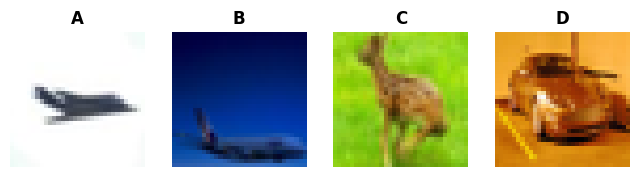

In [28]:
X_13, _ = wb.datasets.load_cifar10("test")          # 10 000 photos 32 x 32, uint8 (N, H, W, C)
PHOTOS_13 = X_13[[1078, 9590, 1303, 4285]].astype(np.float64) / 255     # the photos A, B, C, D, values in [0, 1]
fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for ax, photo, name in zip(axes, PHOTOS_13, "ABCD"):
    ax.imshow(photo)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [29]:
weight_13 = np.array([1.0, 1.0, -1.0]).reshape(1, 3, 1, 1)    # 1 output channel, 3 input channels, 1 x 1
highest_13, negative_13, peak_13 = "C", True, "D"
if not filled(weight_13):
    print("⏳ Ex 21.13 : écris weight_13.")
else:
    w_13 = as_numpy(weight_13)
    verdict("21.13", w_13 is not None and w_13.shape == (1, 3, 1, 1) and np.array_equal(w_13.ravel(), [1, 1, -1]),
            "weight_13 : le neurone R + G - B, au format (C_out, C_in, 1, 1) d'une convolution 1 x 1.",
            "weight_13 : attendu les poids (+1, +1, -1) de R, G et B, rangés en (C_out, C_in, k_h, k_w) = (1, 3, 1, 1) ; reçu "
            + ("rien de lisible" if w_13 is None else f"la forme {w_13.shape} et les valeurs {w_13.ravel().tolist()}") + ".")

✅ Ex 21.13 : weight_13 : le neurone R + G - B, au format (C_out, C_in, 1, 1) d'une convolution 1 x 1.


In [30]:
wb.record("21.13a", "C", mistakes={"la voiture paraît la plus jaune, mais calcule R + G - B pour l'herbe : beaucoup de vert, peu de bleu": "D",
          "le blanc a aussi du bleu, que le neurone retire : son score est-il le plus haut ?": "A", "un ciel bleu : beaucoup de B, retranché": "B"})
wb.record("21.13b", True, mistakes={"un ciel bleu : B grand, R et G petits ; quel signe pour R + G - B ?": False})
wb.record("21.13c", "D", mistakes={"quelle couleur donne le plus grand score R + G - B (✏️ 21.1) ? Quelle photo en a des pixels ?": "C",
          "le bleu du blanc est retranché : un pixel blanc peut-il faire le pic ?": "A", "le ciel bleu reste bas partout": "B"})

WB_ANSWER {"hash": "13a4d678938a68e1d820f02232cc39e8d02d99b260f07de3b5a19768ad642e9c", "id": "21.13a", "kind": "str", "mistakes": {"6527c80b782746c96f6638be64b292a587ae009d9e98a82e7c7872c2b34c225f": "la voiture paraît la plus jaune, mais calcule R + G - B pour l'herbe : beaucoup de vert, peu de bleu", "c322aef3ce202dd0104a4d75fc2eca04f0f38768eaae4711b0a3f0fce2bc0aa8": "le blanc a aussi du bleu, que le neurone retire : son score est-il le plus haut ?", "f2dc848078905fe8820dfb848aaf84ccbbc1d1513dd7cc6b31c9e652cc8ab677": "un ciel bleu : beaucoup de B, retranché"}}
📝 Ex 21.13a : réponse enregistrée (str).
WB_ANSWER {"hash": "59b02076c6004443be02a52021d28356a446909c702be52f5d327a20839a2211", "id": "21.13b", "kind": "bool", "mistakes": {"eb654a96356e83f82792e60819e29d3d5b3d4bf85f1b0d77d61529b46e86dd34": "un ciel bleu : B grand, R et G petits ; quel signe pour R + G - B ?"}}
📝 Ex 21.13b : réponse enregistrée (bool).
WB_ANSWER {"hash": "b61e1330826d62e2783a9853a8dfa86f20f0cc384005e638d31811f03

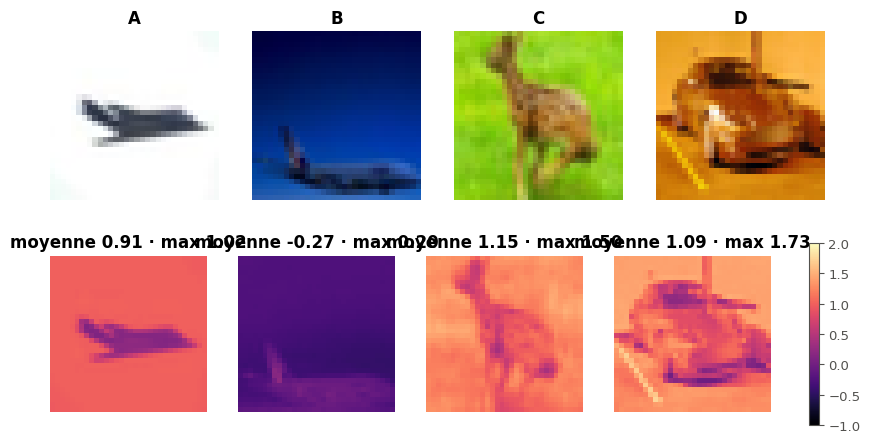

✅ Ex 21.13a : Bien joué !
✅ Ex 21.13b : C'est ça !
✅ Ex 21.13c : Parfait !


In [31]:
if any(answer is ... or answer is None for answer in [highest_13, negative_13, peak_13]):
    print("⏳ Ex 21.13 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    x_13 = torch.tensor(PHOTOS_13).permute(0, 3, 1, 2)                  # (4, 32, 32, 3) -> (4, 3, 32, 32), NCHW
    yellow_13 = torch.tensor([1.0, 1.0, -1.0], dtype=torch.float64).reshape(1, 3, 1, 1)
    scores_13 = F.conv2d(x_13, yellow_13)[:, 0]                       # (4, 32, 32): one score per pixel
    fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
    for k, name in enumerate("ABCD"):
        axes[0, k].imshow(PHOTOS_13[k])
        axes[0, k].set_title(name)
        shown = axes[1, k].imshow(scores_13[k], cmap="magma", vmin=-1, vmax=2)
        axes[1, k].set_title(f"moyenne {scores_13[k].mean():.2f} · max {scores_13[k].max():.2f}")
    for ax in axes.ravel():
        ax.axis("off")
    fig.colorbar(shown, ax=axes[1].tolist(), fraction=0.02)
    plt.show()
    wb.check("21.13a", highest_13)
    wb.check("21.13b", negative_13)
    wb.check("21.13c", peak_13)

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé, la couleur que tu voyais ou la formule du score ?

💡 Le score $R + G - B$ ne mesure pas « jaune » mais « beaucoup de rouge et de vert, peu de bleu ». L'herbe, très verte et peu bleue, monte haut ; le blanc vaut $1 + 1 - 1 = 1$ ; le ciel bleu passe sous 0. Pour un vrai détecteur de jaune, il faudrait aussi exiger que $R$ et $G$ soient **proches** l'un de l'autre, ce qu'un neurone linéaire seul ne sait pas faire : il faut une non-linéarité et une seconde couche (✏️ 21.1, « dans ta copie »).

### Ex 21.14 — im2col : la vue « œil de mouche » 🔨 ★★ ⏱️ 30 min
**Objectif :** ranger chaque morceau de l'image dans une colonne, pour faire d'une convolution un seul produit matriciel.  
**Prérequis :** Ex 21.12 · fiche §21.3.2 · **mylearn :** `conv.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `im2col(x, kernel_size, stride=1, padding=0, dilation=1)`. **Contrat** :
- `x` a la forme `(N, C, H, W)` ; le résultat a la forme `(N, C·k_h·k_w, L)`, avec $L = H_{out} \times W_{out}$ (les tailles de `conv_output_size`, sur chaque axe) : c'est la disposition de `torch.nn.functional.unfold` ;
- la colonne `l` contient le morceau de la position de sortie `(l // W_out, l % W_out)` (ligne par ligne) ; dans une colonne, la valeur du canal `c`, de la ligne `i` et de la colonne `j` du noyau est à l'indice `c·k_h·k_w + i·k_w + j`, l'ordre de `weight.reshape(C_out, -1)` : ainsi `weight.reshape(C_out, -1) @ im2col(x, k)` calcule la convolution ;
- le padding est fait de zéros ; avec une dilatation $d$, le noyau lit un pixel tous les $d$.

La première cellule compare trois cas à `F.unfold`, puis vérifie que le produit matriciel redonne `F.conv2d` ; la seconde lance les tests (`-k "test_im2col_"`).

In [32]:
with checked("21.14"):
    C = mylearn.conv
    x_14 = np.arange(2 * 3 * 5 * 6, dtype=float).reshape(2, 3, 5, 6)
    for kw_14 in [dict(kernel_size=3), dict(kernel_size=(2, 3), stride=2, padding=1), dict(kernel_size=2, dilation=(2, 1))]:
        want_14 = F.unfold(torch.tensor(x_14), **kw_14)
        cols_14 = C.im2col(x_14, **kw_14)
        if not returned("21.14", "im2col", cols_14):
            break
        same("21.14", f"im2col(x, {', '.join(f'{k}={v}' for k, v in kw_14.items())}) contre F.unfold", cols_14, want_14)
    w_14 = np.random.default_rng(14).normal(size=(4, 3, 3, 3))
    conv_14 = np.asarray(w_14.reshape(4, -1) @ C.im2col(x_14, 3)).reshape(2, 4, 3, 4)
    same("21.14", "w.reshape(C_out, -1) @ im2col(x, 3), remis en (N, C_out, H_out, W_out), contre F.conv2d", conv_14,
         F.conv2d(torch.tensor(x_14), torch.tensor(w_14)))
    refuses("21.14", "im2col avec un noyau plus grand que l'image", lambda: C.im2col(np.ones((1, 1, 3, 3)), 4))

✅ Ex 21.14 : im2col(x, kernel_size=3) contre F.unfold : un tableau (2, 27, 12), comme attendu.
✅ Ex 21.14 : im2col(x, kernel_size=(2, 3), stride=2, padding=1) contre F.unfold : un tableau (2, 18, 9), comme attendu.
✅ Ex 21.14 : im2col(x, kernel_size=2, dilation=(2, 1)) contre F.unfold : un tableau (2, 12, 15), comme attendu.
✅ Ex 21.14 : w.reshape(C_out, -1) @ im2col(x, 3), remis en (N, C_out, H_out, W_out), contre F.conv2d : un tableau (2, 4, 3, 4), comme attendu.
✅ Ex 21.14 : im2col avec un noyau plus grand que l'image : ValueError levée (the window (span 4) does not fit in the padded input (size 3 + 2 * 0)).


In [33]:
if written(lambda: mylearn.conv.im2col(np.ones((1, 1, 2, 2)), 1)):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_im2col_")
else:
    print("⏳ Ex 21.14 : les tests attendent ta fonction.")

pytest: 24 passed, 186 deselected in 0.87s


### Ex 21.15 — conv2d : stride, padding, dilatation et groupes 🔨 ★★★ ⏱️ 90 min
**Objectif :** écrire la couche de convolution de PyTorch en NumPy, avec tous ses réglages.  
**Prérequis :** Ex 21.14 · ✏️ 21.2 · fiche §21.3, §21.4, §21.4.1 · **mylearn :** `conv.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `conv2d(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1)`, la corrélation croisée de `F.conv2d`. **Contrat** :
- `x` a la forme `(N, C_in, H, W)`, `weight` la forme `(C_out, C_in/groups, k_h, k_w)`, `bias` la forme `(C_out,)` ou vaut `None` ; le résultat a la forme `(N, C_out, H_out, W_out)` ; le noyau n'est **pas** retourné ;
- `groups = g` coupe les canaux d'entrée et de sortie en $g$ groupes consécutifs : le groupe $j$ de sortie ne lit que le groupe $j$ d'entrée (`groups = C_in` : une convolution par canal) ;
- `padding` est un entier, un couple, `"valid"` (pas de padding) ou `"same"` (une sortie de la taille de l'entrée, avec un stride de 1 seulement) ; avec `"same"`, la bordure totale vaut $d(k - 1)$ sur chaque axe, et quand elle est impaire, la ligne et la colonne en trop vont **en bas et à droite**, comme dans PyTorch ;
- elle lève `ValueError` pour : `groups` < 1, ou qui ne divise pas `C_in` ou `C_out` ; un poids qui n'a pas quatre axes, ou dont `shape[1]` n'est pas `C_in/groups` ; un biais d'une autre forme que `(C_out,)`, même diffusable (`(1,)`) ; une autre chaîne que `"same"` et `"valid"` ; `"same"` avec un stride > 1 sur l'un des deux axes.

La première cellule compare six cas à `F.conv2d` (noyau rectangulaire, stride et padding par axe, dilatation, groupes, convolution par canal, `"same"` avec un noyau pair) et essaie quatre refus ; la seconde lance les tests (`-k "test_conv2d_ and not test_conv2d_backward_"`).

In [34]:
import warnings

with checked("21.15"):
    C = mylearn.conv
    rng_15 = np.random.default_rng(15)
    x_15 = rng_15.normal(size=(2, 4, 7, 6))
    cases_15 = [("noyau 3 × 2 asymétrique, biais", (5, 4, 3, 2), dict(), True),
                ("stride (2, 1) et padding (1, 2)", (3, 4, 3, 3), dict(stride=(2, 1), padding=(1, 2)), False),
                ("dilatation 2", (3, 4, 3, 3), dict(dilation=2), True),
                ("groups=2", (6, 2, 3, 3), dict(groups=2, padding=1), True),
                ("convolution par canal (groups=4)", (4, 1, 3, 3), dict(groups=4), False),
                ('padding="same", noyau pair 2 × 4', (3, 4, 2, 4), dict(padding="same"), True)]
    for label_15, shape_15, kw_15, bias_15 in cases_15:
        w_15 = rng_15.normal(size=shape_15)
        b_15 = rng_15.normal(size=shape_15[0]) if bias_15 else None
        args_15 = (x_15.copy(), w_15.copy(), None if b_15 is None else b_15.copy())   # copies: the expected values use x_15
        out_15 = C.conv2d(*args_15, **kw_15)
        if not returned("21.15", "conv2d", out_15):
            break
        if not (np.array_equal(args_15[0], x_15) and np.array_equal(args_15[1], w_15)
                and (b_15 is None or np.array_equal(args_15[2], b_15))):
            verdict("21.15", False, "conv2d laisse ses entrées intactes.",
                    "conv2d a modifié x, weight ou bias : ne modifie pas ses entrées, écris dans un nouveau tableau.")
            break
        with warnings.catch_warnings():               # PyTorch warns that an even kernel with "same" copies the input
            warnings.simplefilter("ignore", UserWarning)
            want_15 = F.conv2d(torch.tensor(x_15), torch.tensor(w_15), None if b_15 is None else torch.tensor(b_15), **kw_15)
        same("21.15", f"conv2d, {label_15}, contre F.conv2d", out_15, want_15)
    refuses("21.15", "un poids dont shape[1] n'est pas C_in / groups", lambda: C.conv2d(x_15, np.ones((2, 3, 3, 3))))
    refuses("21.15", "un biais de forme (1,) pour 2 filtres", lambda: C.conv2d(x_15, np.ones((2, 4, 3, 3)), np.ones(1)))
    refuses("21.15", 'padding="same" avec un stride de 2', lambda: C.conv2d(x_15, np.ones((2, 4, 3, 3)), padding="same", stride=2))
    refuses("21.15", "groups=3 avec 4 canaux d'entrée", lambda: C.conv2d(x_15, np.ones((3, 1, 3, 3)), groups=3))

✅ Ex 21.15 : conv2d, noyau 3 × 2 asymétrique, biais, contre F.conv2d : un tableau (2, 5, 5, 5), comme attendu.
✅ Ex 21.15 : conv2d, stride (2, 1) et padding (1, 2), contre F.conv2d : un tableau (2, 3, 4, 8), comme attendu.
✅ Ex 21.15 : conv2d, dilatation 2, contre F.conv2d : un tableau (2, 3, 3, 2), comme attendu.
✅ Ex 21.15 : conv2d, groups=2, contre F.conv2d : un tableau (2, 6, 7, 6), comme attendu.
✅ Ex 21.15 : conv2d, convolution par canal (groups=4), contre F.conv2d : un tableau (2, 4, 5, 4), comme attendu.
✅ Ex 21.15 : conv2d, padding="same", noyau pair 2 × 4, contre F.conv2d : un tableau (2, 3, 7, 6), comme attendu.
✅ Ex 21.15 : un poids dont shape[1] n'est pas C_in / groups : ValueError levée (weight of shape (2, 3, 3, 3) expects 3 input channels (groups=1), got x with C_in=4).
✅ Ex 21.15 : un biais de forme (1,) pour 2 filtres : ValueError levée (bias must have shape (2,), got (1,)).
✅ Ex 21.15 : padding="same" avec un stride de 2 : ValueError levée (padding="same" needs strid

In [35]:
if written(lambda: mylearn.conv.conv2d(np.ones((1, 1, 2, 2)), np.ones((1, 1, 1, 1)))):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_conv2d_ and not test_conv2d_backward_")
else:
    print("⏳ Ex 21.15 : les tests attendent ta fonction.")

pytest: 47 passed, 163 deselected in 1.03s


### Ex 21.16 — Tests pytest paramétrés pour conv2d 🛠️ ★★ ⏱️ 20 min
**Objectif :** écrire des tests paramétrés qui acceptent une convolution juste et attrapent cinq versions fausses.  
**Prérequis :** Ex 21.15 · 0A (pytest, `parametrize`) · fiche §21.3.4, §21.3.5 · **Parcours :** C

Une convolution a beaucoup de réglages, et ses bugs se cachent dans les cas qu'on n'essaie pas : un stride qui ne tombe pas juste, un padding asymétrique, un biais oublié. La cellule ci-dessous définit `conv_ok(x, weight, bias=None, stride=1, padding=0)`, une convolution juste (elle appelle PyTorch), et cinq versions fausses, `conv_bug_1` à `conv_bug_5` (lis leurs docstrings). Écris des fonctions de test pytest (des fonctions `test_...` qui utilisent `assert`) pour une fonction `conv` de ce contrat, et mets-les dans la liste `my_tests_16`. Règles :
- au moins un test **paramétré** (`@pytest.mark.parametrize`), qui essaie plusieurs strides, paddings et tailles ;
- l'oracle est `F.conv2d` de PyTorch (le fichier de test importe `torch` et `torch.nn.functional as F`, en plus de `math`, `numpy as np` et `pytest`) ;
- tes tests doivent **tous passer** sur `conv_ok`, et **au moins un** doit échouer sur chacune des cinq versions fausses.

La vérification lance vraiment pytest : sur `conv_ok`, puis sur chaque version fausse, renommée `conv`.

Dans tes notes : lequel des cinq bugs a été le plus difficile à attraper, et quel cas a fini par le faire échouer ? Pourquoi un test sur une seule taille d'image (par exemple 6 × 6 avec un stride de 2) ne suffit-il pas ?

In [36]:
def conv_ok(x, weight, bias=None, stride=1, padding=0):
    """A correct conv2d (cross-correlation, groups=1), computed by PyTorch: the version your tests must accept."""
    out = F.conv2d(torch.as_tensor(np.asarray(x, dtype=float)), torch.as_tensor(np.asarray(weight, dtype=float)),
                   None if bias is None else torch.as_tensor(np.asarray(bias, dtype=float)), stride=stride, padding=padding)
    return out.numpy()


def conv_bug_1(x, weight, bias=None, stride=1, padding=0):
    """Bug: the kernel is flipped (a mathematician's convolution)."""
    w = torch.flip(torch.as_tensor(np.asarray(weight, dtype=float)), dims=(2, 3))
    out = F.conv2d(torch.as_tensor(np.asarray(x, dtype=float)), w,
                   None if bias is None else torch.as_tensor(np.asarray(bias, dtype=float)), stride=stride, padding=padding)
    return out.numpy()


def conv_bug_2(x, weight, bias=None, stride=1, padding=0):
    """Bug: the bias is ignored."""
    out = F.conv2d(torch.as_tensor(np.asarray(x, dtype=float)), torch.as_tensor(np.asarray(weight, dtype=float)),
                   stride=stride, padding=padding)
    return out.numpy()


def conv_bug_3(x, weight, bias=None, stride=1, padding=0):
    """Bug: the stride is applied to the rows only."""
    out = F.conv2d(torch.as_tensor(np.asarray(x, dtype=float)), torch.as_tensor(np.asarray(weight, dtype=float)),
                   None if bias is None else torch.as_tensor(np.asarray(bias, dtype=float)), stride=(stride, 1),
                   padding=padding)
    return out.numpy()


def conv_bug_4(x, weight, bias=None, stride=1, padding=0):
    """Bug: the padding is added at the top and on the left only."""
    xt = F.pad(torch.as_tensor(np.asarray(x, dtype=float)), (padding, 0, padding, 0))
    out = F.conv2d(xt, torch.as_tensor(np.asarray(weight, dtype=float)),
                   None if bias is None else torch.as_tensor(np.asarray(bias, dtype=float)), stride=stride)
    return out.numpy()


def conv_bug_5(x, weight, bias=None, stride=1, padding=0):
    """Bug: the last row is lost when the stride does not divide the input exactly."""
    out = conv_ok(x, weight, bias, stride, padding)
    h = np.asarray(x).shape[2] + 2 * padding - np.asarray(weight).shape[2]
    return out[:, :, :-1] if h % stride else out


BUGS_16 = [conv_bug_1, conv_bug_2, conv_bug_3, conv_bug_4, conv_bug_5]
PREAMBLE_16 = "import torch\nimport torch.nn.functional as F"     # the imports the test file needs
print("conv_ok and 5 buggy versions ready")

conv_ok and 5 buggy versions ready


In [37]:
import pytest


@pytest.mark.parametrize("stride", [1, 2, 3])
@pytest.mark.parametrize("padding", [0, 1, 2])
@pytest.mark.parametrize("size", [(7, 7), (8, 5)])
def test_conv_matches_torch(stride, padding, size):
    rng = np.random.default_rng(stride * 100 + padding * 10 + size[1])
    x = rng.normal(size=(2, 3, *size))
    w = rng.normal(size=(4, 3, 3, 2))                      # an asymmetric, rectangular kernel
    b = rng.normal(size=4)
    want = F.conv2d(torch.tensor(x), torch.tensor(w), torch.tensor(b), stride=stride, padding=padding).numpy()
    got = np.asarray(conv(x, w, b, stride=stride, padding=padding))
    assert got.shape == want.shape
    assert np.allclose(got, want)


def test_conv_without_bias_is_the_dot_product_of_one_window():
    x = np.arange(9.0).reshape(1, 1, 3, 3)
    w = np.array([[[[1.0, 0.0], [0.0, -1.0]]]])
    assert np.allclose(conv(x, w), [[[[0 - 4, 1 - 5], [3 - 7, 4 - 8]]]])


my_tests_16 = [test_conv_matches_torch, test_conv_without_bias_is_the_dot_product_of_one_window]
def parametrized_16(tests):
    """True when at least one test function carries a pytest.mark.parametrize mark."""
    return any(mark.name == "parametrize" for t in tests for mark in getattr(t, "pytestmark", []))


if my_tests_16 is ...:
    print("⏳ Ex 21.16 : tests pas encore écrits.")
elif not isinstance(my_tests_16, (list, tuple)) or not my_tests_16 or not all(callable(t) for t in my_tests_16):
    print("❌ Ex 21.16 : my_tests_16 doit être une liste non vide de fonctions de test (leurs noms, sans parenthèses).")
else:
    good_16 = wb.run_pytest(my_tests_16, subject=conv_ok, name="conv", preamble=PREAMBLE_16)
    verdict("21.16", parametrized_16(my_tests_16), "au moins un de tes tests est paramétré.",
            "aucun de tes tests n'est paramétré : utilise @pytest.mark.parametrize pour essayer plusieurs strides et paddings.")
    verdict("21.16", good_16.ok, f"tes tests passent sur conv_ok, la version juste ({good_16.passed} cas).",
            "tes tests doivent tous passer sur conv_ok, la version juste (le détail est au-dessus).")
    if good_16.ok:
        for bug_16 in BUGS_16:
            result_16 = wb.run_pytest(my_tests_16, subject=bug_16, name="conv", preamble=PREAMBLE_16, quiet=True)
            verdict("21.16", result_16.failed + result_16.errors > 0,
                    f"{bug_16.__name__} est attrapé ({result_16.failed + result_16.errors} cas en échec).",
                    f"tes tests passent sur {bug_16.__name__}, qui est faux : lis sa docstring, puis ajoute un cas qui le fait échouer.")

pytest : 19 passed in 1.06s
✅ Ex 21.16 : au moins un de tes tests est paramétré.
✅ Ex 21.16 : tes tests passent sur conv_ok, la version juste (19 cas).


✅ Ex 21.16 : conv_bug_1 est attrapé (19 cas en échec).


✅ Ex 21.16 : conv_bug_2 est attrapé (18 cas en échec).


✅ Ex 21.16 : conv_bug_3 est attrapé (12 cas en échec).


✅ Ex 21.16 : conv_bug_4 est attrapé (10 cas en échec).


✅ Ex 21.16 : conv_bug_5 est attrapé (19 cas en échec).


💡 `conv_bug_5` ne se trompe que quand le stride ne divise pas $H + 2p - k$ : un test sur une taille où il divise (6 avec un noyau 2 et un stride de 2) le laisse passer. `conv_bug_3` passe tout test où le stride vaut 1, `conv_bug_1` tout test à noyau symétrique, `conv_bug_2` tout test sans biais et `conv_bug_4` tout test sans padding : paramétrer sur plusieurs valeurs de chaque réglage, avec un noyau asymétrique et un biais, les attrape tous.

### Ex 21.17 — Reproduire la chasse aux rayures verticales (Fig. 21.14) 🎨 ★★ ⏱️ 20 min
**Objectif :** promener un filtre sur une image bruitée avec ta convolution, puis lire et afficher où il trouve son motif.  
**Prérequis :** Ex 21.15 · fiche §21.3.1 · **Fil rouge :** synthétique · **Parcours :** C

La figure 21.14 du livre promène un filtre 3 × 3 sur une image bruitée en noir (0) et blanc (1) : $+1$ sur sa colonne du milieu, $-1$ ailleurs, il cherche une courte rayure verticale blanche entourée de noir. On refait l'expérience sur l'image `IMG_17` (24 × 24 pixels, tirée au hasard) avec le filtre `K_17`.
- `scores_17` : les scores de `K_17` en chaque position de `IMG_17`, calculés avec **ta** fonction `mylearn.conv.conv2d`, sans padding (pense au format `(N, C, H, W)` : `IMG_17[None, None]`) ;
- a) `perfect_17` : le nombre de positions de score parfait (le motif exact) ;
- b) `worst_17` : le nombre de positions qui ont le score le plus bas possible de ce filtre ;
- c) `twos_17` : le nombre de positions de score 2 ;
- `show_17(img, kernel, scores)` : la figure en cinq panneaux (a) à (e), comme celle du livre : le filtre, l'image, les scores (avec une barre de couleurs), les positions de score parfait, et l'image avec un cadre autour de chaque correspondance (`plt.Rectangle`) ; finis par `plt.show()`.

Dans tes notes : deux correspondances sont voisines, l'une juste sous l'autre ; regarde l'image : quel motif les produit ? Que vaudrait le score d'une position où une rayure parfaite a **un** pixel noir de trop, en haut ?

In [38]:
IMG_17 = (np.random.default_rng(2169).random((24, 24)) < 0.4).astype(float)    # a noisy binary image: 1 white, 0 black
K_17 = -np.ones((3, 3))
K_17[:, 1] = 1.0                       # the filter: a short vertical white stripe (+1) surrounded by black (-1)
print(K_17)

[[-1.  1. -1.]
 [-1.  1. -1.]
 [-1.  1. -1.]]


✅ Ex 21.17 : scores_17 a la forme (22, 22).
✅ Ex 21.17a : Exact !
✅ Ex 21.17b : Bien joué !
✅ Ex 21.17c : C'est ça !


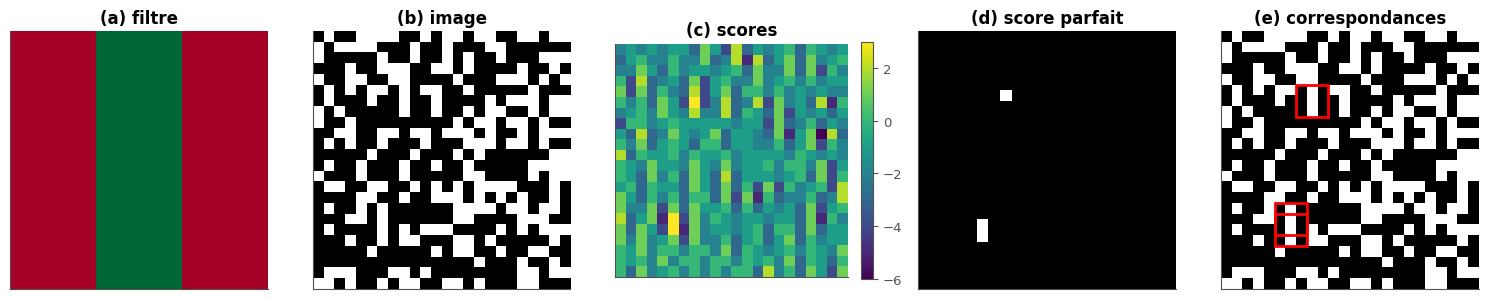

In [39]:
scores_17 = mylearn.conv.conv2d(IMG_17[None, None], K_17[None, None])[0, 0]
best_17 = K_17[K_17 > 0].sum()                    # 3: every +1 on white, every -1 on black
perfect_17 = int(np.sum(scores_17 == best_17))
worst_17 = int(np.sum(scores_17 == -(K_17 < 0).sum()))   # -6: every -1 on white, every +1 on black
twos_17 = int(np.sum(scores_17 == 2))


def show_17(img, kernel, scores):
    """Reproduce figure 21.14 in five panels: the filter, the image, the scores, the perfect matches, the image
    with a box around each match (plt.Rectangle). End with plt.show()."""
    best = kernel[kernel > 0].sum()
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
    axes[0].imshow(kernel, cmap="RdYlGn", vmin=-1, vmax=1)
    axes[0].set_title("(a) filtre")
    axes[1].imshow(img, cmap="gray")
    axes[1].set_title("(b) image")
    shown = axes[2].imshow(scores, cmap="viridis")
    fig.colorbar(shown, ax=axes[2], fraction=0.046)
    axes[2].set_title("(c) scores")
    axes[3].imshow(scores == best, cmap="gray")
    axes[3].set_title("(d) score parfait")
    axes[4].imshow(img, cmap="gray")
    for i, j in np.argwhere(scores == best):          # the window of output (i, j) starts at pixel (i, j)
        axes[4].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 3, 3, fill=False, edgecolor="red", linewidth=2))
    axes[4].set_title("(e) correspondances")
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.show()
with checked("21.17"):
    if filled(scores_17):
        arr_17 = as_numpy(scores_17)
        verdict("21.17", arr_17 is not None and arr_17.shape == (22, 22), "scores_17 a la forme (22, 22).",
                f"scores_17 : attendu un tableau (22, 22), une corrélation sans padding (24 - 3 + 1) ; reçu "
                f"{None if arr_17 is None else arr_17.shape}.")
    wb.check("21.17a", perfect_17)
    wb.check("21.17b", worst_17)
    wb.check("21.17c", twos_17)
    if filled(scores_17):
        show_17(IMG_17, K_17, np.asarray(scores_17))

In [40]:
wb.record("21.17a", perfect_17, mistakes={"un score parfait vaut exactement la somme des +1 du filtre : compte les positions où il est atteint, pas celles qui en approchent": int(np.sum(scores_17 >= 2))})
wb.record("21.17b", worst_17, mistakes={"le score le plus bas possible : chaque -1 sur du blanc ET chaque +1 sur du noir ; quelle valeur cela donne-t-il ?": int(np.sum(scores_17 == scores_17.min() + 1))})
wb.record("21.17c", twos_17, mistakes={"compte les positions de score exactement 2, pas au moins 2": int(np.sum(scores_17 >= 2))})

WB_ANSWER {"hash": "775586a847127f4fb233499d650782b5aa260ecab0352a83613b16319b571ab1", "id": "21.17a", "kind": "int", "magnitude": 0, "mistakes": {"a6a6bfd6f4c509842c06ae332894b5534bdfdce3f1c90eff5f9613855e0ac365": "un score parfait vaut exactement la somme des +1 du filtre : compte les positions où il est atteint, pas celles qui en approchent"}, "sign": 1}
📝 Ex 21.17a : réponse enregistrée (int).
WB_ANSWER {"hash": "68970443bf7dafc65f8100a18df6407556da36c5bd5f2b3a279bf0ed3114063a", "id": "21.17b", "kind": "int", "magnitude": 0, "mistakes": {"733a58afd564b61445a09133498d953956faaf98266e50a2a087690e79e1d3e9": "le score le plus bas possible : chaque -1 sur du blanc ET chaque +1 sur du noir ; quelle valeur cela donne-t-il ?"}, "sign": 1}
📝 Ex 21.17b : réponse enregistrée (int).
WB_ANSWER {"hash": "775337b2e44170f27e15d15128a7119cfee2008677e5c01f1d1fdb7508066e4d", "id": "21.17c", "kind": "int", "magnitude": 1, "mistakes": {"52bb6c9069f471bd2055066a36b40be925d261dc3d7d5d4e77ed29e92eb1597b":

💡 Les deux correspondances voisines viennent d'une rayure de **quatre** pixels : le filtre ne contraint que ses trois lignes, si bien qu'une rayure plus longue répond à deux positions successives. Une rayure parfaite dont un pixel de la colonne du milieu est noir perd 1 (le $+1$ n'est plus sur du blanc) : 2. C'est pourquoi un score de 2 signale un motif presque complet.

### Ex 21.18 — max_pool2d et avg_pool2d 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire le max pooling et le pooling moyen aux conventions de PyTorch, padding compris.  
**Prérequis :** Ex 21.14 · fiche §21.3.3 (max pooling), §21.9 (encadré « le pooling dans PyTorch ») · **mylearn :** `conv.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `max_pool2d(x, kernel_size, stride=None, padding=0)` et `avg_pool2d(x, kernel_size, stride=None, padding=0)`. **Contrat** :
- `x` a la forme `(N, C, H, W)` ; chaque canal est réduit seul ; la sortie a la forme `(N, C, H_out, W_out)` (les tailles de `conv_output_size`) ; `stride=None` veut dire `stride = kernel_size` (des blocs disjoints) ;
- le padding vaut au plus `kernel_size // 2` sur chaque axe (règle de PyTorch ; au-delà, `ValueError`) ; pour le max, les cases de padding valent $-\infty$ : elles ne sont jamais le maximum ; pour la moyenne, ce sont des zéros, **comptés** dans la moyenne (`count_include_pad=True`, le défaut de PyTorch : chaque fenêtre est divisée par $k_h k_w$) ;
- quand plusieurs cases d'une fenêtre ont la même valeur maximale, seule la valeur compte.

La première cellule compare quatre réglages à `F.max_pool2d` et `F.avg_pool2d`, essaie des valeurs toutes négatives avec padding et un padding trop grand ; la seconde lance les tests (`-k "test_max_pool2d_ or test_avg_pool2d_"`).

In [41]:
with checked("21.18"):
    C = mylearn.conv
    x_18 = np.random.default_rng(18).normal(size=(2, 3, 7, 8))
    for kw_18 in [dict(kernel_size=2), dict(kernel_size=3, stride=2), dict(kernel_size=(3, 2), stride=(1, 2), padding=(1, 1)),
                  dict(kernel_size=3, stride=1, padding=1)]:
        text_18 = ", ".join(f"{k}={v}" for k, v in kw_18.items())
        out_max_18 = C.max_pool2d(x_18, **kw_18)
        if not returned("21.18", "max_pool2d", out_max_18):
            break
        same("21.18", f"max_pool2d({text_18}) contre F.max_pool2d", out_max_18, F.max_pool2d(torch.tensor(x_18), **kw_18))
        out_avg_18 = C.avg_pool2d(x_18, **kw_18)
        if not returned("21.18", "avg_pool2d", out_avg_18):
            break
        same("21.18", f"avg_pool2d({text_18}) contre F.avg_pool2d", out_avg_18, F.avg_pool2d(torch.tensor(x_18), **kw_18))
    neg_18 = -np.ones((1, 1, 2, 2))
    same("21.18", "max_pool2d de valeurs toutes négatives, padding 1 (le padding ne gagne jamais)",
         C.max_pool2d(neg_18, 2, stride=1, padding=1), -np.ones((1, 1, 3, 3)))
    refuses("21.18", "max_pool2d avec un padding de 2 pour une fenêtre de 3", lambda: C.max_pool2d(x_18, 3, padding=2))

✅ Ex 21.18 : max_pool2d(kernel_size=2) contre F.max_pool2d : un tableau (2, 3, 3, 4), comme attendu.
✅ Ex 21.18 : avg_pool2d(kernel_size=2) contre F.avg_pool2d : un tableau (2, 3, 3, 4), comme attendu.
✅ Ex 21.18 : max_pool2d(kernel_size=3, stride=2) contre F.max_pool2d : un tableau (2, 3, 3, 3), comme attendu.
✅ Ex 21.18 : avg_pool2d(kernel_size=3, stride=2) contre F.avg_pool2d : un tableau (2, 3, 3, 3), comme attendu.
✅ Ex 21.18 : max_pool2d(kernel_size=(3, 2), stride=(1, 2), padding=(1, 1)) contre F.max_pool2d : un tableau (2, 3, 7, 5), comme attendu.


✅ Ex 21.18 : avg_pool2d(kernel_size=(3, 2), stride=(1, 2), padding=(1, 1)) contre F.avg_pool2d : un tableau (2, 3, 7, 5), comme attendu.
✅ Ex 21.18 : max_pool2d(kernel_size=3, stride=1, padding=1) contre F.max_pool2d : un tableau (2, 3, 7, 8), comme attendu.
✅ Ex 21.18 : avg_pool2d(kernel_size=3, stride=1, padding=1) contre F.avg_pool2d : un tableau (2, 3, 7, 8), comme attendu.
✅ Ex 21.18 : max_pool2d de valeurs toutes négatives, padding 1 (le padding ne gagne jamais) : un tableau (1, 1, 3, 3), comme attendu.
✅ Ex 21.18 : max_pool2d avec un padding de 2 pour une fenêtre de 3 : ValueError levée (padding (2, 2) must be at most half the kernel size (3, 3) (kernel_size // 2)).


In [42]:
if written(lambda: mylearn.conv.max_pool2d(np.ones((1, 1, 2, 2)), 2)):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_max_pool2d_ or test_avg_pool2d_")
else:
    print("⏳ Ex 21.18 : les tests attendent tes fonctions.")

pytest: 47 passed, 163 deselected in 1.00s


## Partie B · Des filtres faits main, les convolutions 1D et 1 × 1, et un détecteur de visage

Tu utilises maintenant les convolutions de PyTorch (`F.conv2d`, `nn.Conv1d`, `nn.Conv2d`) avec des filtres que tu choisis : flou, Sobel et netteté sur une photo (21.19), des convolutions 1D, pleine largeur et 1 × 1 (21.20) ; puis tu construis avec **ta** librairie le détecteur de visage hiérarchique du livre (21.21).

### Ex 21.19 — Flou, Sobel, netteté : des filtres faits main avec F.conv2d 📦 ★★ ⏱️ 20 min
**Objectif :** écrire trois filtres classiques du traitement d'image comme des poids de convolution, au bon format.  
**Prérequis :** ch. 20 (tenseurs) · Ex 21.15 · fiche §21.3.1, §21.4, §21.4.1 · **Fil rouge :** CIFAR-10 · **Parcours :** C

Trois filtres que les logiciels d'images appliquent depuis longtemps, écrits comme des couches de convolution. Les images sont des tenseurs `float64` de forme `(N, 3, H, W)`, de valeurs dans $[0, 1]$.

**Contrat**
- `blur_19(x)` : un flou « boîte » 3 × 3 de **chaque** canal (la moyenne des 9 pixels de la fenêtre), en **un** appel à `F.conv2d` avec `groups=3` ; il rend un tenseur de la forme de `x` ;
- `sobel_19(x)` : le gradient horizontal de la **luminance** $0{,}299\,R + 0{,}587\,G + 0{,}114\,B$ (`LUMA_19`) par le noyau de Sobel $\begin{pmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{pmatrix}$, positif là où l'image s'éclaire vers la droite, en **un** appel à `F.conv2d` avec un poids de forme `(1, 3, 3, 3)` ; il rend `(N, 1, H, W)` ;
- `sharpen_19(x)` : chaque canal passé par le noyau $\begin{pmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{pmatrix}$ (`groups=3`), puis ramené dans $[0, 1]$ ; il rend la forme de `x` ;
- les trois gardent la taille de l'image en la complétant par **réplication** des bords (`F.pad(x, (1, 1, 1, 1), mode="replicate")`), pas par des zéros, et ne modifient pas `x`.

La vérification contrôle les formes, une image uniforme (inchangée par le flou et la netteté, nulle pour Sobel), un bord vertical, et compare le flou à la moyenne des fenêtres et le Sobel à deux étapes (luminance, puis Sobel) ; puis elle affiche les trois résultats.

Dans tes notes : pourquoi la luminance suivie du Sobel tient-elle en **une seule** convolution ? Que deviendraient les bords de l'image floue avec un padding de zéros ? Que vaut la somme des poids de chacun des trois noyaux, et qu'est-ce que cela dit d'une image uniforme ?

In [43]:
X_19, _ = wb.datasets.load_cifar10("test")
PHOTO_19 = torch.tensor(X_19[[8]].astype(np.float64) / 255).permute(0, 3, 1, 2)   # one photo (1, 3, 32, 32), in [0, 1]
CONST_19 = torch.full((1, 3, 6, 6), 0.4, dtype=torch.float64)                       # a uniform grey image
EDGE_19 = torch.zeros(1, 3, 6, 6, dtype=torch.float64)
EDGE_19[..., 3:] = 1.0                       # black on the left, white on the right: a vertical edge between columns 2 and 3
LUMA_19 = (0.299, 0.587, 0.114)              # the weights of R, G and B in the luminance (the grey of a colour)
print("PHOTO_19", tuple(PHOTO_19.shape), "· CONST_19", tuple(CONST_19.shape), "· EDGE_19", tuple(EDGE_19.shape))

PHOTO_19 (1, 3, 32, 32) · CONST_19 (1, 3, 6, 6) · EDGE_19 (1, 3, 6, 6)


✅ Ex 21.19 : blur_19 d'une image uniforme (les bords ne noircissent pas) : un tableau (1, 3, 6, 6), comme attendu.
✅ Ex 21.19 : blur_19 contre la moyenne de chaque fenêtre 3 x 3 (F.avg_pool2d) : un tableau (1, 3, 32, 32), comme attendu.
✅ Ex 21.19 : sobel_19 d'une image uniforme : un tableau (1, 1, 6, 6), comme attendu.
✅ Ex 21.19 : sobel_19 du bord vertical (4 de part et d'autre du bord, 0 ailleurs) : un tableau (1, 1, 6, 6), comme attendu.
✅ Ex 21.19 : sobel_19 contre deux étapes (la luminance, puis le Sobel sur une image grise) : un tableau (1, 1, 32, 32), comme attendu.
✅ Ex 21.19 : sharpen_19 d'une image uniforme : un tableau (1, 3, 6, 6), comme attendu.
✅ Ex 21.19 : sharpen_19 reste dans [0, 1].


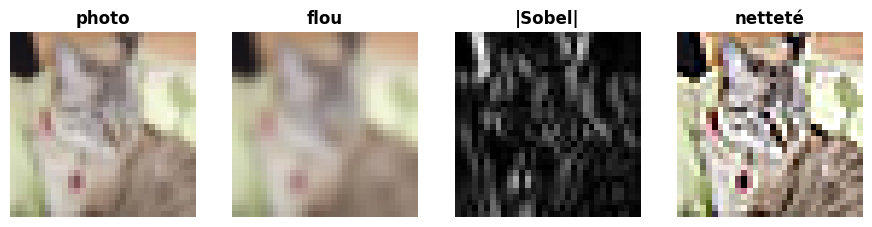

In [44]:
def blur_19(x):
    """Box blur 3 x 3 of each channel of x (N, 3, H, W), float64: one F.conv2d with groups=3, after a replicate padding."""
    weight = torch.full((3, 1, 3, 3), 1.0 / 9, dtype=x.dtype)            # (C_out, C_in / groups, 3, 3) = (3, 1, 3, 3)
    return F.conv2d(F.pad(x, (1, 1, 1, 1), mode="replicate"), weight, groups=3)


def sobel_19(x):
    """Horizontal Sobel gradient of the luminance of x (N, 3, H, W): one F.conv2d with a (1, 3, 3, 3) weight, after a
    replicate padding; returns (N, 1, H, W), positive where the image gets brighter to the right."""
    sobel = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]], dtype=x.dtype)
    weight = torch.stack([c * sobel for c in LUMA_19])[None]             # (1, 3, 3, 3): grey THEN Sobel, in one layer
    return F.conv2d(F.pad(x, (1, 1, 1, 1), mode="replicate"), weight)


def sharpen_19(x):
    """Sharpen each channel of x (N, 3, H, W) with the kernel [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] (groups=3, replicate
    padding), then clamp the result to [0, 1]."""
    kernel = torch.tensor([[0.0, -1.0, 0.0], [-1.0, 5.0, -1.0], [0.0, -1.0, 0.0]], dtype=x.dtype)
    weight = kernel.expand(3, 1, 3, 3)
    return F.conv2d(F.pad(x, (1, 1, 1, 1), mode="replicate"), weight, groups=3).clamp(0.0, 1.0)


outs_19 = {}
for name_19, fn_19, channels_19 in [("blur_19", blur_19, 3), ("sobel_19", sobel_19, 1), ("sharpen_19", sharpen_19, 3)]:
    with checked("21.19"):
        out_19 = fn_19(PHOTO_19.clone())
        if returned("21.19", name_19, out_19):
            if not isinstance(out_19, torch.Tensor) or tuple(out_19.shape) != (1, channels_19, 32, 32):
                print(f"❌ Ex 21.19 : {name_19} doit rendre un tenseur (1, {channels_19}, 32, 32) pour la photo (1, 3, 32, 32) ; "
                      f"reçu {type(out_19).__name__} de forme {tuple(np.shape(out_19))}.")
            else:
                outs_19[name_19] = out_19
if "blur_19" in outs_19:
    with checked("21.19"):
        same("21.19", "blur_19 d'une image uniforme (les bords ne noircissent pas)", blur_19(CONST_19), CONST_19)
        padded_19 = F.pad(PHOTO_19, (1, 1, 1, 1), mode="replicate")
        same("21.19", "blur_19 contre la moyenne de chaque fenêtre 3 x 3 (F.avg_pool2d)", outs_19["blur_19"],
             F.avg_pool2d(padded_19, 3, stride=1))
if "sobel_19" in outs_19:
    with checked("21.19"):
        same("21.19", "sobel_19 d'une image uniforme", sobel_19(CONST_19), torch.zeros(1, 1, 6, 6))
        same("21.19", "sobel_19 du bord vertical (4 de part et d'autre du bord, 0 ailleurs)", sobel_19(EDGE_19),
             torch.tensor([[[[0.0, 0.0, 4.0, 4.0, 0.0, 0.0]] * 6]]))
        gray_19 = sum(c * PHOTO_19[:, k:k + 1] for k, c in enumerate(LUMA_19))
        kernel_19 = torch.tensor([[[[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]]], dtype=torch.float64)
        same("21.19", "sobel_19 contre deux étapes (la luminance, puis le Sobel sur une image grise)", outs_19["sobel_19"],
             F.conv2d(F.pad(gray_19, (1, 1, 1, 1), mode="replicate"), kernel_19))
if "sharpen_19" in outs_19:
    with checked("21.19"):
        same("21.19", "sharpen_19 d'une image uniforme", sharpen_19(CONST_19), CONST_19)
        sharp_19 = outs_19["sharpen_19"]
        verdict("21.19", float(sharp_19.min()) >= 0.0 and float(sharp_19.max()) <= 1.0, "sharpen_19 reste dans [0, 1].",
                f"sharpen_19 va de {float(sharp_19.min()):.3f} à {float(sharp_19.max()):.3f} : ramène-le dans [0, 1] (clamp).")
if len(outs_19) == 3:
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    panels_19 = [(PHOTO_19, "photo"), (outs_19["blur_19"], "flou"), (outs_19["sobel_19"].abs(), "|Sobel|"),
                 (outs_19["sharpen_19"], "netteté")]
    for ax, (img_19, title_19) in zip(axes, panels_19):
        arr_19 = img_19[0].permute(1, 2, 0).numpy()
        ax.imshow(arr_19[..., 0] if arr_19.shape[-1] == 1 else arr_19, cmap="gray")
        ax.set_title(title_19)
        ax.axis("off")
    plt.show()

💡 La luminance est une combinaison linéaire des canaux, et la convolution est linéaire : appliquer le Sobel à $\sum_c a_c x_c$ revient à appliquer $a_c \times$ Sobel à chaque canal et à additionner, ce qu'une convolution à 3 canaux d'entrée fait en une fois. Avec des zéros autour, la moyenne des fenêtres du bord mélange l'image et du noir : un cadre sombre. Les sommes des poids : 1 pour le flou et la netteté (une image uniforme reste la même), 0 pour Sobel (elle donne 0) : c'est la « réponse » d'un filtre à une image sans motif.

### Ex 21.20 — Conv1d, noyau pleine largeur et 1×1 : prédire formes et paramètres 🔮 ★★ ⏱️ 15 min
**Objectif :** prédire les formes et les paramètres de convolutions 1D, pleine largeur et 1 × 1, puis le vérifier.  
**Prérequis :** Ex 21.15 · ✏️ 21.4 · fiche §21.5, §21.6 · **Parcours :** C

Trois tenseurs : `x1_20` de forme `(8, 64, 30)` (8 phrases de 30 mots, chaque mot un vecteur de 64 nombres, rangés comme `nn.Conv1d` les attend : `(N, C, L)`) ; `x2_20` de forme `(8, 1, 30, 64)` (les mêmes phrases comme des images d'un canal, 30 lignes et 64 colonnes) ; `x3_20` de forme `(8, 64, 30, 30)`. Prédis, **avant** d'exécuter quoi que ce soit (une forme entre guillemets, comme `"(1, 2)"`) :
a) `shape1_20` : la forme de `nn.Conv1d(64, 16, kernel_size=5)(x1_20)` ;
b) `params1_20` : le nombre de paramètres de cette `Conv1d` ;
c) `shape2_20` : la forme de `nn.Conv2d(1, 16, kernel_size=(5, 64))(x2_20)` (un noyau qui couvre toute la largeur) ;
d) `equal_20` : cette `Conv2d` a-t-elle exactement autant de paramètres que la `Conv1d` de a) ? (`True` ou `False`) ;
e) `params3_20` : le nombre de paramètres de `nn.Conv2d(64, 16, kernel_size=1)` ;
f) `shape3_20` : la forme de sa sortie pour `x3_20`.

L'expérience construit les trois couches, affiche leurs formes et leurs nombres de paramètres, copie les poids de la `Conv1d` dans la `Conv2d` pleine largeur pour comparer leurs sorties, et vérifie tes prédictions.

In [45]:
x1_20 = torch.zeros(8, 64, 30)      # 8 sentences of 30 words, each word a vector of 64 numbers: (N, C, L) for Conv1d
x2_20 = torch.zeros(8, 1, 30, 64)   # the same sentences as 1-channel images of 30 rows (words) and 64 columns
x3_20 = torch.zeros(8, 64, 30, 30)  # 8 feature maps of 64 channels, 30 x 30
print("x1_20", tuple(x1_20.shape), "· x2_20", tuple(x2_20.shape), "· x3_20", tuple(x3_20.shape))

x1_20 (8, 64, 30) · x2_20 (8, 1, 30, 64) · x3_20 (8, 64, 30, 30)


In [46]:
shape1_20, params1_20, shape2_20, equal_20, params3_20, shape3_20 = "(8, 16, 26)", 5136, "(8, 16, 26, 1)", True, 1040, "(8, 16, 30, 30)"

In [47]:
wb.record("21.20a", "(8, 16, 26)", mistakes={"tu as retiré tout le noyau : à sa dernière position, il tient encore dans la séquence": "(8, 16, 25)",
          "une Conv1d glisse le long de L (le dernier axe) et remplace les 64 canaux par 16 filtres": "(8, 64, 26)",
          "la sortie garde l'axe des exemples": "(16, 26)"})
wb.record("21.20b", 16 * (64 * 5 + 1), mistakes={"ajoute un biais par filtre": 16 * 64 * 5,
          "tu as oublié les canaux : chaque filtre lit tous les canaux de l'entrée": 16 * (5 + 1)})
wb.record("21.20c", "(8, 16, 26, 1)", mistakes={"le noyau couvre les 64 colonnes : il ne reste qu'une position en largeur": "(8, 16, 26, 64)",
          "la sortie garde l'axe des colonnes, de taille 1": "(8, 16, 26)", "sans padding, le noyau fait aussi rétrécir les lignes": "(8, 16, 30, 1)"})
wb.record("21.20d", True, mistakes={"compte, dans les deux couches, les poids d'un filtre et le nombre de filtres : que lisent-ils ?": False})
wb.record("21.20e", 16 * (64 + 1), mistakes={"ajoute un biais par filtre": 16 * 64, "un noyau 1 x 1 lit tous les canaux d'un pixel, pas un seul": 16 + 16})
wb.record("21.20f", "(8, 16, 30, 30)", mistakes={"une convolution 1 x 1 garde la taille de l'image": "(8, 16, 29, 29)",
          "les canaux passent de 64 à 16": "(8, 64, 30, 30)"})

WB_ANSWER {"hash": "986c6c43afd8b3ab11c4809576e7b3ce10d160809a12887a1c942f4428a60738", "id": "21.20a", "kind": "str", "mistakes": {"28de9c5b440b4e2dd17132a906204be948a8607cc9e61fd36b54649310f47216": "la sortie garde l'axe des exemples", "aad170d7fa1ad6e19a9b9978a73723714e2e422404f270d822a95796452bff29": "une Conv1d glisse le long de L (le dernier axe) et remplace les 64 canaux par 16 filtres", "f1b07b9214a1314e75b6627947264d5190c26896ef8585dec72a82546aca2151": "tu as retiré tout le noyau : à sa dernière position, il tient encore dans la séquence"}}
📝 Ex 21.20a : réponse enregistrée (str).
WB_ANSWER {"hash": "05c47b12ee6023478e57c13a624b98010290c5bf336f58ee3e25ad25d84f3332", "id": "21.20b", "kind": "int", "magnitude": 3, "mistakes": {"70a6f2b38013eb715bc72b50e267c48bbb613384bbdabeed7afc8bb7763ead4a": "tu as oublié les canaux : chaque filtre lit tous les canaux de l'entrée", "eddb45e26e7417238a6e18c8eb64d3949aa359335496e929658b760b5af86977": "ajoute un biais par filtre"}, "sign": 1}
📝 Ex

In [48]:
if any(answer is ... or answer is None for answer in [shape1_20, params1_20, shape2_20, equal_20, params3_20, shape3_20]):
    print("⏳ Ex 21.20 : écris d'abord tes six prédictions, puis relance cette cellule.")
else:
    torch.manual_seed(20)
    conv1_20, conv2_20, conv3_20 = nn.Conv1d(64, 16, 5), nn.Conv2d(1, 16, (5, 64)), nn.Conv2d(64, 16, 1)
    for layer_20, x_20 in [(conv1_20, x1_20), (conv2_20, x2_20), (conv3_20, x3_20)]:
        print(f"{str(layer_20):45} {str(tuple(x_20.shape)):18} -> {str(tuple(layer_20(x_20).shape)):18} {n_params(layer_20)} parameters")
    with torch.no_grad():                     # the same weights for the full-width Conv2d: w2[o, 0, u, c] = w1[o, c, u]
        conv2_20.weight.copy_(conv1_20.weight.permute(0, 2, 1).unsqueeze(1))
        conv2_20.bias.copy_(conv1_20.bias)
        words_20 = torch.randn(8, 64, 30)
        gap_20 = (conv1_20(words_20) - conv2_20(words_20.permute(0, 2, 1).unsqueeze(1))[..., 0]).abs().max().item()
    print(f"same weights: largest gap between the Conv1d and the full-width Conv2d = {gap_20:.1e}")
    for letter_20, value_20 in zip("abcdef", [shape1_20, params1_20, shape2_20, equal_20, params3_20, shape3_20]):
        wb.check(f"21.20{letter_20}", shape_text(value_20) if letter_20 in "acf" else value_20)

Conv1d(64, 16, kernel_size=(5,), stride=(1,)) (8, 64, 30)        -> (8, 16, 26)        5136 parameters
Conv2d(1, 16, kernel_size=(5, 64), stride=(1, 1)) (8, 1, 30, 64)     -> (8, 16, 26, 1)     5136 parameters
Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1)) (8, 64, 30, 30)    -> (8, 16, 30, 30)    1040 parameters
same weights: largest gap between the Conv1d and the full-width Conv2d = 1.5e-06
✅ Ex 21.20a : Bravo !
✅ Ex 21.20b : Exact !
✅ Ex 21.20c : Bien joué !
✅ Ex 21.20d : C'est ça !
✅ Ex 21.20e : Parfait !
✅ Ex 21.20f : Bravo !


Dans tes notes : la `Conv2d` pleine largeur et la `Conv1d` calculent-elles la même chose ? Qu'est-ce qui, dans leur rangement des données, les distingue ? Pour une convolution 1 × 1, à quelle couche du ch. 20 ressemble le calcul fait en chaque pixel ?

💡 La `Conv1d` et la `Conv2d` pleine largeur calculent **la même chose** : avec les mêmes poids, rangés autrement ($w_2[o, 0, u, c] = w_1[o, c, u]$), leurs sorties ne diffèrent que d'arrondis ; seule la place des 64 nombres change (des canaux pour l'une, des colonnes pour l'autre). Une convolution 1 × 1 applique en chaque pixel la même couche dense `nn.Linear(64, 16)` aux 64 canaux de ce pixel.

### Ex 21.21 — Le détecteur de visage hiérarchique (Fig. 21.18 à 21.23) 🎨 ★★★ ⏱️ 45 min
**Objectif :** construire avec ta librairie une hiérarchie de trois niveaux de filtres 3 × 3 et de poolings qui trouve un visage.  
**Prérequis :** Ex 21.15 · Ex 21.18 · ✏️ 21.5 · fiche §21.3.3 · **Fil rouge :** synthétique · **Parcours :** C

Le livre trouve un visage dans une image binaire de 27 × 27 pixels avec dix petits filtres 3 × 3 sur trois niveaux. On reprend l'idée avec nos propres dessins et nos propres filtres (cellule ci-dessous, 1 pour l'encre, 0 pour le blanc) :
- **niveau 1**, `L1_21` de forme `(5, 1, 3, 3)` : des valeurs $+1$ (encre voulue) et $-1$ (blanc voulu) qui cherchent un trait horizontal (H), un trait vertical (V), un bloc plein (B), l'extrémité gauche (L) et l'extrémité droite (R) d'un trait horizontal ;
- **niveau 2**, `L2_21` de forme `(3, 5, 3, 3)` : des $+1$ là où une carte du niveau 1 doit être allumée, des 0 (« peu importe ») ailleurs ; ils combinent ces briques en œil, nez et bouche ;
- **niveau 3**, `L3_21` de forme `(2, 3, 3, 3)` : un visage de face et un visage de profil.

Écris `detect_21(image)` avec **tes** fonctions `mylearn.conv.conv2d` et `mylearn.conv.max_pool2d`. Aux niveaux 1 et 2 : une convolution avec `padding=1`, une **correspondance** là où le score est **égal** au nombre de $+1$ du filtre (une carte de 0 et de 1, en réels), puis un max pooling 3 × 3 (une case du résultat vaut 1 si son bloc contient au moins une correspondance). Au niveau 3 : une convolution sans padding, dont tu gardes les deux scores. Puis :
a) `n1_21` : le nombre de cases à 1 dans les cinq cartes du niveau 1, pour `FACE_21` ;
b) `n2_21` : le nombre de cases à 1 dans les trois cartes du niveau 2 ;
c) `face_21` : pour `FACE_21`, `"A"` (un visage de face trouvé), `"B"` (un profil) ou `"C"` (aucun visage) ;
d) `shifted_21` : la même question pour `SHIFTED_21`, le même dessin décalé d'un pixel vers la droite.

Écris aussi `show_21(image, level1, level2, scores3)`, la figure du détecteur : l'image, les cinq cartes du niveau 1, les trois du niveau 2 et les deux scores finaux (des barres) ; finis par `plt.show()`.

Dans tes notes : pourquoi un décalage d'**un** pixel change-t-il la réponse ? Combien de pixels de l'image d'origine « voit » un filtre du niveau 3 (✏️ 21.5 f) ? Qu'est-ce qu'un CNN entraîné fait de mieux que ces dix filtres dessinés à la main ?

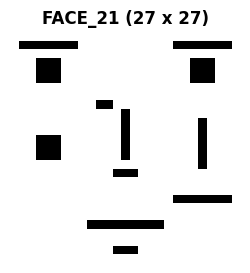

In [49]:
def ink(rows):
    """A 3 x 3 filter of the first level from three strings: '#' -> +1 (ink wanted), '.' -> -1 (blank wanted)."""
    return np.array([[1.0 if c == "#" else -1.0 for c in row] for row in rows])


def wants(spec, channels):
    """A 3 x 3 filter of a higher level: +1 where the input channel must be on, 0 (don't care) everywhere else."""
    w = np.zeros((channels, 3, 3))
    for channel, (i, j) in spec:
        w[channel, i, j] = 1.0
    return w


H, V, B, L, R = range(5)                       # the five filters of level 1
L1_21 = np.stack([ink(["...", "###", "..."]), ink([".#.", ".#.", ".#."]), ink(["###", "###", "###"]),
                  ink(["...", ".##", "..."]), ink(["...", "##.", "..."])])[:, None]     # (5, 1, 3, 3)
E, N, M = range(3)                             # level 2: eye, nose, mouth
L2_21 = np.stack([wants([(H, (0, 0)), (H, (0, 1)), (H, (0, 2)), (B, (1, 1))], 5),          # eyebrow over a pupil
                  wants([(V, (0, 1)), (V, (1, 1)), (H, (2, 1))], 5),                         # a vertical line on a base
                  wants([(L, (1, 0)), (H, (1, 1)), (R, (1, 2)), (H, (2, 1))], 5)])          # a long line over a short one
L3_21 = np.stack([wants([(E, (0, 0)), (E, (0, 2)), (N, (1, 1)), (M, (2, 1))], 3),          # a face seen from the front
                  wants([(E, (0, 1)), (N, (1, 2)), (M, (2, 2))], 3)])                        # a face in profile
FACE_21 = np.zeros((27, 27))
for r_21, c0_21, c1_21 in [(1, 1, 7), (1, 19, 25), (16, 12, 14), (22, 9, 17), (25, 12, 14), (19, 19, 25), (8, 10, 11)]:
    FACE_21[r_21, c0_21:c1_21 + 1] = 1.0       # horizontal strokes
FACE_21[3:6, 3:6] = FACE_21[3:6, 21:24] = FACE_21[12:15, 3:6] = 1.0   # solid blocks
FACE_21[9:15, 13] = FACE_21[10:16, 22] = 1.0   # vertical strokes
SHIFTED_21 = np.zeros((27, 27))
SHIFTED_21[:, 1:] = FACE_21[:, :26]            # the same drawing, one pixel to the right
NAMES_21 = ["H", "V", "B", "L", "R"], ["oeil", "nez", "bouche"], ["face", "profil"]
plt.figure(figsize=(3, 3))
plt.imshow(FACE_21, cmap="gray_r")
plt.title("FACE_21 (27 x 27)")
plt.axis("off")
plt.show()

✅ Ex 21.21 : detect_21 rend des cartes (5, 9, 9), (3, 3, 3) et 2 scores.


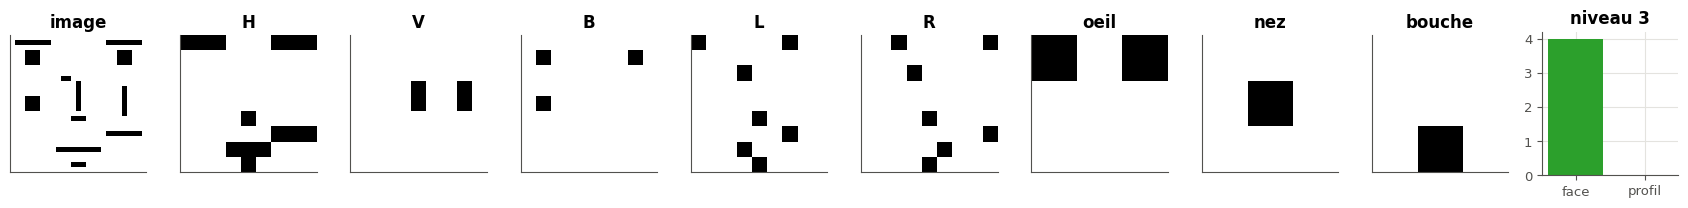

✅ Ex 21.21a : Exact !
✅ Ex 21.21b : Bien joué !
✅ Ex 21.21c : C'est ça !
✅ Ex 21.21d : Parfait !


In [50]:
def detect_21(image):
    """The three levels of filters on a (27, 27) image, with YOUR mylearn.conv.conv2d and max_pool2d.

    Level 1 and 2: conv2d with padding=1, a match where the score equals the number of +1 of the filter (a 0/1 float
    map), then max_pool2d(…, 3). Level 3: conv2d without padding, the raw scores.
    Returns (level1, level2, scores3): (5, 9, 9), (3, 3, 3) and (2,) arrays.
    """
    C = mylearn.conv
    maps = np.asarray(image, dtype=float)[None, None]                  # (1, 1, 27, 27)
    for bank in (L1_21, L2_21):
        scores = C.conv2d(maps, bank, padding=1)
        wanted = (bank > 0).sum(axis=(1, 2, 3))                          # the number of +1 of each filter
        maps = C.max_pool2d((scores == wanted[None, :, None, None]).astype(float), 3)
        if bank is L1_21:
            level1 = maps[0]
    return level1, maps[0], C.conv2d(maps, L3_21)[0, :, 0, 0]


def show_21(image, level1, level2, scores3):
    """The figure of the detector: the image, the 5 maps of level 1, the 3 maps of level 2 and the 2 final scores
    (a bar chart). End with plt.show()."""
    fig, axes = plt.subplots(1, 10, figsize=(17, 2.2))
    panels = [(image, "image")] + list(zip(level1, NAMES_21[0])) + list(zip(level2, NAMES_21[1]))
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])
    wanted = (L3_21 > 0).sum(axis=(1, 2, 3))
    axes[-1].bar(NAMES_21[2], scores3, color=["tab:green" if s == w else "tab:gray" for s, w in zip(scores3, wanted)])
    axes[-1].set_title("niveau 3")
    plt.tight_layout()
    plt.show()


level1_s21, level2_s21, scores3_s21 = detect_21(FACE_21)
n1_21 = int(level1_s21.sum())
n2_21 = int(level2_s21.sum())
WANTED_S21 = (L3_21 > 0).sum(axis=(1, 2, 3))
face_21 = "A" if scores3_s21[0] == WANTED_S21[0] else "B" if scores3_s21[1] == WANTED_S21[1] else "C"
scores_shift_s21 = detect_21(SHIFTED_21)[2]
shifted_21 = "A" if scores_shift_s21[0] == WANTED_S21[0] else "B" if scores_shift_s21[1] == WANTED_S21[1] else "C"
with checked("21.21"):
    result_21 = detect_21(FACE_21.copy())
    if returned("21.21", "detect_21", result_21):
        level1_21, level2_21, scores3_21 = pair("21.21", "detect_21", result_21, names=("level1", "level2", "scores3"))
        shapes_21 = [np.shape(level1_21), np.shape(level2_21), np.shape(scores3_21)]
        verdict("21.21", shapes_21 == [(5, 9, 9), (3, 3, 3), (2,)], "detect_21 rend des cartes (5, 9, 9), (3, 3, 3) et 2 scores.",
                f"detect_21 rend des formes {shapes_21} : attendu (5, 9, 9), (3, 3, 3) et (2,) (pense au [0] qui retire l'axe des exemples).")
        if shapes_21 == [(5, 9, 9), (3, 3, 3), (2,)]:
            show_21(FACE_21, level1_21, level2_21, scores3_21)
wb.check("21.21a", n1_21)
wb.check("21.21b", n2_21)
wb.check("21.21c", face_21)
wb.check("21.21d", shifted_21)

In [51]:
wb.record("21.21a", n1_21, mistakes={"compte les cases à 1 APRÈS le max pooling 3 x 3 du niveau 1 (des cartes 9 x 9)":
          int((mylearn.conv.conv2d(FACE_21[None, None], L1_21, padding=1) == (L1_21 > 0).sum(axis=(1, 2, 3))[None, :, None, None]).sum()),
          "une correspondance, c'est un score ÉGAL au nombre de +1 du filtre, pas seulement positif":
          int(mylearn.conv.max_pool2d((mylearn.conv.conv2d(FACE_21[None, None], L1_21, padding=1) > 0).astype(float), 3).sum())})
wb.record("21.21b", n2_21, mistakes={"une correspondance du niveau 2 demande TOUS ses +1 : un score égal au nombre de +1, pas seulement positif":
          int(mylearn.conv.max_pool2d((mylearn.conv.conv2d(level1_s21[None], L2_21, padding=1) > 0).astype(float), 3).sum())})
wb.record("21.21c", face_21, mistakes={"relis les scores du niveau 3 : lequel atteint le nombre de +1 de son filtre ?": "B", "un des deux filtres du niveau 3 trouve son motif : lequel ?": "C"})
wb.record("21.21d", shifted_21, mistakes={"lance detect_21 sur SHIFTED_21 : le décalage d'un pixel change les blocs du pooling": "A", "relis les scores du niveau 3 pour SHIFTED_21": "B"})

WB_ANSWER {"hash": "4dc9a03647a781941fab119ea25d621dccf9f99e2e933dc053763d781a557d58", "id": "21.21a", "kind": "int", "magnitude": 1, "mistakes": {"8c48c8a0af0a6a20cdb4c56ef5b939dcaa3fdc54f5f98e61594301eb8aa6f940": "compte les cases à 1 APRÈS le max pooling 3 x 3 du niveau 1 (des cartes 9 x 9)", "d91f2ec4a45bb07c30017562eef321bc542defddf7d2c640378f24c6621d7b1d": "une correspondance, c'est un score ÉGAL au nombre de +1 du filtre, pas seulement positif"}, "sign": 1}
📝 Ex 21.21a : réponse enregistrée (int).
WB_ANSWER {"hash": "f3dc5d1b515692aaf9894f5a0e74a7072aa21dbe2c5705dc3670dff3b9f77774", "id": "21.21b", "kind": "int", "magnitude": 0, "mistakes": {"5209f630a9465cfdcbc39999eb44be25827545f2254be41d889f6f275554c6e8": "une correspondance du niveau 2 demande TOUS ses +1 : un score égal au nombre de +1, pas seulement positif"}, "sign": 1}
📝 Ex 21.21b : réponse enregistrée (int).
WB_ANSWER {"hash": "27b17d9fa7850535f8d6257b1dbd39aa8fb151cd882aa93f05e880f6862f480e", "id": "21.21c", "kind": "s

💡 Le max pooling 3 × 3 regroupe les pixels par blocs **fixes** : décalé d'un pixel, un trait peut passer d'un bloc à son voisin, et le motif du niveau 2 n'est plus aligné. La hiérarchie tolère les positions **à l'intérieur** d'un bloc, pas n'importe quel décalage. Un filtre du niveau 3 dépend de 35 × 35 pixels (plus que l'image). Un CNN entraîné apprend ses filtres à partir de milliers d'exemples, avec des poids réels au lieu de $\pm 1$, des chevauchements (stride 1, poolings de stride 2) et beaucoup plus de filtres par niveau : il tolère les décalages, les déformations et le bruit que ces règles exactes refusent.

## Partie C · Le convnet du livre sur Fashion-MNIST : entraîner, diagnostiquer, réparer, comparer

Tu traduis en PyTorch le convnet MNIST du livre et tu l'entraînes sur Fashion-MNIST (21.22) ; tu lis les courbes et la matrice de confusion d'un entraînement complet (21.23), tu répares un CNN dont les formes ne passent pas (21.24), puis tu mesures l'effet de l'initialisation (21.25) et du choix entre stride et pooling (21.26). La cellule suivante prépare les données des parties C et D : des tenseurs `(N, 1, 28, 28)` de valeurs dans $[0, 1]$ ; les images de test restent cachées jusqu'au défi (21.32).

In [52]:
# Fashion-MNIST for parts C and D: training and validation images, tensors (N, 1, 28, 28) in [0, 1]
CLASSES = wb.datasets.FASHION_CLASSES
X_FM, Y_FM = wb.datasets.load_fashion_mnist("train", normalize=True, seed=None)     # the 60 000 training images
ORDER_FM = np.random.default_rng(2122).permutation(len(X_FM))
N_TRAIN, N_VAL = (10_000, 2_000) if FAST_MODE else (50_000, 10_000)
X_TRAIN = torch.from_numpy(X_FM[ORDER_FM[:N_TRAIN]]).unsqueeze(1)
Y_TRAIN = torch.from_numpy(Y_FM[ORDER_FM[:N_TRAIN]])
X_VAL = torch.from_numpy(X_FM[ORDER_FM[50_000:50_000 + N_VAL]]).unsqueeze(1)
Y_VAL = torch.from_numpy(Y_FM[ORDER_FM[50_000:50_000 + N_VAL]])
print(f"X_TRAIN {tuple(X_TRAIN.shape)} · X_VAL {tuple(X_VAL.shape)} · the test images stay hidden (21.32)")

X_TRAIN (10000, 1, 28, 28) · X_VAL (2000, 1, 28, 28) · the test images stay hidden (21.32)


### Ex 21.22 — Le convnet MNIST du livre en PyTorch, sur Fashion-MNIST 📦 ★★★ ⏱️ 45 min
**Objectif :** traduire en PyTorch le convnet du livre, écrire sa boucle d'entraînement et l'adapter à d'autres tailles d'image.  
**Prérequis :** ch. 20 (la boucle d'entraînement, 20.23) · ✏️ 21.4 · fiche §21.7, §21.9 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, M, C

Le convnet du livre (fiche §21.9 et son encadré 🕰️ « de `mnist_cnn.py` à PyTorch ») : deux convolutions 3 × 3 sans padding (32 puis 64 filtres), un max pooling 2 × 2, un dropout de 0,25, l'aplatissement, une couche dense de 128 neurones, un dropout de 0,5 et une couche dense de 10 sorties, avec des ReLU après les convolutions et la première couche dense. Fashion-MNIST a la même forme que MNIST : 28 × 28 pixels, 10 classes de vêtements.

**Contrat**
- `make_convnet_22()` rend un `nn.Sequential` de **onze** couches, dans cet ordre : `Conv2d`, `ReLU`, `Conv2d`, `ReLU`, `MaxPool2d`, `Dropout`, `Flatten`, `Linear`, `ReLU`, `Dropout`, `Linear` ; il transforme des images `(N, 1, 28, 28)` en `(N, 10)` **logits** (pas de softmax : elle est dans la loss) ;
- `train_22(model, X, y, epochs=2, batch_size=128, lr=1e-3, seed=0)` entraîne `model` **en place** (il est déjà sur `DEVICE`, et chaque mini-batch y est envoyé) avec `torch.optim.Adam(lr)` et `nn.CrossEntropyLoss`, en mode entraînement ; à chaque epoch, un nouvel ordre aléatoire des exemples, tiré par `torch.randperm` avec **un** générateur `torch.Generator().manual_seed(seed)` créé avant la boucle ; il rend la liste des loss moyennes de chaque epoch (la moyenne sur les **exemples**, pondérée par la taille de chaque mini-batch), en `float` Python ;
- a) `in_features_22` : le nombre d'entrées de la première couche dense si les images faisaient 32 × 32 pixels (des photos de CIFAR-10 en gris) ;
- b) `params32_22` : le nombre de paramètres de tout le réseau pour ces images 32 × 32.

La vérification construit le réseau, contrôle sa sortie, ses couches et son nombre de paramètres, l'entraîne 3 epochs sur les 10 000 images d'entraînement (12 epochs sur 50 000 en mode complet ; une trentaine de secondes sur un CPU en mode rapide), puis mesure l'accuracy de validation (au moins 0,80 attendu en mode rapide, 0,90 en mode complet). Le modèle entraîné, `model_22`, resservira en 21.28 et 21.29.

Dans tes notes : le script du livre utilisait Adadelta avec `lr=1.0` ; pourquoi ne faut-il pas recopier ce `lr` avec Adam ? Où se trouvent l'essentiel des paramètres de ce réseau, et que changerait un pooling moyen global avant la couche dense ?

In [53]:
def make_convnet_22():
    """The convnet of the book (fiche §21.9), in PyTorch: an nn.Sequential that turns (N, 1, 28, 28) images into
    (N, 10) logits."""
    return nn.Sequential(
        nn.Conv2d(1, 32, 3), nn.ReLU(),
        nn.Conv2d(32, 64, 3), nn.ReLU(),
        nn.MaxPool2d(2), nn.Dropout(0.25),
        nn.Flatten(),
        nn.Linear(64 * 12 * 12, 128), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(128, 10))                       # logits: the softmax is inside nn.CrossEntropyLoss


def train_22(model, X, y, epochs=2, batch_size=128, lr=1e-3, seed=0):
    """Train `model` in place with Adam(lr) and nn.CrossEntropyLoss, on mini-batches of a new random order at each
    epoch (torch.randperm with torch.Generator().manual_seed(seed), created once). Return the list of the mean training
    loss of each epoch (Python floats)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(seed)
    history = []
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(X), generator=generator)
        total = 0.0
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            xb, yb = X[batch].to(DEVICE), y[batch].to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)              # weighted by the size of the (last, smaller) mini-batch
        history.append(total / len(X))
    return history


in_features_22 = 64 * 14 * 14                     # 32 -> 30 -> 28 -> pooling -> 14
params32_22 = 32 * (9 + 1) + 64 * (32 * 9 + 1) + in_features_22 * 128 + 128 + 128 * 10 + 10


model_22 = None
EPOCHS_22 = 3 if FAST_MODE else 12
with checked("21.22"):
    torch.manual_seed(2122)
    net_22 = make_convnet_22()
    if returned("21.22", "make_convnet_22", net_22):
        net_22 = net_22.to(DEVICE)
        out_22 = net_22(X_TRAIN[:5].to(DEVICE))
        verdict("21.22", tuple(out_22.shape) == (5, 10), "le réseau rend (5, 10) pour 5 images : 10 logits par image.",
                f"le réseau rend la forme {tuple(out_22.shape)} pour 5 images : attendu (5, 10).")
        kinds_22 = [type(layer).__name__ for layer in net_22]
        want_kinds_22 = ["Conv2d", "ReLU", "Conv2d", "ReLU", "MaxPool2d", "Dropout", "Flatten", "Linear", "ReLU", "Dropout", "Linear"]
        verdict("21.22", kinds_22 == want_kinds_22, "les onze couches du convnet du livre, dans l'ordre.",
                f"les couches sont {kinds_22} : attendu celles du tableau du §21.9 (la softmax n'est pas une couche : elle est dans la loss).")
        verdict("21.22", n_params(net_22) == _book_convnet_params(), "le nombre de paramètres est celui du convnet du livre.",
                f"le réseau a {n_params(net_22)} paramètres : compare-le, couche par couche, à ton calcul de ✏️ 21.4.")
        start_22 = time.perf_counter()
        history_22 = train_22(net_22, X_TRAIN, Y_TRAIN, epochs=EPOCHS_22, seed=0)
        seconds_22 = time.perf_counter() - start_22
        if returned("21.22", "train_22", history_22):
            ok_hist_22 = (isinstance(history_22, list) and len(history_22) == EPOCHS_22
                          and all(isinstance(v, float) for v in history_22))
            verdict("21.22", ok_hist_22, f"train_22 rend {EPOCHS_22} loss moyennes, des float Python.",
                    f"train_22 doit rendre une liste de {EPOCHS_22} float Python (une loss moyenne par epoch) ; reçu {history_22!r:.120}.")
            if ok_hist_22:
                print("training loss per epoch:", [round(v, 4) for v in history_22], f"· {seconds_22:.0f} s")
                verdict("21.22", history_22[-1] < history_22[0], "la loss d'entraînement baisse d'une epoch à l'autre.",
                        "la loss d'entraînement ne baisse pas : vérifie zero_grad, backward et step, et le learning rate.")
            acc_22 = accuracy(net_22, X_VAL, Y_VAL)
            target_22 = 0.80 if FAST_MODE else 0.90
            verdict("21.22", acc_22 >= target_22, f"accuracy de validation {acc_22:.3f} (au moins {target_22:.2f} attendu).",
                    f"accuracy de validation {acc_22:.3f} : attendu au moins {target_22:.2f} ; relis le contrat de train_22.")
            model_22 = net_22                          # reused by 21.28 and 21.29
wb.check("21.22a", in_features_22)
wb.check("21.22b", params32_22)

✅ Ex 21.22 : le réseau rend (5, 10) pour 5 images : 10 logits par image.
✅ Ex 21.22 : les onze couches du convnet du livre, dans l'ordre.
✅ Ex 21.22 : le nombre de paramètres est celui du convnet du livre.


✅ Ex 21.22 : train_22 rend 3 loss moyennes, des float Python.
training loss per epoch: [0.9299, 0.5645, 0.4848] · 21 s
✅ Ex 21.22 : la loss d'entraînement baisse d'une epoch à l'autre.


✅ Ex 21.22 : accuracy de validation 0.853 (au moins 0.80 attendu).
✅ Ex 21.22a : Bien joué !
✅ Ex 21.22b : C'est ça !


In [54]:
wb.record("21.22a", in_features_22, mistakes={"le pooling vient après les DEUX convolutions, sans padding chacune": 64 * 15 * 15,
          "n'oublie pas le pooling, qui divise le côté par 2": 64 * 28 * 28, "c'est la taille pour des images 28 x 28 : refais les tailles avec 32": 9216})
wb.record("21.22b", params32_22, mistakes={"ajoute les biais de chaque couche": params32_22 - 32 - 64 - 128 - 10,
          "seule la première couche dense change : les convolutions gardent leurs poids quelle que soit la taille de l'image": 1_199_882})

WB_ANSWER {"hash": "9d399abb2aa6f407760b1a5274e3498cecb90199059567fa3f442177a53344e0", "id": "21.22a", "kind": "int", "magnitude": 4, "mistakes": {"14bf3dce55ceb53c0b914404216788c43208bb216b869388a7dcfd6447ec8f7f": "c'est la taille pour des images 28 x 28 : refais les tailles avec 32", "5cc7e5a00b1e0afc3386fc4f2c5b3e6d8989903b56787e56229ebf4f68701e6a": "le pooling vient après les DEUX convolutions, sans padding chacune", "e012f25a4beb9ea6f61e8117ab75bbe2263f2df22ab25b0643ddf87e364546b8": "n'oublie pas le pooling, qui divise le côté par 2"}, "sign": 1}
📝 Ex 21.22a : réponse enregistrée (int).
WB_ANSWER {"hash": "ba1982064f1ebf7712aec274d38f47492a3ad12c4783a3f41dfeeff37a43dcc5", "id": "21.22b", "kind": "int", "magnitude": 6, "mistakes": {"0798295c600b5a2c7007917194436771eb4390f4501b67df48616968af7bf2c7": "ajoute les biais de chaque couche", "16c4545294d56d192f6def5c7b7f5aeae84491a374e138ab13ddf7ae2b2501ef": "seule la première couche dense change : les convolutions gardent leurs poids que

💡 Le `lr` d'Adadelta multiplie un pas déjà adapté à l'échelle des gradients, si bien que 1,0 y est la valeur par défaut ; avec Adam, `lr` **est** la taille du pas, et 1,0 ferait exploser l'entraînement (le défaut est $10^{-3}$). 98 % des paramètres sont dans la première couche dense ($9\,216 \times 128$) ; un pooling moyen global ramènerait les 64 cartes à 64 nombres, et cette couche à $64 \times 128 + 128 = 8\,320$ paramètres, au prix d'une partie de l'information de position.

### Ex 21.23 — Diagnostiquer les courbes et la matrice de confusion du CNN 📈 ★★ ⏱️ 15 min
**Objectif :** lire sur deux entraînements complets l'effet du dropout, choisir l'epoch d'un early stopping, et trouver dans une matrice de confusion la classe que le réseau reconnaît le moins bien.  
**Prérequis :** Ex 21.22 · ch. 3 (matrice de confusion, recall, precision) · Ex 20.25 · fiche §21.9 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Deux entraînements complets du convnet de 21.22, trop longs pour ce notebook (un quart d'heure chacun sur un CPU), ont été faits pour toi (`tools/chapters/history_ch21.py`) : 15 epochs d'Adam sur 50 000 images d'entraînement de Fashion-MNIST, l'un **avec** les deux dropouts du livre, l'autre **sans**, tout le reste identique. Après chaque epoch, la loss et l'accuracy ont été mesurées **en mode évaluation** (sans dropout) sur 10 000 des images d'entraînement et sur les 10 000 images de validation : les deux courbes sont donc comparables. Les historiques sont dans `RUNS_23` (des listes de 15 valeurs) ; `CM_23` est la matrice de confusion de l'entraînement B après sa dernière epoch, sur les 10 000 images de validation (ligne = classe vraie, colonne = classe prédite).

Écris `per_class_23(cm)`, qui rend `(recall, precision)` : le recall et la precision de chaque classe (ch. 3), deux tableaux de réels de forme `(K,)` ; une classe dont la ligne est vide a un recall de 0, une classe jamais prédite (colonne vide) une precision de 0, sans `nan` ni avertissement. Puis, en calculant chaque réponse à partir de `RUNS_23` et de `CM_23` :
a) `dropout_23` : l'entraînement fait **avec** les dropouts (`"A"` ou `"B"`) ;
b) `stop_23` : pour A, l'epoch dont un early stopping sur la loss de validation garderait les poids (la première epoch est la n° 1) ;
c) `gap_23` : pour A, à sa dernière epoch, l'accuracy d'entraînement moins l'accuracy de validation (vérifiée à 3 décimales) ;
d) `worst_23` : dans `CM_23`, l'indice (0 à 9) de la classe de plus faible recall ;
e) `instead_23` : l'indice de l'**autre** classe le plus souvent prédite pour les images de la classe `worst_23` ;
f) `share_23` : la part des erreurs de `CM_23` (les cases hors de la diagonale) dont la classe vraie **ou** la classe prédite est `worst_23` (vérifiée à 3 décimales).

Dans tes notes : après l'epoch de b), la loss de validation de A remonte ; son accuracy de validation baisse-t-elle autant ? Qu'est-ce qui peut faire monter une loss sans changer les prédictions ? Regarde les quatre classes Shirt, T-shirt/top, Pullover et Coat dans la matrice : que faudrait-il au réseau pour mieux les séparer ?

classes: 0 T-shirt/top, 1 Trouser, 2 Pullover, 3 Dress, 4 Coat, 5 Sandal, 6 Shirt, 7 Sneaker, 8 Bag, 9 Ankle boot


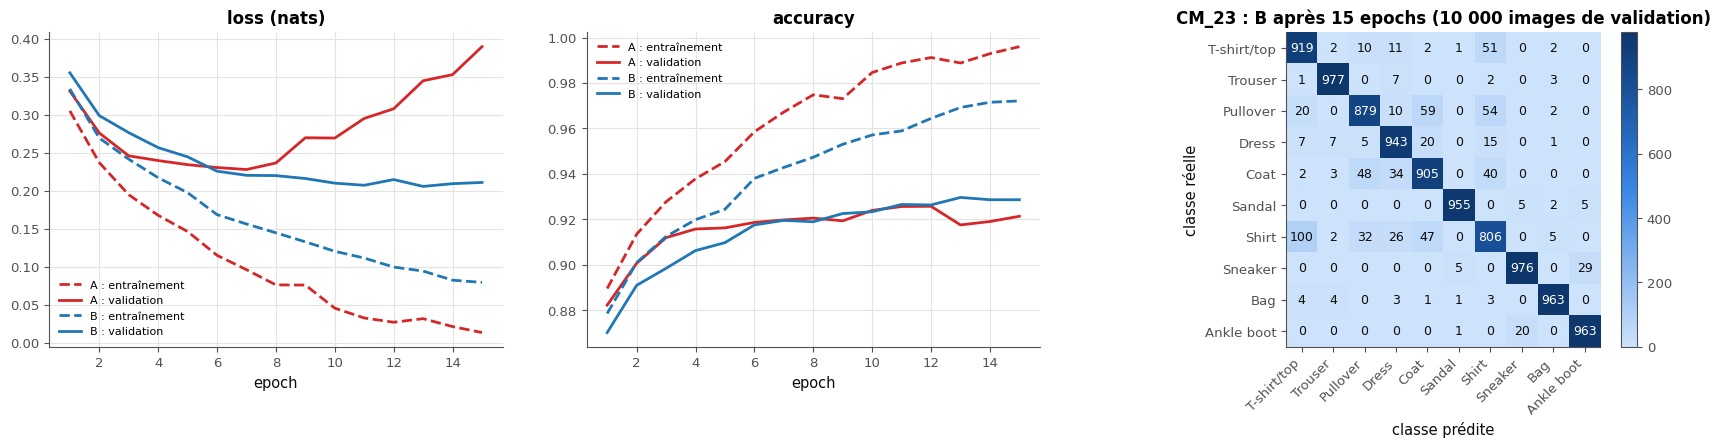

In [55]:
# Two runs of the convnet of the book, 15 epochs on 50 000 images (precomputed: too long for this notebook).
# After each epoch, measured in evaluation mode on 10 000 training images and on the 10 000 validation images.
RUNS_23 = {
    "A": {
        "train_loss": [0.305, 0.237, 0.1948, 0.1677, 0.1464, 0.1151, 0.0962, 0.0762, 0.076, 0.0456, 0.0327, 0.0271, 0.0318, 0.0214, 0.0135],
        "train_acc": [0.8895, 0.9134, 0.9277, 0.9378, 0.9454, 0.9585, 0.9672, 0.9748, 0.9731, 0.9846, 0.9888, 0.9912, 0.9888, 0.9929, 0.996],
        "val_loss": [0.3311, 0.276, 0.2459, 0.2397, 0.2343, 0.2305, 0.2279, 0.2365, 0.2697, 0.2693, 0.2951, 0.3078, 0.3446, 0.3527, 0.3895],
        "val_acc": [0.8822, 0.9006, 0.9119, 0.9157, 0.9162, 0.9186, 0.9197, 0.9205, 0.9193, 0.9239, 0.9256, 0.9257, 0.9175, 0.919, 0.9213],
    },
    "B": {
        "train_loss": [0.3339, 0.2694, 0.2415, 0.2171, 0.1975, 0.1686, 0.1563, 0.1447, 0.1328, 0.1204, 0.1115, 0.0997, 0.0944, 0.0824, 0.0795],
        "train_acc": [0.8785, 0.9009, 0.9124, 0.9198, 0.9244, 0.938, 0.9428, 0.9473, 0.953, 0.9571, 0.9589, 0.9644, 0.9692, 0.9715, 0.9721],
        "val_loss": [0.3551, 0.2988, 0.2764, 0.2567, 0.2446, 0.2257, 0.2203, 0.2199, 0.2161, 0.21, 0.2072, 0.2147, 0.2057, 0.2093, 0.2109],
        "val_acc": [0.8701, 0.8909, 0.8984, 0.9062, 0.9097, 0.9175, 0.9195, 0.9189, 0.9225, 0.9233, 0.9265, 0.9263, 0.9296, 0.9286, 0.9286],
    },
}
CM_23 = np.array([   # run B after its 15th epoch: row = true class, column = predicted class
    [919, 2, 10, 11, 2, 1, 51, 0, 2, 0],
    [1, 977, 0, 7, 0, 0, 2, 0, 3, 0],
    [20, 0, 879, 10, 59, 0, 54, 0, 2, 0],
    [7, 7, 5, 943, 20, 0, 15, 0, 1, 0],
    [2, 3, 48, 34, 905, 0, 40, 0, 0, 0],
    [0, 0, 0, 0, 0, 955, 0, 5, 2, 5],
    [100, 2, 32, 26, 47, 0, 806, 0, 5, 0],
    [0, 0, 0, 0, 0, 5, 0, 976, 0, 29],
    [4, 4, 0, 3, 1, 1, 3, 0, 963, 0],
    [0, 0, 0, 0, 0, 1, 0, 20, 0, 963],
])
print("classes:", ", ".join(f"{k} {name}" for k, name in enumerate(CLASSES)))
epochs_23 = np.arange(1, 16)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for (name_23, run_23), color_23 in zip(RUNS_23.items(), ["tab:red", "tab:blue"]):
    axes[0].plot(epochs_23, run_23["train_loss"], ls="--", color=color_23, label=f"{name_23} : entraînement")
    axes[0].plot(epochs_23, run_23["val_loss"], color=color_23, label=f"{name_23} : validation")
    axes[1].plot(epochs_23, run_23["train_acc"], ls="--", color=color_23, label=f"{name_23} : entraînement")
    axes[1].plot(epochs_23, run_23["val_acc"], color=color_23, label=f"{name_23} : validation")
axes[0].set_title("loss (nats)")
axes[1].set_title("accuracy")
for ax in axes[:2]:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
wb.plot.plot_confusion_matrix(CM_23, CLASSES, ax=axes[2], title="CM_23 : B après 15 epochs (10 000 images de validation)")
plt.tight_layout()
plt.show()

In [56]:
def per_class_23(cm):
    """(recall, precision) of each class for a confusion matrix cm (row = true class, column = predicted class): two
    float arrays of shape (K,). A class with an empty row has a recall of 0, one with an empty column a precision of 0."""
    cm = np.asarray(cm, dtype=float)
    diag = np.diag(cm)
    rows, cols = cm.sum(axis=1), cm.sum(axis=0)
    recall = np.divide(diag, rows, out=np.zeros_like(diag), where=rows > 0)
    precision = np.divide(diag, cols, out=np.zeros_like(diag), where=cols > 0)
    return recall, precision


recall_23, precision_23 = per_class_23(CM_23)
errors_23 = CM_23 - np.diag(np.diag(CM_23))          # the off-diagonal cells: the errors only
dropout_23 = "B"
stop_23 = int(np.argmin(RUNS_23["A"]["val_loss"])) + 1
gap_23 = RUNS_23["A"]["train_acc"][-1] - RUNS_23["A"]["val_acc"][-1]
worst_23 = int(np.argmin(recall_23))
instead_23 = int(np.argmax(errors_23[worst_23]))
share_23 = (errors_23[worst_23].sum() + errors_23[:, worst_23].sum()) / errors_23.sum()
with checked("21.23"):
    if written(lambda: per_class_23(np.eye(2))):
        recall_c23, precision_c23 = pair("21.23", "per_class_23", per_class_23(CM_23), names=("recall", "precision"))
        same("21.23", "le recall de chaque classe de CM_23 (la diagonale divisée par la somme de la LIGNE)", recall_c23,
             np.diag(CM_23) / CM_23.sum(axis=1))
        same("21.23", "la precision de chaque classe de CM_23 (la diagonale divisée par la somme de la COLONNE)", precision_c23,
             np.diag(CM_23) / CM_23.sum(axis=0))
        small_23 = np.array([[3, 0, 1], [1, 0, 0], [0, 0, 0]])      # class 1 never predicted, class 2 never present
        recall_s23, precision_s23 = pair("21.23", "per_class_23", per_class_23(small_23), names=("recall", "precision"))
        same("21.23", "per_class_23 d'une matrice dont une ligne et une colonne sont vides (0, sans nan ni avertissement)",
             np.concatenate([recall_s23, precision_s23]), [0.75, 0.0, 0.0, 0.75, 0.0, 0.0])
    else:
        print("⏳ Ex 21.23 : écris per_class_23.")
for letter_23, value_23 in zip("abcdef", [dropout_23, stop_23, gap_23, worst_23, instead_23, share_23]):
    wb.check(f"21.23{letter_23}", value_23)

✅ Ex 21.23 : le recall de chaque classe de CM_23 (la diagonale divisée par la somme de la LIGNE) : un tableau (10,), comme attendu.
✅ Ex 21.23 : la precision de chaque classe de CM_23 (la diagonale divisée par la somme de la COLONNE) : un tableau (10,), comme attendu.
✅ Ex 21.23 : per_class_23 d'une matrice dont une ligne et une colonne sont vides (0, sans nan ni avertissement) : [0.75, 0.0, 0.0, 0.75, 0.0, 0.0], comme attendu.
✅ Ex 21.23a : C'est ça !
✅ Ex 21.23b : Parfait !
✅ Ex 21.23c : Bravo !
✅ Ex 21.23d : Exact !
✅ Ex 21.23e : Bien joué !
✅ Ex 21.23f : C'est ça !


In [57]:
wb.record("21.23a", "B", mistakes={"regarde l'écart entre l'entraînement et la validation : le dropout le réduit, et la loss de validation de A remonte": "A"})
wb.record("21.23b", stop_23, mistakes={'les epochs sont comptées à partir de 1': 6,
          "on garde le minimum de la loss de VALIDATION, pas celui de la loss d'entraînement": 15,
          "le minimum de la loss de validation, pas le maximum de l'accuracy de validation": 12,
          "c'est l'epoch de B ; b) demande celle de A": 13})
wb.record("21.23c", gap_23, decimals=3, mistakes={"c'est l'écart de B ; c) demande celui de A": 0.0435,
          "l'accuracy d'entraînement MOINS celle de validation : un nombre positif": -0.0747,
          "c'est l'écart des LOSSES ; c) demande celui des accuracies": 0.376})
wb.record("21.23d", worst_23, mistakes={})
wb.record("21.23e", instead_23, mistakes={'une AUTRE classe que worst_23 : la diagonale ne compte pas': 6,
          'tu as lu la colonne de worst_23 (les images PRÉDITES worst_23) ; e) demande sa ligne (les images de cette classe)': 2})
wb.record("21.23f", share_23, decimals=3, mistakes={'compte aussi les erreurs où worst_23 est la classe PRÉDITE (sa colonne)': 0.2969,
          'compte aussi les erreurs où worst_23 est la classe VRAIE (sa ligne)': 0.2311,
          "divise par le nombre d'ERREURS, pas par le nombre d'images": 0.0377})

WB_ANSWER {"hash": "2707ba71dd72dc422ecb80ef35a22e0ebe3735b11ba1e3c6f6966278d2ea4f61", "id": "21.23a", "kind": "str", "mistakes": {"4d8f945a814cf66720a6e148be27bbe1664d1633b562e11d863791271a705ffd": "regarde l'écart entre l'entraînement et la validation : le dropout le réduit, et la loss de validation de A remonte"}}
📝 Ex 21.23a : réponse enregistrée (str).
WB_ANSWER {"hash": "fc8c1e7983568a8977990fa335c1d5ced538eac919bc71708ebd503db0b3759c", "id": "21.23b", "kind": "int", "magnitude": 0, "mistakes": {"19cf0093aadda482fab17592b7738a70f8d32eb8bd40ccd7c57b68083a4542fc": "les epochs sont comptées à partir de 1", "5de9192c18e8ffcdab0c7d36363dfdeafc9a69ff8083c5587eecfa2466549d76": "c'est l'epoch de B ; b) demande celle de A", "703e1b8b38a552288989a3f321c235bcb2cb71220de54ffb8bca312992e91286": "on garde le minimum de la loss de VALIDATION, pas celui de la loss d'entraînement", "fe55a2ff7557275da60fe136095de27655957c48225bfc68e339c251e91b4c5e": "le minimum de la loss de validation, pas le max

💡 A n'a pas de dropout : sa loss d'entraînement plonge, et sa loss de validation passe par un minimum puis remonte (de 0,228 à l'epoch 7 à 0,390 à la 15ᵉ), alors que son accuracy de validation reste presque plate (0,920 puis 0,921). Une loss de cross-entropy monte quand le réseau devient **trop sûr de lui** sur les images qu'il rate (une probabilité de 0,99 sur la mauvaise classe coûte bien plus que 0,6), sans que la classe prédite change. Shirt est la classe la moins bien reconnue, surtout prise pour un T-shirt/top : ces quatre hauts ne se distinguent que par des détails (col, boutons, manches) qu'une image 28 × 28 en gris rend mal ; il faudrait plus de filtres et plus de profondeur, de l'augmentation de données (ch. 24), ou accepter que certaines images sont ambiguës même pour un humain.

### Ex 21.24 — Le CNN dont les formes ne passent pas 🐛 ★★ ⏱️ 20 min
**Objectif :** réparer un CNN traduit de Keras dont les formes ne s'enchaînent pas, en lisant ce que reçoit chaque couche.  
**Prérequis :** Ex 21.22 · fiche §21.4.1, §21.7, encadré 🕰️ « le format des images » · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Un collègue a traduit de Keras un petit CNN : le convnet du livre sans ses dropouts (32 puis 64 filtres 3 × 3, un pooling 2 × 2, une couche dense de 128 neurones, 10 sorties). Ses images arrivent au format de son notebook Keras, `(N, 28, 28, 1)` (`X_NHWC_24`), et sa classe `Net24` ne marche pas : **quatre** bugs, tous des erreurs de forme. Corrige-la **sur place**, dans la cellule, sans changer l'architecture (les nombres de filtres et de neurones restent ceux-là) ni le format des images reçues par `forward`.

La vérification fait passer deux images dans le réseau en lisant ce que reçoit chaque couche (des hooks `register_forward_pre_hook`, ch. 20), et donne ses diagnostics dans l'ordre où les bugs se cachent les uns les autres : tant qu'un point échoue, les suivants attendent (⏳). Elle s'exécute dès le premier « Tout exécuter » : les diagnostics du code fautif sont ton point de départ.

Dans tes notes : pour chaque bug, quel message d'erreur de PyTorch le révèle, et lequel ne lève **aucune** erreur avec un mini-batch d'une seule image ? Comment aurais-tu trouvé les tailles sans les calculer (fais passer un tenseur et lis `x.shape` couche par couche, ou `nn.LazyLinear`) ?

In [58]:
X_NHWC_24 = X_TRAIN[:8].permute(0, 2, 3, 1).contiguous()    # 8 images in the layout of a Keras notebook: (N, 28, 28, 1)
print("X_NHWC_24:", tuple(X_NHWC_24.shape))

X_NHWC_24: (8, 28, 28, 1)


In [59]:
class Net24(nn.Module):
    """The convnet of the book without its dropout (32 then 64 filters 3 x 3, a pooling, a dense layer of 128), translated
    from a Keras notebook: its forward pass receives the images in the Keras layout (N, 28, 28, 1) and must return
    (N, 10) logits. Fix it in place (four bugs)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3)
        self.conv2 = nn.Conv2d(32, 64, 3)        # bug 2: conv2 reads the 32 channels of conv1
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 12 * 12, 128)  # bug 3: 28 -> 26 -> 24 -> pooling -> 12
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):                        # x: (N, 28, 28, 1), the layout of the Keras notebook
        x = x.permute(0, 3, 1, 2)                # bug 1: PyTorch wants (N, C, H, W)
        x = torch.relu(self.conv1(x))
        x = self.pool(torch.relu(self.conv2(x)))
        x = torch.flatten(x, start_dim=1)        # bug 4: keep the axis of the examples
        x = torch.relu(self.fc1(x))
        return self.fc2(x)


def diagnose_24(net_class):
    """The four points of 21.24, in the order where the bugs hide one another; a point is checked only when the
    previous ones pass. Returns the number of points passed."""
    torch.manual_seed(24)
    try:
        net = net_class()
    except NotImplementedError:
        raise
    except Exception as exc:
        print(f"❌ Ex 21.24 : Net24() lève {type(exc).__name__} : {str(exc)[:200]}")
        return 0
    seen = {}

    def spy(name):
        def hook(module, inputs):                 # a pre-hook that returns None leaves the inputs unchanged
            seen.setdefault(name, tuple(inputs[0].shape))
        return hook

    hooks = [getattr(net, name).register_forward_pre_hook(spy(name)) for name in ("conv1", "conv2", "fc1", "fc2")
             if isinstance(getattr(net, name, None), nn.Module)]
    error = None
    try:
        out = net(X_NHWC_24[:2].clone())
    except Exception as exc:                     # the bugs still there raise errors: they are diagnosed below
        out, error = None, exc
    for hook in hooks:
        hook.remove()
    points = [
        ("conv1", seen.get("conv1") == (2, 1, 28, 28),
         f"conv1 reçoit un tenseur de forme {seen.get('conv1')} pour 2 images : une couche Conv2d lit l'axe 1 comme "
         "celui des canaux, et attend (N, C, H, W) = (2, 1, 28, 28)"),
        ("conv2", "conv2" in seen and seen["conv2"][1] == net.conv2.in_channels,
         f"conv2 attend {getattr(net.conv2, 'in_channels', '?')} canaux d'entrée et en reçoit "
         f"{seen['conv2'][1] if 'conv2' in seen else '?'} (la sortie de conv1)"),
        ("fc1", "fc1" in seen and len(seen["fc1"]) == 2 and seen["fc1"][0] == 2,
         f"fc1 reçoit un tenseur de forme {seen.get('fc1')} pour 2 images : une couche dense attend une ligne par image, "
         "(2, valeurs par image)"),
    ]
    for k, (name, ok, message) in enumerate(points, start=1):
        if not ok:
            detail = f" (erreur : {type(error).__name__} : {str(error)[:150]})" if error is not None else ""
            print(f"❌ Ex 21.24 : point {k} : {message}{detail}.")
            for later in range(k + 1, 5):
                print(f"⏳ Ex 21.24 : point {later} : corrige d'abord le point {k}.")
            return k - 1
        print(f"✅ Ex 21.24 : point {k} : {name} reçoit ce qu'elle attend.")
    shape_ok = error is None and out is not None and tuple(out.shape) == (2, 10)
    if shape_ok:
        with torch.no_grad():
            alone = net(X_NHWC_24[:1].clone())
            pair_out = net(X_NHWC_24[:2].clone())
        shape_ok = tuple(alone.shape) == (1, 10) and torch.allclose(alone[0], pair_out[0], atol=1e-6)
    if not shape_ok:
        if error is not None:
            print(f"❌ Ex 21.24 : point 4 : fc1 n'accepte pas ce qu'elle reçoit (erreur : {type(error).__name__} : "
                  f"{str(error)[:150]}) : compare son in_features au nombre de valeurs qu'une image donne après le pooling.")
        else:
            print(f"❌ Ex 21.24 : point 4 : le réseau rend la forme {tuple(out.shape)} pour 2 images (attendu (2, 10)), ou "
                  "la sortie d'une image change quand on lui ajoute une voisine.")
        return 3
    print("✅ Ex 21.24 : point 4 : (N, 10) pour N = 1 et 2, et chaque image ne dépend que d'elle-même.")
    return 4


with checked("21.24"):
    passed_24 = diagnose_24(Net24)
    if passed_24 == 4:
        verdict("21.24", n_params(Net24()) == _book_convnet_params(), "le réseau réparé a les paramètres du convnet du livre (sans dropout).",
                f"le réseau réparé a {n_params(Net24())} paramètres : attendu ceux de ✏️ 21.4.")

✅ Ex 21.24 : point 1 : conv1 reçoit ce qu'elle attend.
✅ Ex 21.24 : point 2 : conv2 reçoit ce qu'elle attend.
✅ Ex 21.24 : point 3 : fc1 reçoit ce qu'elle attend.
✅ Ex 21.24 : point 4 : (N, 10) pour N = 1 et 2, et chaque image ne dépend que d'elle-même.
✅ Ex 21.24 : le réseau réparé a les paramètres du convnet du livre (sans dropout).


💡 Les quatre bugs : les images Keras sont en `(N, H, W, C)` alors qu'une `Conv2d` attend `(N, C, H, W)` (`permute(0, 3, 1, 2)`) ; `conv2` doit lire les 32 canaux que produit `conv1` ; après deux convolutions sans padding (28 → 26 → 24) et le pooling, une image donne $64 \times 12 \times 12 = 9\,216$ valeurs, pas $64 \times 13 \times 13$ ; `torch.flatten(x)` aplatit tout le mini-batch en un seul vecteur, `torch.flatten(x, 1)` (ou `nn.Flatten()`) garde l'axe des exemples. Ce dernier bug ne lève aucune erreur avec une seule image : la sortie a seulement la forme `(10,)` au lieu de `(1, 10)`.

### Ex 21.25 — Briser la symétrie : filtres identiques, aléatoires ou He 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer ce que deviennent des filtres partis de la même valeur, comparés à des départs aléatoires.  
**Prérequis :** Ex 21.22 · ch. 16 (initialisation de He) · fiche §21.7.1 · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Le §21.7.1 affirme que des filtres partis de la même valeur restent identiques. On le mesure sur un petit CNN (`small_cnn_25`, 8 filtres).

**Contrat**
- `init_25(model, kind)` initialise **en place** les poids et les biais de chaque `nn.Conv2d` et `nn.Linear` du modèle : `"constant"`, tous les poids à 0,05 et tous les biais à 0 ; `"default"`, l'initialisation de PyTorch (la méthode `reset_parameters()` de chaque couche) ; `"he"`, `nn.init.kaiming_normal_(poids, nonlinearity="relu")` et les biais à 0 ; un autre nom lève `ValueError` ;
- `distinct_filters_25(weight, tol=1e-6)` rend le nombre de filtres **distincts** d'un poids de convolution `(C_out, C_in, k, k)` (un tenseur ou un tableau) : deux filtres sont les mêmes quand toutes leurs valeurs diffèrent d'au plus `tol`.

La vérification essaie tes deux fonctions, puis, pour chaque initialisation, entraîne le petit CNN une epoch sur 5 000 images avec **ton** `train_22` (21.22), compte ses filtres distincts et mesure son accuracy de validation.

Dans tes notes : pourquoi les filtres partis de 0,05 reçoivent-ils exactement les mêmes gradients à chaque pas (pense au ch. 16) ? Un seul filtre distinct suffit-il à faire mieux que le hasard ? Entre `"default"` et `"he"`, l'écart d'accuracy est-il plus grand que ce que changerait une autre graine ?

In [60]:
def small_cnn_25():
    """A small CNN for the experiment: 8 filters 3 x 3, a pooling, one dense layer."""
    return nn.Sequential(nn.Conv2d(1, 8, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(8 * 13 * 13, 10))


print(small_cnn_25())

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=1352, out_features=10, bias=True)
)


In [61]:
def init_25(model, kind):
    """Initialise IN PLACE the weights and biases of every nn.Conv2d and nn.Linear of `model`:
    "constant": every weight 0.05 and every bias 0 ; "default": the initialisation of PyTorch (reset_parameters) ;
    "he": nn.init.kaiming_normal_(weight, nonlinearity="relu") and biases 0. Any other kind: ValueError."""
    if kind not in ("constant", "default", "he"):
        raise ValueError(f"kind must be 'constant', 'default' or 'he', got {kind!r}")
    for layer in model.modules():
        if not isinstance(layer, (nn.Conv2d, nn.Linear)):
            continue
        if kind == "default":
            layer.reset_parameters()
            continue
        with torch.no_grad():
            if kind == "constant":
                layer.weight.fill_(0.05)
            else:
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            layer.bias.zero_()


def distinct_filters_25(weight, tol=1e-6):
    """The number of distinct filters of a convolution weight (C_out, C_in, k, k) (a tensor or an array): two filters
    are the same when all their values differ by at most tol."""
    filters = as_numpy(weight).reshape(len(weight), -1)
    kept = []
    for f in filters:
        if not any(np.max(np.abs(f - g)) <= tol for g in kept):
            kept.append(f)
    return len(kept)


results_25 = {}
with checked("21.25"):
    probe_25 = small_cnn_25()
    init_25(probe_25, "constant")
    layers_25 = [m for m in probe_25.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    verdict("21.25", all(torch.allclose(m.weight.detach(), torch.full_like(m.weight, 0.05)) for m in layers_25)
            and all(float(m.bias.detach().abs().max()) == 0.0 for m in layers_25),
            "init_25(model, 'constant') : tous les poids à 0,05, tous les biais à 0.",
            "init_25(model, 'constant') : attendu tous les poids à 0,05 et tous les biais à 0, dans les convolutions ET la couche dense.")
    refuses("21.25", "init_25 avec un nom inconnu", lambda: init_25(small_cnn_25(), "xavier"))
    same_w_25 = torch.ones(4, 1, 3, 3)
    same_w_25[2] += 0.5
    verdict("21.25", distinct_filters_25(same_w_25) == 2 and distinct_filters_25(torch.randn(5, 2, 3, 3)) == 5,
            "distinct_filters_25 compte 2 filtres distincts parmi 4 (trois égaux), et 5 parmi 5 filtres aléatoires.",
            "distinct_filters_25 : attendu 2 pour quatre filtres dont trois égaux, et 5 pour cinq filtres aléatoires.")
    for kind_25 in ("constant", "default", "he"):
        torch.manual_seed(25)
        net_25 = small_cnn_25()
        init_25(net_25, kind_25)
        net_25 = net_25.to(DEVICE)
        train_22(net_25, X_TRAIN[:5000], Y_TRAIN[:5000], epochs=1, seed=0)
        results_25[kind_25] = (distinct_filters_25(net_25[0].weight.detach().cpu()), accuracy(net_25, X_VAL, Y_VAL))
        print(f"{kind_25:9}: {results_25[kind_25][0]} distinct filters out of 8 after one epoch · validation accuracy {results_25[kind_25][1]:.3f}")
    verdict("21.25", results_25["constant"][0] == 1, "les filtres partis de la même valeur sont restés identiques.",
            f"init 'constant' : {results_25['constant'][0]} filtres distincts après une epoch ; attendu 1 (relis init_25 et distinct_filters_25).")
    verdict("21.25", results_25["default"][0] == 8 and results_25["he"][0] == 8, "les départs aléatoires gardent 8 filtres distincts.",
            f"départs aléatoires : {results_25['default'][0]} et {results_25['he'][0]} filtres distincts ; attendu 8.")

✅ Ex 21.25 : init_25(model, 'constant') : tous les poids à 0,05, tous les biais à 0.
✅ Ex 21.25 : init_25 avec un nom inconnu : ValueError levée (kind must be 'constant', 'default' or 'he', got 'xavier').
✅ Ex 21.25 : distinct_filters_25 compte 2 filtres distincts parmi 4 (trois égaux), et 5 parmi 5 filtres aléatoires.


constant : 1 distinct filters out of 8 after one epoch · validation accuracy 0.682


default  : 8 distinct filters out of 8 after one epoch · validation accuracy 0.726


he       : 8 distinct filters out of 8 after one epoch · validation accuracy 0.731
✅ Ex 21.25 : les filtres partis de la même valeur sont restés identiques.
✅ Ex 21.25 : les départs aléatoires gardent 8 filtres distincts.


💡 Avec des poids tous égaux, les huit cartes de la convolution sont identiques, la couche dense les voit avec les mêmes poids, donc les gradients des huit filtres sont égaux, et Adam leur applique le même pas : ils restent égaux pour toujours. Le réseau garde un seul filtre utile et apprend quand même quelque chose (bien plus que 10 % de hasard), mais nettement moins que les départs aléatoires. Entre l'initialisation par défaut et celle de He, l'écart après une epoch sur un réseau aussi peu profond est de l'ordre de ce que change une graine : He compte surtout pour les réseaux profonds sans normalisation.

### Ex 21.26 — Stride ou pooling : accuracy et temps sur CIFAR-10 🔬 ★★★ ⏱️ 40 min 🚀
**Objectif :** comparer deux façons de réduire l'image, par pooling ou par stride, en paramètres, en calcul, en temps et en accuracy.  
**Prérequis :** Ex 21.22 · 🧮 21.8 · fiche §21.4.2, §21.9.1 (encadré 🕰️ « après VGG16 ») · **Fil rouge :** CIFAR-10 · **Parcours :** C

Deux façons de diviser la taille d'une image par 2 entre deux couches : un max pooling 2 × 2 après une convolution de stride 1, ou une convolution de stride 2. On compare deux petits réseaux sur des photos de CIFAR-10 (`(N, 3, 32, 32)`, valeurs dans $[0, 1]$).

**Contrat**
- `make_pool_26()` : deux convolutions 3 × 3 de 32 puis 64 filtres (padding 1, stride 1), chacune suivie d'une ReLU et d'un max pooling 2 × 2, puis `nn.Flatten()` et une couche dense vers 10 sorties ;
- `make_stride_26()` : les deux mêmes convolutions avec un stride de 2 (padding 1) et sans pooling, chacune suivie d'une ReLU, puis `nn.Flatten()` et une couche dense vers 10 sorties ;
- les deux rendent `(N, 10)` logits pour des images `(N, 3, 32, 32)`.

La vérification construit les deux réseaux, compte leurs paramètres et leurs multiplications-additions par image (par des hooks sur les couches), les entraîne avec **ton** `train_22` (2 epochs sur 5 000 images en mode rapide, 10 epochs sur 50 000 en mode complet) et mesure le temps d'entraînement et l'accuracy sur 1 000 photos de test. 🚀 En mode complet, un GPU Colab est conseillé (une vingtaine de minutes sur un CPU).

Dans tes notes : d'où vient l'écart de calcul, alors que les paramètres sont les mêmes ? L'écart d'accuracy est-il plus grand que l'écart de temps ? Pourquoi les architectures récentes (l'encadré 🕰️ du §21.9.1) préfèrent-elles le stride ?

In [62]:
N_26 = 5_000 if FAST_MODE else 50_000
EPOCHS_26 = 2 if FAST_MODE else 10
X_C26, Y_C26 = wb.datasets.load_cifar10("train", n=N_26, normalize=True, channels_first=True, seed=26)
X_C26, Y_C26 = torch.from_numpy(X_C26), torch.from_numpy(Y_C26)
X_V26, Y_V26 = wb.datasets.load_cifar10("test", n=1_000, normalize=True, channels_first=True, seed=26)
X_V26, Y_V26 = torch.from_numpy(X_V26), torch.from_numpy(Y_V26)
print("CIFAR-10:", tuple(X_C26.shape), "for training,", tuple(X_V26.shape), "for validation")

CIFAR-10: (5000, 3, 32, 32) for training, (1000, 3, 32, 32) for validation


In [63]:
def make_pool_26():
    """(N, 3, 32, 32) -> (N, 10): two 3 x 3 convolutions (32 then 64 filters, padding 1, stride 1), each followed by
    ReLU and a max pooling 2 x 2, then nn.Flatten and one dense layer."""
    return nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(64 * 8 * 8, 10))


def make_stride_26():
    """(N, 3, 32, 32) -> (N, 10): the same two convolutions with a stride of 2 (padding 1) and no pooling, each followed
    by ReLU, then nn.Flatten and one dense layer."""
    return nn.Sequential(nn.Conv2d(3, 32, 3, stride=2, padding=1), nn.ReLU(),
                         nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
                         nn.Flatten(), nn.Linear(64 * 8 * 8, 10))


def macs_26(model, x):
    """Multiply-adds of the convolutions and dense layers of `model` for one image (counted with forward hooks)."""
    total = [0]

    def count(module, inputs, output):
        if isinstance(module, nn.Conv2d):
            total[0] += output[0].numel() * module.in_channels // module.groups * module.kernel_size[0] * module.kernel_size[1]
        elif isinstance(module, nn.Linear):
            total[0] += module.in_features * module.out_features

    hooks = [m.register_forward_hook(count) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        model(x[:1])
    for hook in hooks:
        hook.remove()
    return total[0]


rows_26 = {}
for name_26, make_26 in [("pooling", make_pool_26), ("stride", make_stride_26)]:
    with checked("21.26"):
        torch.manual_seed(26)
        net_26 = make_26()
        if not returned("21.26", name_26, net_26):
            continue
        net_26 = net_26.to(DEVICE)
        out_26 = net_26(X_C26[:4].to(DEVICE))
        verdict("21.26", tuple(out_26.shape) == (4, 10), f"{name_26} : 10 logits par image.",
                f"{name_26} : le réseau rend {tuple(out_26.shape)} pour 4 images, attendu (4, 10).")
        start_26 = time.perf_counter()
        train_22(net_26, X_C26, Y_C26, epochs=EPOCHS_26, seed=0)
        rows_26[name_26] = (n_params(net_26), macs_26(net_26, X_C26.to(DEVICE)), time.perf_counter() - start_26,
                            accuracy(net_26, X_V26, Y_V26))
if rows_26:
    print(f"{'network':9} {'parameters':>11} {'mult-adds/image':>16} {'training (s)':>13} {'val accuracy':>13}")
    for name_26, (p_26, m_26, t_26, a_26) in rows_26.items():
        print(f"{name_26:9} {p_26:11d} {m_26:16,d} {t_26:13.1f} {a_26:13.3f}".replace(",", " "))
if len(rows_26) == 2:
    verdict("21.26", rows_26["pooling"][0] == rows_26["stride"][0], "les deux réseaux ont le même nombre de paramètres.",
            f"les deux réseaux ont {rows_26['pooling'][0]} et {rows_26['stride'][0]} paramètres : avec le même contrat, ils devraient être égaux.")
    verdict("21.26", (rows_26["pooling"][1], rows_26["stride"][1]) == (5_644_288, 1_441_792),
            f"multiplications-additions par image : {rows_26['pooling'][1]:,} contre {rows_26['stride'][1]:,}".replace(",", " ") + ", 3,9 fois moins avec le stride.",
            "les multiplications-additions par image ne sont pas celles du contrat : vérifie les strides, le padding et les poolings.")

✅ Ex 21.26 : pooling : 10 logits par image.


✅ Ex 21.26 : stride : 10 logits par image.


network    parameters  mult-adds/image  training (s)  val accuracy
pooling         60362        5 644 288           2.8         0.397
stride          60362        1 441 792           0.9         0.363
✅ Ex 21.26 : les deux réseaux ont le même nombre de paramètres.
✅ Ex 21.26 : multiplications-additions par image : 5 644 288 contre 1 441 792, 3,9 fois moins avec le stride.


💡 Les poids sont les mêmes (le pooling n'en a aucun), mais le réseau à pooling calcule ses convolutions sur des images **quatre fois plus grandes** (32 × 32 puis 16 × 16, contre 16 × 16 puis 8 × 8) : environ quatre fois plus de multiplications-additions, et un entraînement plusieurs fois plus long. En échange, il regarde chaque position avant de réduire, et gagne souvent quelques points d'accuracy sur un réseau aussi petit. Les architectures récentes (ResNet, ConvNeXt) réduisent par des convolutions de stride 2 : le réseau apprend lui-même comment réduire, pour un calcul bien moindre, et la profondeur compense.

## Partie D · Regarder les filtres, tromper le réseau, et finir ta librairie

Tu regardes ce que voient les filtres d'un ResNet-18 pré-entraîné (21.27) et de ton convnet (21.28), tu trompes ton convnet par une attaque FGSM (21.29), puis tu finis ta librairie : la convolution transposée (21.30) et la rétropropagation d'une convolution (21.31). Le défi (21.32) clôt le chapitre.

### Ex 21.27 — Filtres et cartes d'activation d'un ResNet-18 pré-entraîné 📦 ★★ ⏱️ 30 min
**Objectif :** afficher les filtres de la première couche d'un réseau pré-entraîné et lire ses cartes d'activation par un hook.  
**Prérequis :** Ex 21.22 · ch. 20 (hooks, modèles pré-entraînés) · fiche §21.9.1 (encadré 🕰️), §21.9.3 · **Fil rouge :** CIFAR-10 · **Parcours :** R, M, C

`torchvision.models.resnet18(weights="DEFAULT")` télécharge (une fois, environ 45 Mo) un ResNet-18 entraîné sur ImageNet, et `WEIGHTS_27.transforms()` le prétraitement qui va avec : les photos sont agrandies à 224 × 224 et normalisées comme les images d'ImageNet (`INPUT_27`, quatre photos de CIFAR-10). Sans réseau, la cellule de données affiche ⏳ et l'exercice se fait sur Colab.

**Contrat**
- `filters_27(model)` rend les 64 filtres de `model.conv1` (un poids `(64, 3, 7, 7)`) sous forme d'un tableau NumPy `(64, 7, 7, 3)`, les canaux à la fin pour `plt.imshow`, chaque filtre ramené dans $[0, 1]$ par **son** minimum et **son** maximum ;
- `maps_27(model, x, layer)` rend la sortie de la couche `layer` (un module du modèle, comme `model.layer1`) quand le modèle s'applique à `x`, en mode évaluation et sans autograd, capturée par un hook `register_forward_hook` **retiré** avant de rendre le résultat, même si le modèle lève une erreur.

La vérification contrôle les formes, l'échelle de chaque filtre, compare les cartes de `layer1` aux couches appelées une à une et vérifie que le hook est retiré ; elle affiche les 64 filtres, huit cartes de `layer1` et de `layer3` pour une photo, puis ce qu'ImageNet « voit » sur les quatre photos de CIFAR-10.

Dans tes notes : quels motifs reconnais-tu parmi les filtres de `conv1` (bords, rayures, taches de couleur) ? Pourquoi les cartes de `layer3` sont-elles plus petites et plus difficiles à relier à la photo ? Pourquoi les prédictions d'ImageNet sur ces photos sont-elles souvent fausses ou bizarres ?

In [64]:
RESNET_27 = WEIGHTS_27 = None
try:
    from torchvision.models import ResNet18_Weights, resnet18
    WEIGHTS_27 = ResNet18_Weights.DEFAULT                     # IMAGENET1K_V1: 1 000 classes, about 45 MB
    RESNET_27 = resnet18(weights=WEIGHTS_27).eval()
except Exception as exc:                                    # no network, or no torchvision: done on Colab
    print(f"⏳ Ex 21.27 : les poids de ResNet-18 ne se téléchargent pas ici ({type(exc).__name__}) : cet exercice se fait sur Colab.")
X_27, Y_27 = wb.datasets.load_cifar10("test", n=4, seed=27, channels_first=True)     # 4 photos, uint8 (4, 3, 32, 32)
PHOTOS_27 = torch.from_numpy(X_27)
if RESNET_27 is not None:
    INPUT_27 = WEIGHTS_27.transforms()(PHOTOS_27)            # resized to 224 x 224 and normalised like ImageNet
    print("ResNet-18 ready · input", tuple(INPUT_27.shape), "· CIFAR-10 classes of the photos:",
          [wb.datasets.CIFAR10_CLASSES[k] for k in Y_27])

ResNet-18 ready · input (4, 3, 224, 224) · CIFAR-10 classes of the photos: ['bird', 'cat', 'ship', 'ship']


✅ Ex 21.27 : filters_27 rend 64 filtres 7 x 7 en couleur, canaux à la fin.
✅ Ex 21.27 : chaque filtre va de 0 à 1 (son propre minimum et son propre maximum).
✅ Ex 21.27 : l'ordre des valeurs d'un filtre est conservé (un simple changement d'échelle).


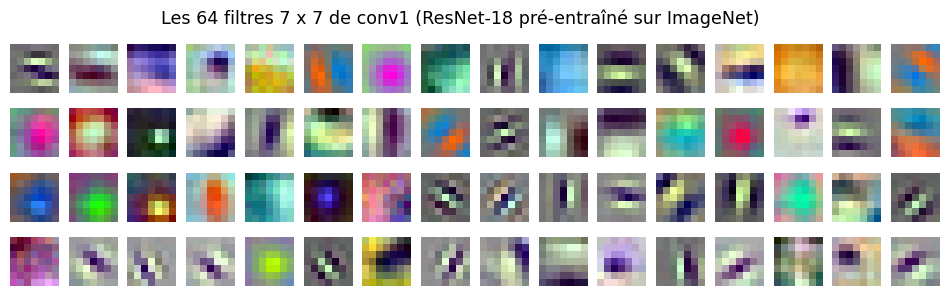

✅ Ex 21.27 : maps_27(…, layer1) : 64 cartes de 56 x 56.
✅ Ex 21.27 : maps_27(…, layer1) contre les couches appelées une à une : un tableau (1, 64, 56, 56), comme attendu.
✅ Ex 21.27 : le hook est retiré après l'appel.
✅ Ex 21.27 : maps_27(…, layer4) : 512 cartes de 7 x 7.


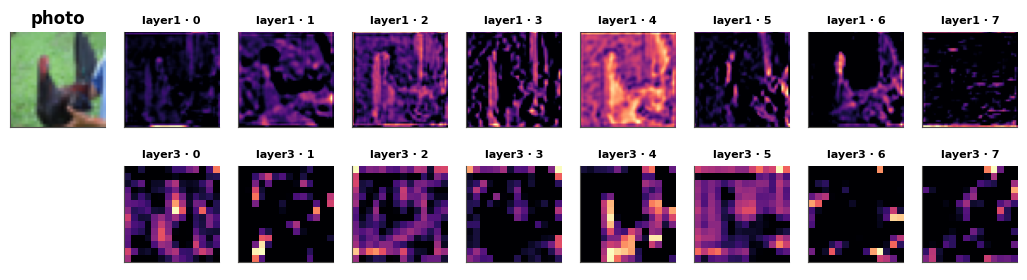

photo 0 (bird): ImageNet says 'toy terrier' (22%)
photo 1 (cat): ImageNet says 'muzzle' (15%)
photo 2 (ship): ImageNet says 'moving van' (24%)
photo 3 (ship): ImageNet says 'amphibian' (20%)


In [65]:
def filters_27(model):
    """The 64 filters of model.conv1 as an array (64, 7, 7, 3) to display as images: the channels last, and each
    filter rescaled to [0, 1] by its own minimum and maximum."""
    w = model.conv1.weight.detach().cpu().double().permute(0, 2, 3, 1).numpy()    # (64, 3, 7, 7) -> (64, 7, 7, 3)
    low = w.min(axis=(1, 2, 3), keepdims=True)
    high = w.max(axis=(1, 2, 3), keepdims=True)
    return (w - low) / (high - low)


def maps_27(model, x, layer):
    """The output of `layer` (a module of `model`, e.g. model.layer1) when the model runs on x, in evaluation mode and
    without autograd, captured by a forward hook that is removed before returning (even after an error)."""
    captured = {}
    hook = layer.register_forward_hook(lambda module, inputs, output: captured.setdefault("out", output.detach()))
    try:
        model.eval()
        with torch.no_grad():
            model(x)
    finally:
        hook.remove()
    return captured["out"]


if RESNET_27 is None:
    print("⏳ Ex 21.27 : pas de ResNet-18 pré-entraîné ici (voir la cellule précédente).")
else:
    with checked("21.27"):
        f_27 = filters_27(RESNET_27)
        if returned("21.27", "filters_27", f_27):
            f_27 = as_numpy(f_27)
            ok_27 = f_27 is not None and f_27.shape == (64, 7, 7, 3)
            verdict("21.27", ok_27, "filters_27 rend 64 filtres 7 x 7 en couleur, canaux à la fin.",
                    f"filters_27 : attendu un tableau (64, 7, 7, 3), reçu {None if f_27 is None else f_27.shape}.")
            if ok_27:
                verdict("21.27", np.allclose(f_27.min(axis=(1, 2, 3)), 0) and np.allclose(f_27.max(axis=(1, 2, 3)), 1),
                        "chaque filtre va de 0 à 1 (son propre minimum et son propre maximum).",
                        "chaque filtre doit aller exactement de 0 à 1 : ramène-le par SON minimum et SON maximum, pas ceux des 64.")
                w_27 = RESNET_27.conv1.weight.detach().double()
                verdict("21.27", np.allclose(np.argsort(f_27[5].ravel()), np.argsort(w_27[5].permute(1, 2, 0).numpy().ravel())),
                        "l'ordre des valeurs d'un filtre est conservé (un simple changement d'échelle).",
                        "les valeurs d'un filtre ne sont plus dans le même ordre : as-tu permuté les axes autrement que (64, 7, 7, 3) ?")
                fig, axes = plt.subplots(4, 16, figsize=(12, 3.2))
                for ax, filt in zip(axes.ravel(), f_27):
                    ax.imshow(filt)
                    ax.axis("off")
                fig.suptitle("Les 64 filtres 7 x 7 de conv1 (ResNet-18 pré-entraîné sur ImageNet)")
                plt.show()
    with checked("21.27"):
        x_27 = INPUT_27[:1]
        m1_27 = maps_27(RESNET_27, x_27, RESNET_27.layer1)
        if returned("21.27", "maps_27", m1_27):
            verdict("21.27", tuple(m1_27.shape) == (1, 64, 56, 56), "maps_27(…, layer1) : 64 cartes de 56 x 56.",
                    f"maps_27(…, layer1) : attendu la forme (1, 64, 56, 56), reçu {tuple(np.shape(m1_27))}.")
            with torch.no_grad():
                r = RESNET_27
                want_27 = r.layer1(r.maxpool(r.relu(r.bn1(r.conv1(x_27)))))
            same("21.27", "maps_27(…, layer1) contre les couches appelées une à une", m1_27, want_27, rtol=1e-5, atol=1e-5)
            verdict("21.27", len(RESNET_27.layer1._forward_hooks) == 0, "le hook est retiré après l'appel.",
                    "un hook reste attaché à layer1 : retire-le (hook.remove()), sinon chaque appel en ajoute un.")
            m4_27 = maps_27(RESNET_27, x_27, RESNET_27.layer4)
            verdict("21.27", tuple(m4_27.shape) == (1, 512, 7, 7), "maps_27(…, layer4) : 512 cartes de 7 x 7.",
                    f"maps_27(…, layer4) : attendu (1, 512, 7, 7), reçu {tuple(np.shape(m4_27))}.")
            m3_27 = maps_27(RESNET_27, x_27, RESNET_27.layer3)
            fig, axes = plt.subplots(2, 9, figsize=(13, 3.2))
            axes[0, 0].imshow(PHOTOS_27[0].permute(1, 2, 0))
            axes[0, 0].set_title("photo")
            axes[1, 0].axis("off")
            for k in range(8):
                axes[0, k + 1].imshow(m1_27[0, k], cmap="magma")
                axes[0, k + 1].set_title(f"layer1 · {k}", fontsize=8)
                axes[1, k + 1].imshow(m3_27[0, k], cmap="magma")
                axes[1, k + 1].set_title(f"layer3 · {k}", fontsize=8)
            for ax in axes.ravel():
                ax.set_xticks([])
                ax.set_yticks([])
            plt.show()
    with torch.no_grad():
        probs_27 = RESNET_27(INPUT_27).softmax(dim=1)
    for k, (p_27, c_27) in enumerate(zip(*probs_27.max(dim=1))):
        print(f"photo {k} ({wb.datasets.CIFAR10_CLASSES[Y_27[k]]}): ImageNet says {WEIGHTS_27.meta['categories'][c_27]!r} ({p_27:.0%})")

💡 Les filtres de `conv1` sont ceux qu'on trouve à la première couche de presque tous les CNN entraînés sur des photos : des bords orientés, des rayures et des taches de couleur. `layer3` vient après quatre réductions par 2 (224 → 112 → 56 → 28 → 14) : ses cartes sont petites, et chaque case résume un grand champ récepteur, d'où des réponses à des motifs plus complexes. Les photos de CIFAR-10 font 32 × 32 pixels, agrandies sept fois : bien plus floues que les photos d'ImageNet, et leurs classes (« camion », « cheval ») ne sont pas celles d'ImageNet (1 000 classes, dont plus d'une centaine de races de chiens) : le réseau répond par la classe ImageNet la plus proche, souvent fausse. C'est pourquoi on fait un *fine-tuning* plutôt que de prendre le réseau tel quel (bonus B1).

### Ex 21.28 — Ce qu'un filtre cherche : montée de gradient sur l'entrée 📦 ★★★ ⏱️ 45 min
**Objectif :** fabriquer, par montée de gradient sur les pixels, les images qui excitent le plus des filtres et des classes de ton convnet.  
**Prérequis :** Ex 21.22 · Ex 21.27 · ch. 5 (montée de gradient) · fiche §21.9.2 (et son encadré 🧮) · **Fil rouge :** Fashion-MNIST · **Parcours :** M, C

La méthode du §21.9.2 sur ton convnet entraîné `model_22` (21.22) : on part d'une image presque grise et on la modifie pas à pas pour faire répondre le plus possible un filtre donné, les poids du réseau restant fixés.

**Contrat**
- `ascent_28(model, upto, channel, steps=60, lr=0.1, seed=0)` rend l'image `(1, 1, 28, 28)`, de valeurs dans $[0, 1]$, qui fait répondre le plus le canal `channel` de `model[:upto + 1]` (les couches 0 à `upto` du `nn.Sequential`), mesuré par la **moyenne** de ce canal sur ses positions ;
- départ : `0.4 + 0.2 * torch.rand(1, 1, 28, 28, generator=torch.Generator().manual_seed(seed))` (en `float32`) ; à chaque pas : la loss $-$moyenne, la passe arrière, un pas de `torch.optim.Adam([x], lr)`, puis l'image ramenée dans $[0, 1]$ ;
- le modèle est en mode évaluation ; ses poids ne changent pas et ne reçoivent **aucun** gradient (leur `.grad` reste ce qu'il était) ; le résultat est détaché du graphe.

La vérification lance ta fonction sur le filtre 0 de la deuxième convolution (`upto=2`, avant sa ReLU), contrôle l'image, les poids et leurs gradients, compare la réponse du filtre à celle de 500 vraies images, puis affiche les motifs des huit premiers filtres et les images qui maximisent quatre classes (`upto=10`, les logits).

Dans tes notes : les motifs des filtres ressemblent-ils à des vêtements ? Et les images des classes ? Pourquoi une image qui fait répondre la classe « Trouser » plus fort que n'importe quel vrai pantalon ne ressemble-t-elle pas forcément à un pantalon ?

✅ Ex 21.28 : ascent_28 rend une image (1, 1, 28, 28).
✅ Ex 21.28 : l'image reste dans [0, 1] et ne garde pas son graphe (detach).
✅ Ex 21.28 : les poids du modèle et leurs gradients n'ont pas bougé.
channel 0 of the second convolution: start -0.788 -> found 0.384 (best of 500 real images: 0.237)
✅ Ex 21.28 : l'image trouvée excite ce filtre plus qu'aucune des 500 images réelles.


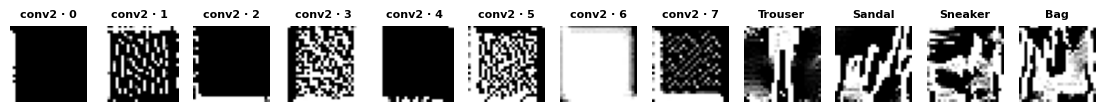

In [66]:
def ascent_28(model, upto, channel, steps=60, lr=0.1, seed=0):
    """The (1, 1, 28, 28) image, in [0, 1], that makes the channel `channel` of model[:upto + 1] respond as much as
    possible (its mean over the positions), found by gradient ascent on the PIXELS.

    Start: 0.4 + 0.2 * torch.rand(1, 1, 28, 28, generator=torch.Generator().manual_seed(seed)), in float32. Each step:
    the loss -mean(model[:upto + 1](x)[0, channel]), backward, a step of torch.optim.Adam([x], lr), then x clamped
    to [0, 1]. The model is in evaluation mode; its weights do not change and receive no gradient. Returns a detached
    tensor.
    """
    part = model[:upto + 1]
    model.eval()
    frozen = [p.requires_grad for p in model.parameters()]
    for p in model.parameters():
        p.requires_grad_(False)                              # the weights are fixed: only the image is optimised
    x = 0.4 + 0.2 * torch.rand(1, 1, 28, 28, generator=torch.Generator().manual_seed(seed))
    x = x.to(DEVICE).requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    try:
        for _ in range(steps):
            optimizer.zero_grad()
            loss = -part(x)[0, channel].mean()               # ascent: minimise the opposite
            loss.backward()
            optimizer.step()
            with torch.no_grad():
                x.clamp_(0.0, 1.0)                           # stay a valid image
    finally:
        for p, flag in zip(model.parameters(), frozen):
            p.requires_grad_(flag)
    return x.detach()


if model_22 is None:
    print("⏳ Ex 21.28 : il faut d'abord le modèle entraîné de 21.22 (model_22).")
else:
    with checked("21.28"):
        before_28 = copy.deepcopy(model_22.state_dict())
        grads_28 = [None if p.grad is None else p.grad.clone() for p in model_22.parameters()]
        img_28 = ascent_28(model_22, 2, 0)
        if returned("21.28", "ascent_28", img_28):
            ok_28 = isinstance(img_28, torch.Tensor) and tuple(img_28.shape) == (1, 1, 28, 28)
            verdict("21.28", ok_28, "ascent_28 rend une image (1, 1, 28, 28).",
                    f"ascent_28 doit rendre un tenseur (1, 1, 28, 28), reçu {type(img_28).__name__} {tuple(np.shape(img_28))}.")
            if ok_28:
                verdict("21.28", float(img_28.min()) >= 0 and float(img_28.max()) <= 1 and not img_28.requires_grad,
                        "l'image reste dans [0, 1] et ne garde pas son graphe (detach).",
                        f"l'image va de {float(img_28.min()):.3f} à {float(img_28.max()):.3f}"
                        f"{' et garde son graphe' if img_28.requires_grad else ''} : clamp à chaque pas, puis detach.")
                same_w_28 = all(torch.equal(before_28[k], v) for k, v in model_22.state_dict().items())
                same_g_28 = all((g is None and p.grad is None) or (g is not None and p.grad is not None and torch.equal(g, p.grad))
                                for g, p in zip(grads_28, model_22.parameters()))
                verdict("21.28", same_w_28 and same_g_28, "les poids du modèle et leurs gradients n'ont pas bougé.",
                        "les poids ou leurs gradients ont changé : seule l'image est optimisée (requires_grad_(False) le "
                        "temps du calcul, un optimiseur qui ne contient que x).")
                start_28 = 0.4 + 0.2 * torch.rand(1, 1, 28, 28, generator=torch.Generator().manual_seed(0))
                with torch.no_grad():
                    gain_28 = (model_22[:3](img_28.to(DEVICE))[0, 0].mean() - model_22[:3](start_28.to(DEVICE))[0, 0].mean()).item()
                    real_28 = model_22[:3](X_VAL[:500].to(DEVICE))[:, 0].mean(dim=(1, 2)).max().item()
                    found_28 = model_22[:3](img_28.to(DEVICE))[0, 0].mean().item()
                print(f"channel 0 of the second convolution: start {found_28 - gain_28:.3f} -> found {found_28:.3f} "
                      f"(best of 500 real images: {real_28:.3f})")
                verdict("21.28", found_28 > real_28, "l'image trouvée excite ce filtre plus qu'aucune des 500 images réelles.",
                        "l'image trouvée n'excite pas ce filtre plus que des images réelles : la montée de gradient a-t-elle "
                        "le bon signe (-moyenne) et le bon nombre de pas ?")
                patterns_28 = [ascent_28(model_22, 2, c) for c in range(8)] + [ascent_28(model_22, 10, c) for c in (1, 5, 7, 8)]
                fig, axes = plt.subplots(1, 12, figsize=(14, 1.8))
                titles_28 = [f"conv2 · {c}" for c in range(8)] + [CLASSES[c] for c in (1, 5, 7, 8)]
                for ax, img, title in zip(axes, patterns_28, titles_28):
                    ax.imshow(img[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
                    ax.set_title(title, fontsize=8)
                    ax.axis("off")
                plt.show()

💡 Certains canaux de la deuxième convolution donnent des textures répétées (rayures, grilles, grains) : chaque position du filtre est poussée vers son motif ; d'autres donnent une image presque uniforme, noire ou blanche : ils répondent au fond ou à l'encre, partout. Aucun ne ressemble à un vêtement. Les images des classes gardent au mieux quelques traces de forme, mais restent étranges : la montée de gradient trouve ce qui fait monter le **score**, pas ce qui ressemble aux exemples ; sans régularisation (flou, décalages aléatoires, prior appris), elle exploite des détails que le réseau trouve décisifs et qu'aucune vraie image n'a. C'est la même faiblesse que celle des exemples adversariaux (21.29).

### Ex 21.29 — Attaque FGSM contre ton CNN Fashion-MNIST 📦 ★★★ ⏱️ 40 min
**Objectif :** fabriquer des exemples adversariaux par FGSM et mesurer l'accuracy de ton convnet en fonction de ε.  
**Prérequis :** Ex 21.22 · fiche §21.10, section « Au-delà du livre : l'attaque FGSM » · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

L'attaque FGSM de la fiche contre ton convnet entraîné `model_22` (21.22) : un pas de taille $\varepsilon$ dans le sens du **signe** du gradient de la loss par rapport aux **pixels**.

**Contrat**
- `fgsm_29(model, x, y, eps)` rend $\mathrm{clamp}\big(\mathbf{x} + \varepsilon\,\mathrm{sign}(\nabla_{\mathbf{x}} L), 0, 1\big)$ pour des images `x` `(N, 1, 28, 28)` dans $[0, 1]$, leurs labels `y` et la cross-entropy $L$ moyenne du mini-batch ; le modèle est en mode évaluation ; `x`, les poids du modèle et **leurs gradients** restent ce qu'ils étaient ; le résultat est détaché, de la forme de `x` ;
- `attack_curve_29(model, X, y, eps_list, batch_size=500)` rend la liste des accuracies du modèle sur les images attaquées, une par valeur de `eps_list` (des `float` Python).

La vérification compare ta fonction à la formule sur 200 images de validation, contrôle `x`, les gradients des poids et le cas $\varepsilon = 0$, puis trace l'accuracy sur 1 000 images en fonction de $\varepsilon$ (de 0 à 0,2), à côté d'un bruit de même taille aux signes tirés au hasard ; elle montre six images avant et après l'attaque.

Dans tes notes : à $\varepsilon = 0{,}1$, les images attaquées te paraissent-elles encore faciles à reconnaître ? Pourquoi le bruit aléatoire de même taille fait-il si peu, quand l'attaque fait tant (pense au modèle linéaire de la fiche) ? Quelles parades aideraient ici, et à quel prix ?

✅ Ex 21.29 : fgsm_29 rend des images de la forme de x.
✅ Ex 21.29 : fgsm_29(…, eps=0.05) contre la formule de la fiche : un tableau (200, 1, 28, 28), comme attendu.
✅ Ex 21.29 : x n'est pas modifié.
✅ Ex 21.29 : les gradients des poids n'ont pas bougé.


✅ Ex 21.29 : fgsm_29(…, eps=0) rend x : un tableau (200, 1, 28, 28), comme attendu.


✅ Ex 21.29 : attack_curve_29 rend 5 accuracies.


eps          : [0.0, 0.02, 0.05, 0.1, 0.2]
FGSM         : [0.855, 0.752, 0.59, 0.31, 0.05]
random signs : [0.855, 0.858, 0.853, 0.839, 0.809]
✅ Ex 21.29 : à eps = 0,1, FGSM fait tomber l'accuracy à 0.31, du bruit de même taille seulement à 0.84.


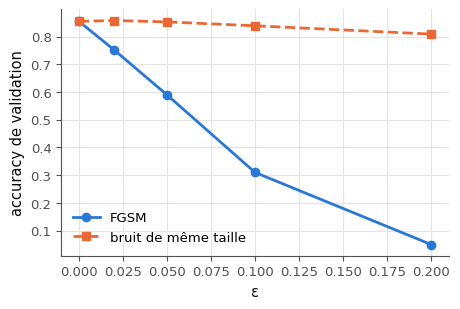

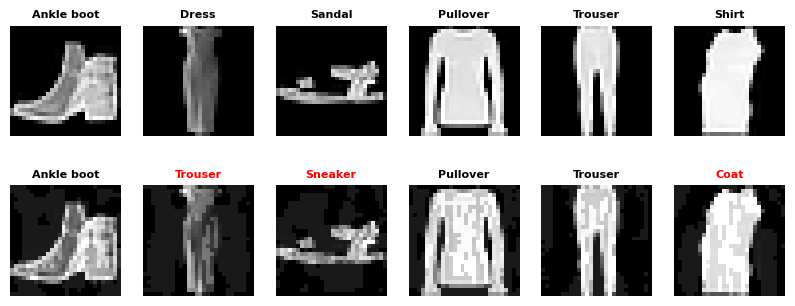

In [67]:
def fgsm_29(model, x, y, eps):
    """FGSM: x + eps * sign(gradient of the cross-entropy loss with respect to x), clamped to [0, 1].

    x: (N, 1, 28, 28) images in [0, 1], y: (N,) labels. The model is in evaluation mode; x, the weights of the model
    and their gradients are left as they were. Returns a detached tensor of the shape of x.
    """
    model.eval()
    x = x.clone().detach().to(DEVICE).requires_grad_(True)
    loss = nn.functional.cross_entropy(model(x), y.to(DEVICE))
    (grad,) = torch.autograd.grad(loss, x)                   # only the gradient with respect to x: the weights' .grad stay
    return (x + eps * grad.sign()).clamp(0.0, 1.0).detach()


def attack_curve_29(model, X, y, eps_list, batch_size=500):
    """The accuracy of `model` on the FGSM images of (X, y), for each eps of eps_list: a list of Python floats."""
    curve = []
    for eps in eps_list:
        correct = 0
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size], y[i:i + batch_size]
            adv = fgsm_29(model, xb, yb, eps)
            with torch.no_grad():
                correct += (model(adv).argmax(dim=1).cpu() == yb).sum().item()
        curve.append(correct / len(X))
    return curve


EPS_29 = [0.0, 0.02, 0.05, 0.1, 0.2]
if model_22 is None:
    print("⏳ Ex 21.29 : il faut d'abord le modèle entraîné de 21.22 (model_22).")
else:
    with checked("21.29"):
        x_29, y_29 = X_VAL[:200].clone(), Y_VAL[:200].clone()
        before_x_29 = x_29.clone()
        grads_29 = [None if p.grad is None else p.grad.clone() for p in model_22.parameters()]
        adv_29 = fgsm_29(model_22, x_29, y_29, 0.05)
        if returned("21.29", "fgsm_29", adv_29):
            ok_29 = isinstance(adv_29, torch.Tensor) and tuple(adv_29.shape) == tuple(x_29.shape)
            verdict("21.29", ok_29, "fgsm_29 rend des images de la forme de x.",
                    f"fgsm_29 doit rendre un tenseur {tuple(x_29.shape)}, reçu {type(adv_29).__name__} {tuple(np.shape(adv_29))}.")
            if ok_29:
                adv_29 = adv_29.cpu()
                x_ref_29 = x_29.clone().to(DEVICE).requires_grad_(True)
                (g_29,) = torch.autograd.grad(nn.functional.cross_entropy(model_22.eval()(x_ref_29), y_29.to(DEVICE)), x_ref_29)
                want_29 = (x_ref_29 + 0.05 * g_29.sign()).clamp(0, 1).detach().cpu()
                same("21.29", "fgsm_29(…, eps=0.05) contre la formule de la fiche", adv_29, want_29, rtol=0, atol=1e-6)
                verdict("21.29", torch.equal(x_29, before_x_29), "x n'est pas modifié.", "fgsm_29 a modifié x : travaille sur une copie.")
                same_g_29 = all((g is None and p.grad is None) or (g is not None and p.grad is not None and torch.equal(g, p.grad))
                                for g, p in zip(grads_29, model_22.parameters()))
                verdict("21.29", same_g_29, "les gradients des poids n'ont pas bougé.",
                        "les gradients des poids ont changé : seul le gradient par rapport à x sert (torch.autograd.grad).")
                same("21.29", "fgsm_29(…, eps=0) rend x", fgsm_29(model_22, x_29, y_29, 0.0).cpu(), x_29)
    with checked("21.29"):
        curve_29 = attack_curve_29(model_22, X_VAL[:1000], Y_VAL[:1000], EPS_29)
        if returned("21.29", "attack_curve_29", curve_29):
            ok_c29 = isinstance(curve_29, list) and len(curve_29) == len(EPS_29) and all(isinstance(v, float) for v in curve_29)
            verdict("21.29", ok_c29, f"attack_curve_29 rend {len(EPS_29)} accuracies.",
                    f"attack_curve_29 doit rendre une liste de {len(EPS_29)} float Python, reçu {curve_29!r:.120}.")
            if ok_c29:
                gen_29 = torch.Generator().manual_seed(29)
                noise_29 = []
                for eps in EPS_29:                 # the same budget, a random sign instead of the sign of the gradient
                    signs = torch.randint(0, 2, X_VAL[:1000].shape, generator=gen_29) * 2.0 - 1.0
                    noise_29.append(accuracy(model_22, (X_VAL[:1000] + eps * signs).clamp(0, 1), Y_VAL[:1000]))
                print("eps          :", EPS_29)
                print("FGSM         :", [round(v, 3) for v in curve_29])
                print("random signs :", [round(v, 3) for v in noise_29])
                verdict("21.29", curve_29[3] < noise_29[3] - 0.3,
                        f"à eps = 0,1, FGSM fait tomber l'accuracy à {curve_29[3]:.2f}, du bruit de même taille seulement à {noise_29[3]:.2f}.",
                        f"à eps = 0,1, FGSM donne {curve_29[3]:.2f} et du bruit de même taille {noise_29[3]:.2f} : l'attaque devrait faire bien pire.")
                plt.figure(figsize=(5, 3.2))
                plt.plot(EPS_29, curve_29, "o-", label="FGSM")
                plt.plot(EPS_29, noise_29, "s--", label="bruit de même taille")
                plt.xlabel("ε")
                plt.ylabel("accuracy de validation")
                plt.legend()
                plt.show()
                adv_show_29 = fgsm_29(model_22, X_VAL[:6], Y_VAL[:6], 0.1).cpu()
                with torch.no_grad():
                    p_clean_29 = model_22(X_VAL[:6].to(DEVICE)).argmax(1).cpu()
                    p_adv_29 = model_22(adv_show_29.to(DEVICE)).argmax(1).cpu()
                fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
                for k in range(6):
                    axes[0, k].imshow(X_VAL[k, 0], cmap="gray", vmin=0, vmax=1)
                    axes[0, k].set_title(CLASSES[p_clean_29[k]], fontsize=8)
                    axes[1, k].imshow(adv_show_29[k, 0], cmap="gray", vmin=0, vmax=1)
                    axes[1, k].set_title(CLASSES[p_adv_29[k]], fontsize=8, color="red" if p_adv_29[k] != p_clean_29[k] else "black")
                for ax in axes.ravel():
                    ax.axis("off")
                plt.show()

💡 À $\varepsilon = 0{,}1$, un humain reconnaît encore tous les vêtements, alors que l'accuracy du réseau s'effondre. Le bruit aléatoire change le score d'un neurone de façon désordonnée : les contributions des pixels se compensent, et leur somme grandit comme $\sqrt{n}$ ; l'attaque aligne chaque pixel sur le signe du gradient, et l'effet grandit comme $n$ (le $\varepsilon\sum_j \lvert w_j\rvert$ de la fiche). Parades : l'entraînement adversarial (entraîner sur des exemples attaqués, PGD), au prix d'un entraînement plusieurs fois plus long et d'une accuracy un peu plus basse sur les images propres ; les défenses qui masquent le gradient se contournent.

### Ex 21.30 — conv_transpose2d par insertion de zéros 🔨 ★★★ ⏱️ 50 min
**Objectif :** écrire la convolution transposée par la recette de la fiche (insérer des zéros, compléter, retourner le noyau).  
**Prérequis :** Ex 21.15 · ✏️ 21.6 · fiche §21.8 · **mylearn :** `conv.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `conv_transpose2d(x, weight, bias=None, stride=1, padding=0)`, la convolution transposée de `F.conv_transpose2d`. **Contrat** :
- `x` a la forme `(N, C_in, H, W)` ; `weight` a la forme `(C_in, C_out, k_h, k_w)`, la disposition des convolutions **transposées** de PyTorch (les canaux d'entrée d'abord) ; `bias` a la forme `(C_out,)` ou vaut `None` ;
- la sortie a la forme `(N, C_out, (H - 1) s_h - 2 p_h + k_h, (W - 1) s_w - 2 p_w + k_w)` ; `padding` retire $p$ lignes (ou colonnes) de **chaque** bord de la sortie, avec $0 \le p \le k - 1$ sur chaque axe ;
- elle lève `ValueError` pour : un poids qui n'a pas quatre axes ou dont `shape[0]` n'est pas `C_in` ; un biais d'une autre forme que `(C_out,)`, même diffusable ; un stride < 1 ; un padding hors de $[0, k - 1]$ sur l'un des axes (même si la sortie existerait) ; une sortie vide.

La première cellule compare quatre cas à `F.conv_transpose2d` (dont un stride par axe et un padding) et essaie trois refus ; la seconde lance les tests (`-k "test_conv_transpose2d_"`).

In [68]:
with checked("21.30"):
    C = mylearn.conv
    rng_30 = np.random.default_rng(30)
    x_30 = rng_30.normal(size=(2, 3, 4, 5))
    for label_30, shape_30, kw_30, bias_30 in [("stride 2", (3, 2, 3, 3), dict(stride=2), True),
                                              ("stride 2, padding 1, noyau 4", (3, 4, 4, 4), dict(stride=2, padding=1), False),
                                              ("stride (2, 1) et padding (1, 0), noyau 3 x 2", (3, 2, 3, 2), dict(stride=(2, 1), padding=(1, 0)), True),
                                              ("stride 1 (la passe arrière d'une convolution)", (3, 2, 2, 2), dict(), False)]:
        w_30 = rng_30.normal(size=shape_30)
        b_30 = rng_30.normal(size=shape_30[1]) if bias_30 else None
        out_30 = C.conv_transpose2d(x_30, w_30, b_30, **kw_30)
        if not returned("21.30", "conv_transpose2d", out_30):
            break
        want_30 = F.conv_transpose2d(torch.tensor(x_30), torch.tensor(w_30), None if b_30 is None else torch.tensor(b_30), **kw_30)
        same("21.30", f"conv_transpose2d, {label_30}, contre F.conv_transpose2d", out_30, want_30)
    refuses("21.30", "un padding de 3 pour un noyau de 3", lambda: C.conv_transpose2d(x_30, np.ones((3, 1, 3, 3)), padding=3))
    refuses("21.30", "un stride de 0", lambda: C.conv_transpose2d(x_30, np.ones((3, 1, 3, 3)), stride=0))
    refuses("21.30", "un poids dont shape[0] n'est pas C_in", lambda: C.conv_transpose2d(x_30, np.ones((2, 1, 3, 3))))

✅ Ex 21.30 : conv_transpose2d, stride 2, contre F.conv_transpose2d : un tableau (2, 2, 9, 11), comme attendu.
✅ Ex 21.30 : conv_transpose2d, stride 2, padding 1, noyau 4, contre F.conv_transpose2d : un tableau (2, 4, 8, 10), comme attendu.
✅ Ex 21.30 : conv_transpose2d, stride (2, 1) et padding (1, 0), noyau 3 x 2, contre F.conv_transpose2d : un tableau (2, 2, 7, 6), comme attendu.
✅ Ex 21.30 : conv_transpose2d, stride 1 (la passe arrière d'une convolution), contre F.conv_transpose2d : un tableau (2, 2, 5, 6), comme attendu.
✅ Ex 21.30 : un padding de 3 pour un noyau de 3 : ValueError levée (padding (3, 3) must be between 0 and k - 1 = (2, 2)).
✅ Ex 21.30 : un stride de 0 : ValueError levée (stride must be >= 1, got 0).
✅ Ex 21.30 : un poids dont shape[0] n'est pas C_in : ValueError levée (weight of shape (2, 1, 3, 3) expects C_in=2 (input channels first), got x with C_in=3).


In [69]:
if written(lambda: mylearn.conv.conv_transpose2d(np.ones((1, 1, 1, 1)), np.ones((1, 1, 1, 1)))):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_conv_transpose2d_")
else:
    print("⏳ Ex 21.30 : les tests attendent ta fonction.")

pytest: 29 passed, 181 deselected in 1.22s


### Ex 21.31 — conv2d_backward : rétropropager à travers une convolution 🔨 ★★★★ ⏱️ 100 min
**Objectif :** écrire les gradients d'une convolution par rapport à son entrée, à ses poids et à son biais.  
**Prérequis :** Ex 21.15 · ∂ 21.7 · ch. 18 (passe arrière d'une couche) · fiche, section « Au-delà du livre : la rétropropagation d'une convolution » · **mylearn :** `conv.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/conv.py` (créé par `python tools/start_chapter.py 21`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules, et aucun n'est ignoré). La première cellule de vérification recharge ta librairie et compare quelques cas à `torch.nn.functional` ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch21_conv.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes (d'entiers aussi) comme des tableaux, et ne modifient **jamais** leurs entrées ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64`, jamais une entrée ni une vue d'une entrée (même pour un padding de 0 ou un noyau 1 × 1) ; un argument « int ou tuple de 2 ints » accepte les deux formes, le premier nombre valant pour les lignes (H) et le second pour les colonnes (W) ; une taille de noyau, un stride ou une dilatation < 1, un padding négatif et une fenêtre qui ne tient pas lèvent `ValueError`.

Écris `conv2d_backward(dout, x, weight, stride=1, padding=0)`, les gradients de `conv2d` (sans groupes ni dilatation) que calcule l'autograd de PyTorch. **Contrat** :
- `dout` a la forme de la sortie de la passe avant `(N, C_out, H_out, W_out)` ; `x` la forme `(N, C_in, H, W)` ; `weight` la forme `(C_out, C_in, k_h, k_w)` ; `stride` et `padding` sont ceux de la passe avant (des entiers ou des couples) ;
- elle rend le triplet `(dx, dW, db)`, de formes `(N, C_in, H, W)`, `(C_out, C_in, k_h, k_w)` et `(C_out,)` : $\partial L/\partial W$ et $\partial L/\partial b$ **somment** sur toutes les positions et toutes les images (∂ 21.7 question 7) ;
- un pixel de `x` qu'aucune fenêtre ne lit (un stride qui ne tombe pas juste) reçoit un gradient **nul** ;
- un `dout` d'une autre forme que la sortie de la passe avant lève `ValueError`, même s'il a le même nombre de valeurs ou serait diffusable.

La première cellule compare `dx`, `dW` et `db` à l'autograd de PyTorch dans quatre cas (dont un stride qui laisse des pixels hors de toute fenêtre) et essaie un `dout` de mauvaise forme ; la seconde lance les tests (`-k "test_conv2d_backward_"`).

In [70]:
with checked("21.31"):
    C = mylearn.conv
    rng_31 = np.random.default_rng(31)
    for label_31, x_shape_31, w_shape_31, kw_31 in [("stride 1, sans padding", (2, 3, 6, 5), (4, 3, 3, 3), dict()),
                                                     ("stride 2, padding 1", (2, 2, 7, 6), (3, 2, 3, 3), dict(stride=2, padding=1)),
                                                     ("stride 2 qui laisse des pixels hors de toute fenêtre", (1, 2, 6, 6), (2, 2, 3, 3), dict(stride=2)),
                                                     ("stride (1, 2), padding (2, 0), noyau 2 x 3", (2, 1, 5, 7), (2, 1, 2, 3), dict(stride=(1, 2), padding=(2, 0)))]:
        x_31 = torch.tensor(rng_31.normal(size=x_shape_31), requires_grad=True)
        w_31 = torch.tensor(rng_31.normal(size=w_shape_31), requires_grad=True)
        b_31 = torch.zeros(w_shape_31[0], dtype=torch.float64, requires_grad=True)
        out_31 = F.conv2d(x_31, w_31, b_31, **kw_31)
        dout_31 = torch.tensor(rng_31.normal(size=tuple(out_31.shape)))
        gx_31, gw_31, gb_31 = torch.autograd.grad(out_31, (x_31, w_31, b_31), dout_31)
        result_31 = C.conv2d_backward(dout_31.numpy(), x_31.detach().numpy(), w_31.detach().numpy(), **kw_31)
        if not returned("21.31", "conv2d_backward", result_31):
            break
        dx_31, dw_31, db_31 = pair("21.31", "conv2d_backward", result_31, names=("dx", "dW", "db"))
        same("21.31", f"dx, {label_31}, contre l'autograd de PyTorch", dx_31, gx_31)
        same("21.31", f"dW, {label_31}", dw_31, gw_31)
        same("21.31", f"db, {label_31}", db_31, gb_31)
    refuses("21.31", "un dout de la mauvaise forme", lambda: C.conv2d_backward(np.ones((1, 1, 3, 3)), np.ones((1, 1, 4, 4)), np.ones((1, 1, 3, 3))))

✅ Ex 21.31 : dx, stride 1, sans padding, contre l'autograd de PyTorch : un tableau (2, 3, 6, 5), comme attendu.
✅ Ex 21.31 : dW, stride 1, sans padding : un tableau (4, 3, 3, 3), comme attendu.
✅ Ex 21.31 : db, stride 1, sans padding : [2.14739782, 0.15907394, 6.23113225, 0.69445853], comme attendu.
✅ Ex 21.31 : dx, stride 2, padding 1, contre l'autograd de PyTorch : un tableau (2, 2, 7, 6), comme attendu.
✅ Ex 21.31 : dW, stride 2, padding 1 : un tableau (3, 2, 3, 3), comme attendu.
✅ Ex 21.31 : db, stride 2, padding 1 : [-4.04509489, 2.62112873, -0.4419637], comme attendu.
✅ Ex 21.31 : dx, stride 2 qui laisse des pixels hors de toute fenêtre, contre l'autograd de PyTorch : un tableau (1, 2, 6, 6), comme attendu.
✅ Ex 21.31 : dW, stride 2 qui laisse des pixels hors de toute fenêtre : un tableau (2, 2, 3, 3), comme attendu.
✅ Ex 21.31 : db, stride 2 qui laisse des pixels hors de toute fenêtre : [-2.40397001, 2.42331668], comme attendu.
✅ Ex 21.31 : dx, stride (1, 2), padding (2, 0), no

In [71]:
if written(lambda: mylearn.conv.conv2d_backward(np.ones((1, 1, 1, 1)), np.ones((1, 1, 1, 1)), np.ones((1, 1, 1, 1)))):
    run_pytest_group(TEST_FILE, impl="ref", keyword="test_conv2d_backward_")
else:
    print("⏳ Ex 21.31 : les tests attendent ta fonction.")

pytest: 22 passed, 188 deselected in 1.30s


### Ex 21.32 — Défi Fashion-MNIST : au moins 92 % avec moins de 100 000 paramètres 🏆 ★★★★ ⏱️ 120 min
**Objectif :** atteindre 92 % sur le test de Fashion-MNIST avec un CNN de moins de 100 000 paramètres, dans un temps d'entraînement limité.  
**Prérequis :** Ex 21.22 · Ex 21.23 · ch. 19 (plannings), ch. 20 (batchnorm, dropout) · fiche §21.9 · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Les 60 000 images d'entraînement de Fashion-MNIST (`X_ALL_32`, un tenseur `(60000, 1, 28, 28)` de valeurs dans $[0, 1]$, et leurs labels), et un **test caché** de 10 000 images. Le convnet du livre (21.22) dépasse 92 % sur la validation après une douzaine d'epochs, avec 1,2 million de paramètres ; le MLP du défi du ch. 20 plafonnait vers 90 %. Écris `train_32(X, y)`, qui entraîne un CNN avec PyTorch et rend le modèle entraîné : un `nn.Module` qui transforme des images `(N, 1, 28, 28)` en 10 logits. Tu choisis l'architecture, la régularisation, l'optimiseur, le planning, la taille des mini-batches.

Règles : **moins de 100 000 paramètres** ; un temps d'entraînement d'au plus `TIME_LIMIT_32` secondes sur ta machine (150 s en mode rapide, 10 minutes en mode complet) ; le défi est réussi avec une accuracy d'au moins `GOAL_32` sur le test caché : **92 % en mode complet**, 90 % en mode rapide, où le temps est plus court ; palier 🌟 : 93 % en mode complet, 92 % en mode rapide. 🚀 En mode complet, un GPU Colab est conseillé. Règle d'honneur : `train_32` entraîne vraiment le réseau (pas de poids préparés à l'avance), ne lit jamais `X_HIDDEN_32`, et n'utilise pas le test caché pour régler ta méthode : garde une partie des images d'entraînement comme validation pendant tes essais. La vérification ne révèle le test qu'une fois par session et par architecture (et seulement si ton réseau atteint l'objectif sur des images d'entraînement), et fige le résultat.

Dans tes notes : ta démarche (ce que tu as essayé, dans quel ordre, avec quelle validation), ce qui a le plus compté (la batchnorm, la largeur des convolutions, la taille de la couche dense, le planning, le nombre d'epochs), et où se trouvent les paramètres de ton réseau.

In [72]:
X_ALL_32, Y_ALL_32 = (torch.from_numpy(a) for a in wb.datasets.load_fashion_mnist("train", normalize=True, seed=None))
X_ALL_32 = X_ALL_32.unsqueeze(1)                                   # the 60 000 training images, (N, 1, 28, 28)
X_HIDDEN_32, Y_HIDDEN_32 = (torch.from_numpy(a) for a in wb.datasets.load_fashion_mnist("test", normalize=True, seed=None))
X_HIDDEN_32 = X_HIDDEN_32.unsqueeze(1)                             # the hidden test: do not look
MAX_PARAMS_32 = 100_000
TIME_LIMIT_32, GOAL_32, STAR_32 = (150.0, 0.90, 0.92) if FAST_MODE else (600.0, 0.92, 0.93)
print("train:", tuple(X_ALL_32.shape), "· hidden test:", tuple(X_HIDDEN_32.shape),
      f"· goal {GOAL_32:.0%} in {TIME_LIMIT_32:.0f} s at most, fewer than {MAX_PARAMS_32:_} parameters".replace("_", " "))

train: (60000, 1, 28, 28) · hidden test: (10000, 1, 28, 28) · goal 90% in 150 s at most, fewer than 100 000 parameters


In [73]:
def train_32(X, y):
    """Train a CNN on the Fashion-MNIST images X (a float32 tensor (60000, 1, 28, 28), values in [0, 1]) and their
    labels y (int64), with PyTorch, and return the trained model: an nn.Module that maps (N, 1, 28, 28) images to
    (N, 10) logits. Fewer than 100 000 parameters; at most TIME_LIMIT_32 seconds of training."""
    torch.manual_seed(32)
    model = nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),     # 28 -> 14
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 14 -> 7
        nn.Flatten(), nn.Dropout(0.3), nn.Linear(32 * 7 * 7, 48), nn.ReLU(), nn.Linear(48, 10)).to(DEVICE)
    epochs, batch = (8, 128) if FAST_MODE else (25, 128)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=epochs * math.ceil(len(X) / batch))
    generator = torch.Generator().manual_seed(32)
    model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(X), generator=generator).split(batch):
            loss = nn.functional.cross_entropy(model(X[idx].to(DEVICE)), y[idx].to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
    return model.eval()


if True:
    started_32 = time.perf_counter()
    model_32 = train_32(X_ALL_32, Y_ALL_32)
    seconds_32 = time.perf_counter() - started_32
    if not isinstance(model_32, nn.Module):
        print(f"❌ Ex 21.32 : train_32 doit rendre le modèle entraîné, un nn.Module ; reçu {type(model_32).__name__}.")
    else:
        count_32 = n_params(model_32)
        ok_32 = count_32 < MAX_PARAMS_32 and seconds_32 <= TIME_LIMIT_32
        verdict("21.32", count_32 < MAX_PARAMS_32, f"{count_32:_} paramètres (moins de 100 000).".replace("_", " "),
                f"{count_32:_} paramètres : le défi en permet moins de 100 000.".replace("_", " "))
        verdict("21.32", seconds_32 <= TIME_LIMIT_32, f"entraînement en {seconds_32:.0f} s (au plus {TIME_LIMIT_32:.0f} s).",
                f"entraînement en {seconds_32:.0f} s : le défi en permet au plus {TIME_LIMIT_32:.0f} (moins d'epochs, un réseau plus léger).")
        if ok_32:
            train_acc_32 = accuracy(model_32, X_ALL_32[:10_000], Y_ALL_32[:10_000])
            print(f"accuracy on 10 000 training images: {train_acc_32:.4f}")
            ok_32 = train_acc_32 >= GOAL_32
            if not ok_32:
                print(f"❌ Ex 21.32 : moins de {GOAL_32:.0%} sur des images d'entraînement : le test caché n'est pas révélé ; "
                      "améliore d'abord l'entraînement.")
        if ok_32:
            REVEALED_32 = globals().get("REVEALED_32") or {}
            leaves_32 = [m for m in model_32.modules() if not list(m.children())]
            signature_32 = tuple((type(m).__name__, tuple(p.shape for p in m.parameters(recurse=False))) for m in leaves_32)
            if signature_32 not in REVEALED_32:                    # revealed once per architecture and per session (an honour rule)
                REVEALED_32[signature_32] = (accuracy(model_32, X_HIDDEN_32, Y_HIDDEN_32), round(seconds_32))
            test_32, time_32 = REVEALED_32[signature_32]
            print(f"hidden test: {test_32:.4f} (revealed once per session for this architecture, trained in {time_32} s; "
                  "a second run of the same architecture shows the same frozen result)")
            verdict("21.32", test_32 >= GOAL_32,
                    f"défi réussi : au moins {GOAL_32:.0%} sur les 10 000 images du test caché, avec moins de 100 000 paramètres."
                    + (f" 🌟 Palier atteint : au moins {STAR_32:.0%}." if test_32 >= STAR_32 else ""),
                    f"pas encore : il faut au moins {GOAL_32:.0%} sur le test caché.")

✅ Ex 21.32 : 80 698 paramètres (moins de 100 000).
✅ Ex 21.32 : entraînement en 87 s (au plus 150 s).


accuracy on 10 000 training images: 0.9483


hidden test: 0.9226 (revealed once per session for this architecture, trained in 87 s; a second run of the same architecture shows the same frozen result)
✅ Ex 21.32 : défi réussi : au moins 90% sur les 10 000 images du test caché, avec moins de 100 000 paramètres. 🌟 Palier atteint : au moins 92%.


💡 La référence : deux blocs convolution 3 × 3 + batchnorm + ReLU + max pooling (16 puis 32 filtres), un dropout de 0,3, une couche dense de 48 neurones, 80 698 paramètres (dont 75 312 dans la première couche dense) ; AdamW et un planning *one-cycle*, 8 epochs en mode rapide, 25 en mode complet. Les chiffres (temps, test) et les essais de calibrage sont dans `05_solutions.md`.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer la forme de sortie et le nombre de paramètres d'une couche de convolution, avec padding, stride et dilatation ?
2. Sais-tu expliquer le partage de poids, le champ récepteur et ce que font une convolution 1 × 1 et une convolution transposée ?
3. Sais-tu dire comment on regarde ce que voit un filtre, et comment on fabrique un exemple adversarial ?

**Pour aller plus loin** : les notes de CS231n sur les réseaux convolutifs et le guide de Dumoulin et Visin, cités dans la fiche. La suite : le ch. 22, les réseaux récurrents.